In [2]:
import cv2
import subprocess
import matplotlib.pyplot as plt
from IPython.display import Video, display
import numpy as np
import os

## Read videos

In [ ]:
# Embedded video (works in Jupyter)
video_path = '../data/videos/P1.mp4'
if os.path.exists(video_path):
    display(Video(video_path, embed=True, width=640))
else:
    print('Video not found:', video_path)

# If you want to stream frames (outside notebook), use cv2.VideoCapture as in scripts.

In [2]:
# Get fps and basic info
video_path = '../data/videos/P1.mp4'
cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    print('Cannot open', video_path)
else:
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duration_sec = frame_count / fps if fps > 0 else None
    print(f'FPS={fps}, frames={frame_count}, duration(s)={duration_sec:.2f}')
cap.release()

FPS=35.99074097120243, frames=22413, duration(s)=622.74


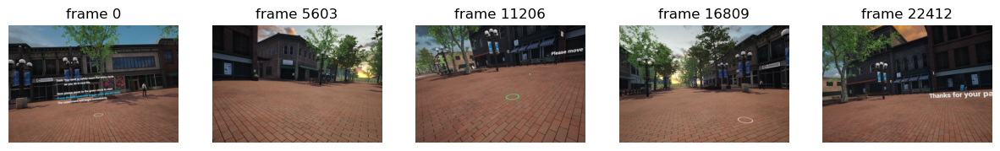

In [10]:
# Sample and show/save frames evenly across the video
def sample_frames(path, n_samples=5, out_dir=None):
    cap = cv2.VideoCapture(path)
    if not cap.isOpened():
        print('Cannot open', path)
        return []
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    if total == 0:
        cap.release()
        print('Video has 0 frames')
        return []
    # idxs = np.linspace(0, max(0, total-1), n_samples, dtype=int)
    idxs = np.arange(n_samples)
    frames = []
    if out_dir:
        os.makedirs(out_dir, exist_ok=True)
    for i in idxs:
        cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
        ret, frame = cap.read()
        if not ret:
            continue
        rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        frames.append((int(i), rgb))
        if out_dir:
            fname = os.path.join(out_dir, f'frame_{i:06d}.jpg')
            cv2.imwrite(fname, frame)
    cap.release()
    return frames

# show sampled frames
sampled_5 = sample_frames('../data/videos/P1.mp4', n_samples=5, out_dir='../data/frames/P1')
if sampled:
    fig, axs = plt.subplots(1, len(sampled), figsize=(15, 5))
    for ax, (i, fr) in zip(axs, sampled):
        ax.imshow(fr)
        ax.set_title(f'frame {i}')
        ax.axis('off')
    plt.show()
else:
    print('No frames sampled')

In [9]:
sampled[0][1].shape

(1068, 1536, 3)

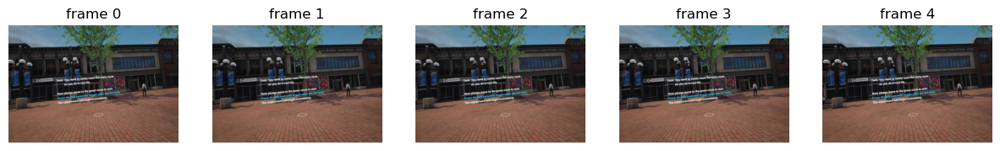

In [12]:
if sampled_5:
    fig, axs = plt.subplots(1, len(sampled_5), figsize=(15, 5))
    for ax, (i, fr) in zip(axs, sampled_5):
        ax.imshow(fr)
        ax.set_title(f'frame {i}')
        ax.axis('off')
    plt.show()
else:
    print('No frames sampled')

## Clip videos

In [ ]:
import glob
import pandas as pd

def get_start_end_in_first_valid_trial(pid, sid):
    file = glob.glob(f'../data/vrdata/combined/P{pid}_*.csv')
    print(file)
    if len(file) != 1:
        raise ValueError(f"File error")
    # Get the first valid trial
    df = pd.read_csv(file[0])
    if not df[df['Scenario'] == sid].empty:
        start = df[df['Scenario'] == sid]['TimeElapsed'].min()
        end = df[df['Scenario'] == sid]['TimeElapsed'].max()
        return start, end
    raise ValueError(f"No valid trial for P{pid} in S{sid}")

In [37]:
# Get fps and basic info
video_path = '../data/rawvideos/P1.mp4'
cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    print('Cannot open', video_path)
else:
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duration_sec = frame_count / fps if fps > 0 else None
    print(f'FPS={fps}, frames={frame_count}, duration(s)={duration_sec:.2f}')
# cap.release()

FPS=35.99074097120243, frames=22413, duration(s)=622.74


In [38]:
5*60*36

10800

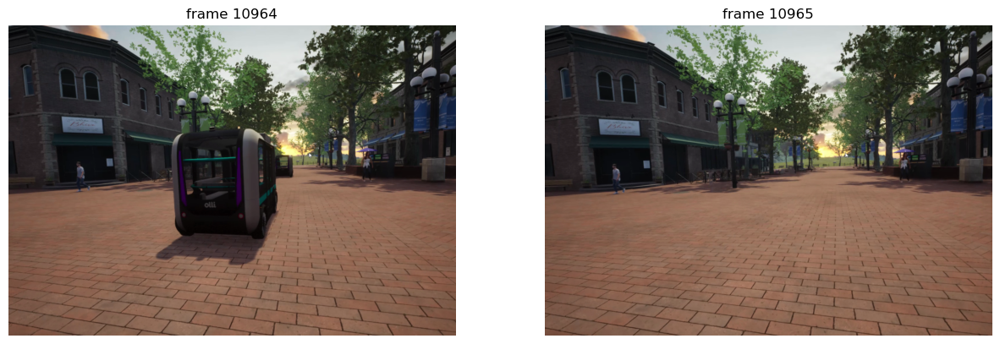

In [39]:
frames = []
for i in [10964, 10965]:
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
    ret, frame = cap.read()
    if not ret:
        continue
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    frames.append((int(i), rgb))


fig, axs = plt.subplots(1, len(frames), figsize=(15, 5))
for ax, (i, fr) in zip(axs, frames):
    ax.imshow(fr)
    ax.set_title(f'frame {i}')
    ax.axis('off')
plt.show()

# 10764 - 10964

In [5]:
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
fps = cap.get(cv2.CAP_PROP_FPS)
start_frame = 10764
end_frame = 10964
start_frame, end_frame

(10764, 10964)

In [47]:
# --- Prepare output writer ---
output_path = "clipped.mp4"
fourcc = cv2.VideoWriter_fourcc(*'mp4v')
out = cv2.VideoWriter(output_path, fourcc, fps, (width, height))

# --- Skip frames before start ---
cap.set(cv2.CAP_PROP_POS_FRAMES, start_frame)

# --- Write frames in range ---
for i in range(start_frame, end_frame):
    ret, frame = cap.read()
    if not ret:
        break
    out.write(frame)

# --- Cleanup ---
cap.release()
out.release()
print(f"Saved clipped video to {output_path}")

Saved clipped video to clipped.mp4


In [8]:
start_frame/fps, end_frame/fps

(299.07692116182574, 304.63390594744124)

In [21]:
299.068733 + 5.441395

304.510128

In [32]:
299.096533 + 5.441395

304.537928

In [68]:
# command = [
#     "ffmpeg",
#     "-ss", str(start_frame/fps),
#     "-to", str(end_frame/fps),
#     "-i", '../data/rawvideos/P1.mp4',
#     "-c", "copy",
#     "-avoid_negative_ts", "1",
#     output_path
# ]

# start_time = 299.124300
# end_time = 304.626967
# output_path = "../data/videoclips/P1S1.mp4"

# start_time = 299.124300 + start_s2 - start
# end_time = 299.124300 + (end_s2 - start)
# output_path = "../data/videoclips/P1S2.mp4"

start_time = 299.124300 + start_s3 - start
end_time = 299.124300 + (end_s3 - start)
output_path = "../data/videoclips/P1S3.mp4"

command = [
    "ffmpeg",
    "-i", '../data/rawvideos/P1.mp4',
    "-ss", str(start_time), # 
    "-to", str(end_time), # 626967, 654767, 682567
    # "-avoid_negative_ts", "1",
    output_path
]

subprocess.run(command, stdout=subprocess.DEVNULL, stderr=subprocess.STDOUT)
print(f"Clipped frames {start_time}–{end_time} saved to {output_path}")

Clipped frames 335.3590289999999–342.90970599999997 saved to ../data/videoclips/P1S3.mp4


In [66]:
1/30

0.03333333333333333

In [50]:
304.626967 - 299.124300

5.502666999999974

In [67]:
start = 313.513266
end_s1 = 318.954661
start_s2 = 332.194421
end_s2 = 337.446538
start_s3 = 349.717995 + 0.03
end_s3 = 357.268672 + 0.03

In [52]:
start_s2 - start

18.68115499999999

In [27]:
10764 / 35.99074097120243

299.07692116182574

In [34]:
5.44*36

195.84

In [28]:
318.954661 - 313.513266

5.441395

In [59]:
# Get fps and basic info
video_path = '../data/videoclips/P1S2.mp4'
cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    print('Cannot open', video_path)
else:
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duration_sec = frame_count / fps if fps > 0 else None
    print(f'FPS={fps}, frames={frame_count}, duration(s)={duration_sec:.2f}')
# cap.release()

FPS=29.97002997002997, frames=158, duration(s)=5.27


In [61]:
end_s2 - start_s2

5.252116999999998

In [58]:
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
width, height 

(1536, 1068)

In [49]:
# Get fps and basic info
video_path = '../data/videoclips/P1S1_6.mp4'
cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    print('Cannot open', video_path)
else:
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duration_sec = frame_count / fps if fps > 0 else None
    print(f'FPS={fps}, frames={frame_count}, duration(s)={duration_sec:.2f}')
# cap.release()

## TODO: problem is because the -ss and -to are not accurate enough... 

FPS=29.97002997002997, frames=168, duration(s)=5.61


In [23]:
def get_frame_time(video_path, frame_index):
    container = av.open(video_path)
    stream = container.streams.video[0]
    
    # Decode frames one by one until we reach the desired index
    for i, frame in enumerate(container.decode(stream)):
        if i == frame_index:
            timestamp = float(frame.pts * stream.time_base)
            container.close()
            return timestamp
    container.close()
    raise IndexError("Frame index out of range")

def get_frame_time_fast(video_path, frame_index):
    container = av.open(video_path)
    stream = container.streams.video[0]
    
    # Roughly estimate where to seek (using average frame rate)
    avg_fps = float(stream.average_rate)
    approx_time = frame_index / avg_fps
    container.seek(int(approx_time / stream.time_base), any_frame=True, backward=True)
    
    # Decode from that point
    for i, frame in enumerate(container.decode(stream)):
        if frame.index == frame_index:
            return float(frame.pts * stream.time_base)
    container.close()
    raise IndexError("Frame not found")

In [31]:
# Example
video_path = "../data/rawvideos/P1.mp4"
frame_index = 10764 + 1
t = get_frame_time(video_path, frame_index)
print(f"Frame {frame_index} occurs at {t:.6f} seconds")

Frame 10765 occurs at 299.096533 seconds


In [26]:
# Example
video_path = "../data/videoclips/P1.mp4"
frame_index = 10964 + 1
t = get_frame_time(video_path, frame_index)
print(f"Frame {frame_index} occurs at {t:.6f} seconds")

NameError: name 'get_frame_time' is not defined

In [17]:
304.654767 - 299.096533

5.55823399999997

In [35]:
78-42

36

## Get the first frame timepoint

### P1

In [2]:
# Get fps and basic info
filename = 'P1'
pid = 1

video_path = f'../data/rawvideos/videos/{filename}.mp4'
cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    print('Cannot open', video_path)
else:
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duration_sec = frame_count / fps if fps > 0 else None
    print(f'FPS={fps}, frames={frame_count}, duration(s)={duration_sec:.2f}')
# cap.release()

FPS=35.99074097120243, frames=22413, duration(s)=622.74


FOR PERSON 1 in VIDEO= ../data/rawvideos/P1.mp4


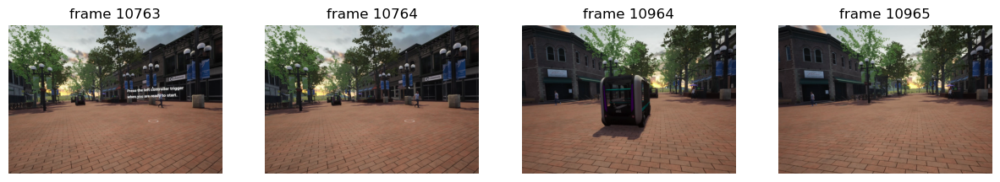

In [6]:
# find the needed frames 
print("FOR PERSON", pid, 'in VIDEO=', video_path)

frames = []
for i in [10763, 10764, 10964, 10965]:
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
    ret, frame = cap.read()
    if not ret:
        continue
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    frames.append((int(i), rgb))

fig, axs = plt.subplots(1, len(frames), figsize=(15, 5))
for ax, (i, fr) in zip(axs, frames):
    ax.imshow(fr)
    ax.set_title(f'frame {i}')
    ax.axis('off')
plt.show()

# 10764 - 10964

In [8]:
# check visually 
start = 299.124300
start_s1 = 313.513266
end_s1 = 318.954661

start_time = start
end_time = start + (end_s1 - start_s1)
output_path = f"../data/videoclips/testP{pid}S.mp4"

command = [
    "ffmpeg",
    "-y",
    "-i", f'../data/rawvideos/{filename}.mp4',
    "-ss", str(start_time), # 
    "-to", str(end_time), # 626967, 654767, 682567
    # "-avoid_negative_ts", "1",
    output_path
]

subprocess.run(command, stdout=subprocess.DEVNULL, stderr=subprocess.STDOUT)
print(f"Clipped frames {start_time}–{end_time} saved to {output_path}")

Clipped frames 299.1243–304.565695 saved to ../data/videoclips/testP1S1.mp4


### P13

In [11]:
(3*60+47)*36

8172

In [10]:
# Get fps and basic info
filename = 'P13'
pid = 13

video_path = f'../data/rawvideos/videos/{filename}.mp4'
cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    print('Cannot open', video_path)
else:
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duration_sec = frame_count / fps if fps > 0 else None
    print(f'FPS={fps}, frames={frame_count}, duration(s)={duration_sec:.2f}')
# cap.release()

FPS=35.993389607246236, frames=17731, duration(s)=492.62


FOR PERSON 13 in VIDEO= ../data/rawvideos/videos/P13.mp4


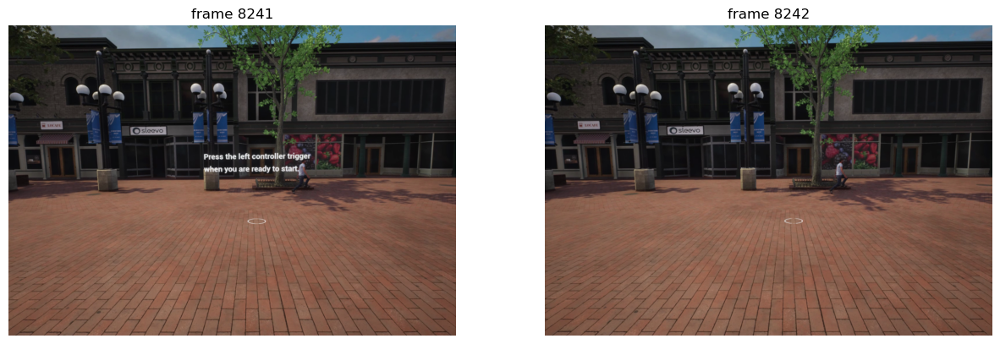

In [17]:
# find the needed frames 
print("FOR PERSON", pid, 'in VIDEO=', video_path)

frames = []
for i in [8241, 8242]: # 8241, 8242
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
    ret, frame = cap.read()
    if not ret:
        continue
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    frames.append((int(i), rgb))

fig, axs = plt.subplots(1, len(frames), figsize=(15, 5))
for ax, (i, fr) in zip(axs, frames):
    ax.imshow(fr)
    ax.set_title(f'frame {i}')
    ax.axis('off')
plt.show()

# 10764 - 10964

In [23]:
# check visually 
start = 229.027867
start_s1 = 236.193049
end_s1 = 242.687872

start_time = start
end_time = start + (end_s1 - start_s1)
output_path = f"../data/videoclips/testP{pid}S.mp4"

command = [
    "ffmpeg",
    "-y",
    "-i", f'../data/rawvideos/videos/{filename}.mp4',
    "-ss", str(start_time), 
    "-to", str(end_time), 
    output_path
]

subprocess.run(command, stdout=subprocess.DEVNULL, stderr=subprocess.STDOUT)
print(f"Clipped frames {start_time}–{end_time} saved to {output_path}")

Clipped frames 229.000067–235.49489 saved to ../data/videoclips/testP13S.mp4


### P22

In [24]:
(3*60+16)*36

7056

In [26]:
# Get fps and basic info
filename = 'P22'
pid = 22

video_path = f'../data/rawvideos/videos/{filename}.mp4'
print('VIDEO=', video_path)
cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    print('Cannot open', video_path)
else:
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duration_sec = frame_count / fps if fps > 0 else None
    print(f'FPS={fps}, frames={frame_count}, duration(s)={duration_sec:.2f}')
# cap.release()

VIDEO= ../data/rawvideos/videos/P22.mp4
FPS=35.9945119950598, frames=16006, duration(s)=444.68


FOR PERSON 22 in VIDEO= ../data/rawvideos/videos/P22.mp4


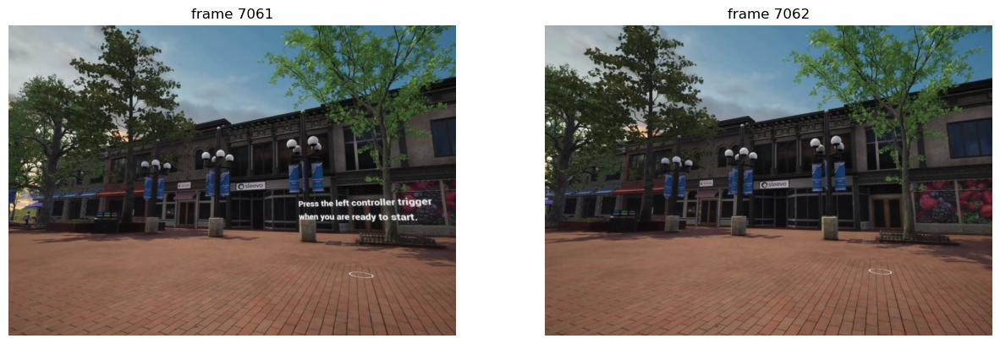

In [32]:
# find the needed frames 
print("FOR PERSON", pid, 'in VIDEO=', video_path)

frames = []
for i in [7061, 7062]:
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
    ret, frame = cap.read()
    if not ret:
        continue
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    frames.append((int(i), rgb))

fig, axs = plt.subplots(1, len(frames), figsize=(15, 5))
for ax, (i, fr) in zip(axs, frames):
    ax.imshow(fr)
    ax.set_title(f'frame {i}')
    ax.axis('off')
plt.show()

# 10764 - 10964

In [35]:
# check visually 
start = 196.238100
start_s1 = 208.382221
end_s1 = 218.631286

start_time = start
end_time = start + (end_s1 - start_s1)
output_path = f"../data/videoclips/testP{pid}S.mp4"

command = [
    "ffmpeg",
    "-y",
    "-i", f'../data/rawvideos/videos/{filename}.mp4',
    "-ss", str(start_time), # 
    "-to", str(end_time), # 626967, 654767, 682567
    # "-avoid_negative_ts", "1",
    output_path
]

subprocess.run(command, stdout=subprocess.DEVNULL, stderr=subprocess.STDOUT)
print(f"Clipped frames {start_time}–{end_time} saved to {output_path}")

Clipped frames 196.210267–206.459332 saved to ../data/videoclips/testP22S.mp4


### P2

In [37]:
(3*60+22)*36

7272

In [36]:
# Get fps and basic info
filename = 'P2'
pid = 2

video_path = f'../data/rawvideos/videos/{filename}.mp4'
print('VIDEO=', video_path)
cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    print('Cannot open', video_path)
else:
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duration_sec = frame_count / fps if fps > 0 else None
    print(f'FPS={fps}, frames={frame_count}, duration(s)={duration_sec:.2f}')
# cap.release()

VIDEO= ../data/rawvideos/videos/P2.mp4
FPS=35.99317851950238, frames=17178, duration(s)=477.26


FOR PERSON 2 in VIDEO= ../data/rawvideos/videos/P2.mp4


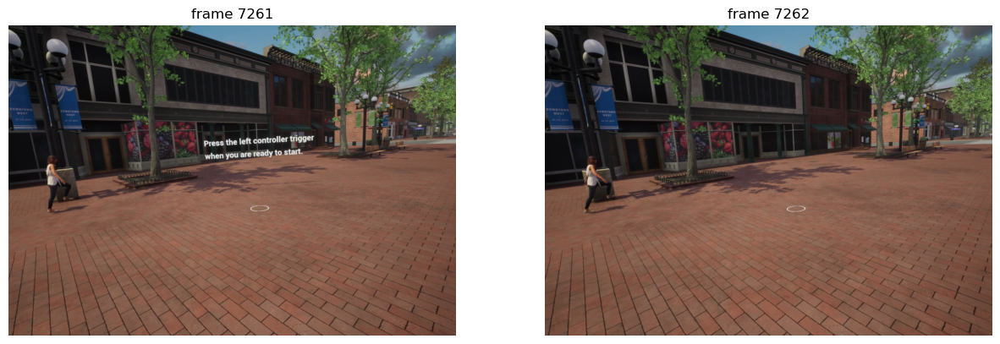

In [43]:
# find the needed frames 
print("FOR PERSON", pid, 'in VIDEO=', video_path)

frames = []
for i in [7261, 7262]:
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
    ret, frame = cap.read()
    if not ret:
        continue
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    frames.append((int(i), rgb))

fig, axs = plt.subplots(1, len(frames), figsize=(15, 5))
for ax, (i, fr) in zip(axs, frames):
    ax.imshow(fr)
    ax.set_title(f'frame {i}')
    ax.axis('off')
plt.show()

# 10764 - 10964

In [45]:
# check visually 
start = 201.790367
start_s1 = 345.372988
end_s1 = 353.474428

start_time = start
end_time = start + (end_s1 - start_s1)
output_path = f"../data/videoclips/testP{pid}S.mp4"

command = [
    "ffmpeg",
    "-y",
    "-i", f'../data/rawvideos/videos/{filename}.mp4',
    "-ss", str(start_time), # 
    "-to", str(end_time), # 626967, 654767, 682567
    # "-avoid_negative_ts", "1",
    output_path
]

subprocess.run(command, stdout=subprocess.DEVNULL, stderr=subprocess.STDOUT)
print(f"Clipped frames {start_time}–{end_time} saved to {output_path}")

Clipped frames 201.762567–209.86400699999996 saved to ../data/videoclips/testP2S.mp4


### P3

In [ ]:
(3*60+22)*36

7272

In [46]:
# Get fps and basic info
filename = 'P3'
pid = 3

video_path = f'../data/rawvideos/videos/{filename}.mp4'
print('VIDEO=', video_path)
cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    print('Cannot open', video_path)
else:
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duration_sec = frame_count / fps if fps > 0 else None
    print(f'FPS={fps}, frames={frame_count}, duration(s)={duration_sec:.2f}')
# cap.release()

VIDEO= ../data/rawvideos/videos/P3.mp4
FPS=36.00975552751911, frames=6656, duration(s)=184.84


FOR PERSON 3 in VIDEO= ../data/rawvideos/videos/P3.mp4


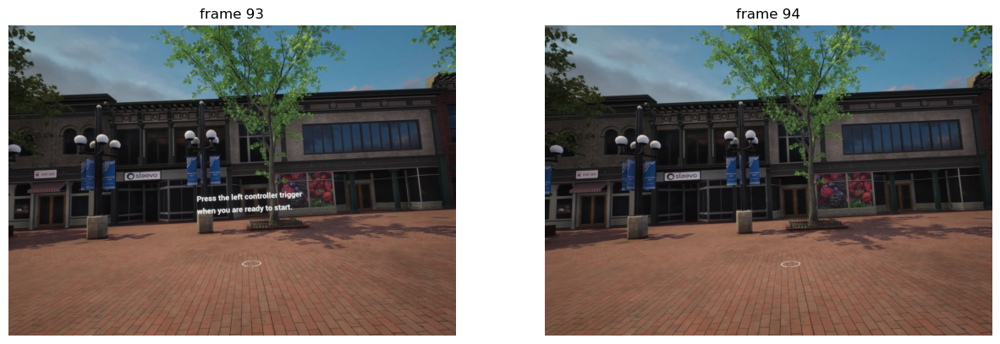

In [50]:
# find the needed frames 
print("FOR PERSON", pid, 'in VIDEO=', video_path)

frames = []
for i in [93, 94]:
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
    ret, frame = cap.read()
    if not ret:
        continue
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    frames.append((int(i), rgb))

fig, axs = plt.subplots(1, len(frames), figsize=(15, 5))
for ax, (i, fr) in zip(axs, frames):
    ax.imshow(fr)
    ax.set_title(f'frame {i}')
    ax.axis('off')
plt.show()

# 10764 - 10964

In [52]:
# check visually 
start = 2.646100
start_s1 = 467.247036
end_s1 = 474.989137

start_time = start
end_time = start + (end_s1 - start_s1)
output_path = f"../data/videoclips/testP{pid}S.mp4"

command = [
    "ffmpeg",
    "-y",
    "-i", f'../data/rawvideos/videos/{filename}.mp4',
    "-ss", str(start_time), # 
    "-to", str(end_time), # 626967, 654767, 682567
    # "-avoid_negative_ts", "1",
    output_path
]

subprocess.run(command, stdout=subprocess.DEVNULL, stderr=subprocess.STDOUT)
print(f"Clipped frames {start_time}–{end_time} saved to {output_path}")

Clipped frames 2.6461–10.388201000000048 saved to ../data/videoclips/testP3S.mp4


### P6

In [54]:
(3*60+18)*36

7128

In [53]:
# Get fps and basic info
filename = 'P6'
pid = 6

video_path = f'../data/rawvideos/videos/{filename}.mp4'
print('VIDEO=', video_path)
cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    print('Cannot open', video_path)
else:
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duration_sec = frame_count / fps if fps > 0 else None
    print(f'FPS={fps}, frames={frame_count}, duration(s)={duration_sec:.2f}')
# cap.release()

VIDEO= ../data/rawvideos/videos/P6.mp4
FPS=35.99386810856631, frames=16781, duration(s)=466.22


FOR PERSON 6 in VIDEO= ../data/rawvideos/videos/P6.mp4


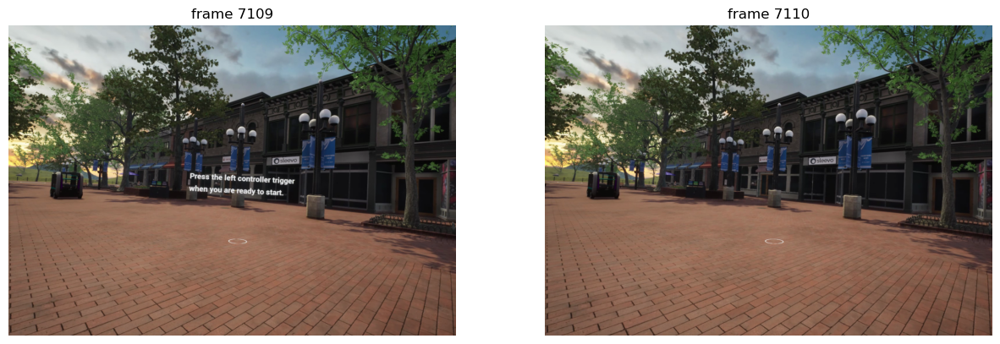

In [61]:
# find the needed frames 
print("FOR PERSON", pid, 'in VIDEO=', video_path)

frames = []
for i in [7109, 7110]:
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
    ret, frame = cap.read()
    if not ret:
        continue
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    frames.append((int(i), rgb))

fig, axs = plt.subplots(1, len(frames), figsize=(15, 5))
for ax, (i, fr) in zip(axs, frames):
    ax.imshow(fr)
    ax.set_title(f'frame {i}')
    ax.axis('off')
plt.show()

# 10764 - 10964

In [62]:
# check visually 
start = 197.575067
start_s1 = 416.686344
end_s1 = 429.183673

start_time = start
end_time = start + (end_s1 - start_s1)
output_path = f"../data/videoclips/testP{pid}S.mp4"

command = [
    "ffmpeg",
    "-y",
    "-i", f'../data/rawvideos/videos/{filename}.mp4',
    "-ss", str(start_time), # 
    "-to", str(end_time), # 626967, 654767, 682567
    # "-avoid_negative_ts", "1",
    output_path
]

subprocess.run(command, stdout=subprocess.DEVNULL, stderr=subprocess.STDOUT)
print(f"Clipped frames {start_time}–{end_time} saved to {output_path}")

Clipped frames 197.575067–210.07239599999997 saved to ../data/videoclips/testP6S.mp4


### P7

In [64]:
(5*60+44)*36

12384

In [63]:
# Get fps and basic info
filename = 'P7'
pid = 7

video_path = f'../data/rawvideos/videos/{filename}.mp4'
print('VIDEO=', video_path)
cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    print('Cannot open', video_path)
else:
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duration_sec = frame_count / fps if fps > 0 else None
    print(f'FPS={fps}, frames={frame_count}, duration(s)={duration_sec:.2f}')
# cap.release()

VIDEO= ../data/rawvideos/videos/P7.mp4
FPS=35.990687690270384, frames=22277, duration(s)=618.97


FOR PERSON 7 in VIDEO= ../data/rawvideos/videos/P7.mp4


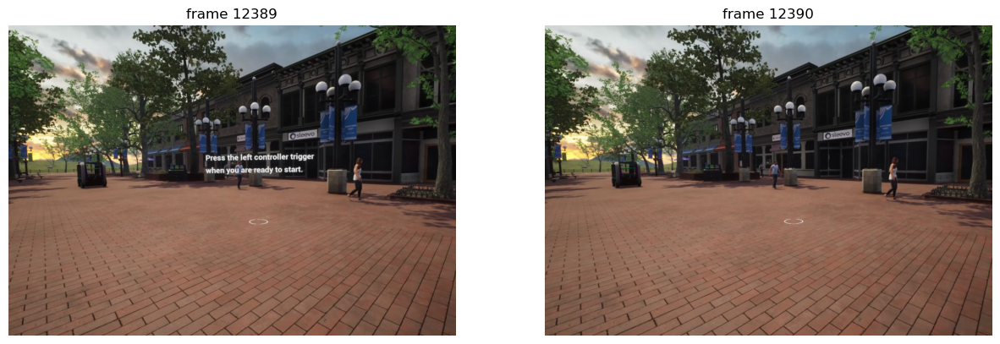

In [66]:
# find the needed frames 
print("FOR PERSON", pid, 'in VIDEO=', video_path)

frames = []
for i in [12389, 12390]:
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
    ret, frame = cap.read()
    if not ret:
        continue
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    frames.append((int(i), rgb))

fig, axs = plt.subplots(1, len(frames), figsize=(15, 5))
for ax, (i, fr) in zip(axs, frames):
    ax.imshow(fr)
    ax.set_title(f'frame {i}')
    ax.axis('off')
plt.show()

# 10764 - 10964

In [67]:
# check visually 
start = 344.320567
start_s1 = 515.702678
end_s1 = 526.286847

start_time = start
end_time = start + (end_s1 - start_s1)
output_path = f"../data/videoclips/testP{pid}S.mp4"

command = [
    "ffmpeg",
    "-y",
    "-i", f'../data/rawvideos/videos/{filename}.mp4',
    "-ss", str(start_time), # 
    "-to", str(end_time), # 626967, 654767, 682567
    # "-avoid_negative_ts", "1",
    output_path
]

subprocess.run(command, stdout=subprocess.DEVNULL, stderr=subprocess.STDOUT)
print(f"Clipped frames {start_time}–{end_time} saved to {output_path}")

Clipped frames 344.320567–354.90473599999996 saved to ../data/videoclips/testP7S.mp4


## P8

In [68]:
(4*60+9)*36

8964

In [69]:
# Get fps and basic info
filename = 'P8'
pid = 8

video_path = f'../data/rawvideos/videos/{filename}.mp4'
print('VIDEO=', video_path)
cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    print('Cannot open', video_path)
else:
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duration_sec = frame_count / fps if fps > 0 else None
    print(f'FPS={fps}, frames={frame_count}, duration(s)={duration_sec:.2f}')
# cap.release()

VIDEO= ../data/rawvideos/videos/P8.mp4
FPS=35.99190483195395, frames=20324, duration(s)=564.68


FOR PERSON 8 in VIDEO= ../data/rawvideos/videos/P8.mp4


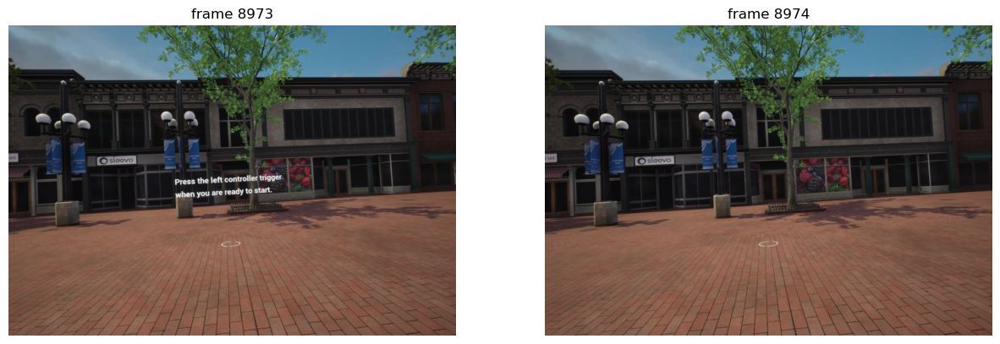

In [75]:
# find the needed frames 
print("FOR PERSON", pid, 'in VIDEO=', video_path)

frames = []
for i in [8973, 8974]:
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
    ret, frame = cap.read()
    if not ret:
        continue
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    frames.append((int(i), rgb))

fig, axs = plt.subplots(1, len(frames), figsize=(15, 5))
for ax, (i, fr) in zip(axs, frames):
    ax.imshow(fr)
    ax.set_title(f'frame {i}')
    ax.axis('off')
plt.show()

# 10764 - 10964

In [76]:
# check visually 
start = 249.372233
start_s1 = 545.357234
end_s1 = 559.349752

start_time = start
end_time = start + (end_s1 - start_s1)
output_path = f"../data/videoclips/testP{pid}S.mp4"

command = [
    "ffmpeg",
    "-y",
    "-i", f'../data/rawvideos/videos/{filename}.mp4',
    "-ss", str(start_time), # 
    "-to", str(end_time), # 626967, 654767, 682567
    # "-avoid_negative_ts", "1",
    output_path
]

subprocess.run(command, stdout=subprocess.DEVNULL, stderr=subprocess.STDOUT)
print(f"Clipped frames {start_time}–{end_time} saved to {output_path}")

Clipped frames 249.372233–263.364751 saved to ../data/videoclips/testP8S.mp4


## P19

In [78]:
(5*60+35)*36

12060

In [77]:
# Get fps and basic info
filename = 'P19'
pid = 19

video_path = f'../data/rawvideos/videos/{filename}.mp4'
print('VIDEO=', video_path)
cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    print('Cannot open', video_path)
else:
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duration_sec = frame_count / fps if fps > 0 else None
    print(f'FPS={fps}, frames={frame_count}, duration(s)={duration_sec:.2f}')
# cap.release()

VIDEO= ../data/rawvideos/videos/P19.mp4
FPS=35.99052506440644, frames=20638, duration(s)=573.43


FOR PERSON 19 in VIDEO= ../data/rawvideos/videos/P19.mp4


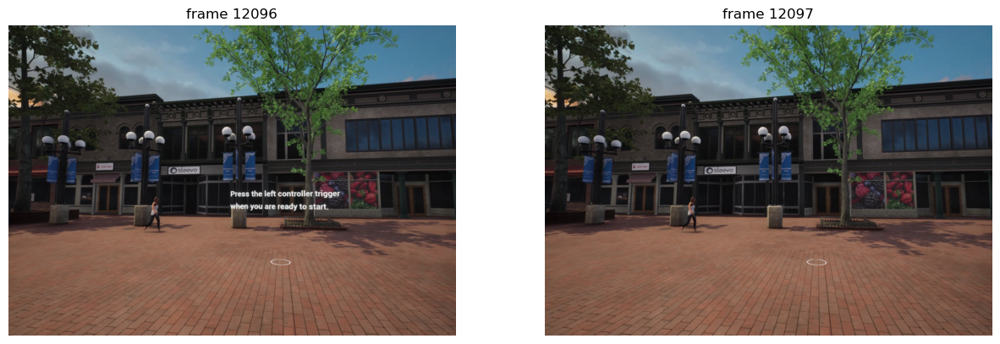

In [85]:
# find the needed frames 
print("FOR PERSON", pid, 'in VIDEO=', video_path)

frames = []
for i in [12096, 12097]:
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
    ret, frame = cap.read()
    if not ret:
        continue
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    frames.append((int(i), rgb))

fig, axs = plt.subplots(1, len(frames), figsize=(15, 5))
for ax, (i, fr) in zip(axs, frames):
    ax.imshow(fr)
    ax.set_title(f'frame {i}')
    ax.axis('off')
plt.show()

# 10764 - 10964

In [86]:
# check visually 
start = 336.181600
start_s1 = 449.085298
end_s1 = 464.431212

start_time = start
end_time = start + (end_s1 - start_s1)
output_path = f"../data/videoclips/testP{pid}S.mp4"

command = [
    "ffmpeg",
    "-y",
    "-i", f'../data/rawvideos/videos/{filename}.mp4',
    "-ss", str(start_time), # 
    "-to", str(end_time), # 626967, 654767, 682567
    # "-avoid_negative_ts", "1",
    output_path
]

subprocess.run(command, stdout=subprocess.DEVNULL, stderr=subprocess.STDOUT)
print(f"Clipped frames {start_time}–{end_time} saved to {output_path}")

Clipped frames 336.1816–351.527514 saved to ../data/videoclips/testP19S.mp4


## P28

In [88]:
(6*60+31)*36

14076

In [102]:
# Get fps and basic info
filename = 'P28'
pid = 28

video_path = f'../data/rawvideos/videos/{filename}.mp4'
print('VIDEO=', video_path)
cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    print('Cannot open', video_path)
else:
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duration_sec = frame_count / fps if fps > 0 else None
    print(f'FPS={fps}, frames={frame_count}, duration(s)={duration_sec:.2f}')
# cap.release()

VIDEO= ../data/rawvideos/videos/P28.mp4
FPS=35.99021631321928, frames=25063, duration(s)=696.38


FOR PERSON 28 in VIDEO= ../data/rawvideos/videos/P28.mp4


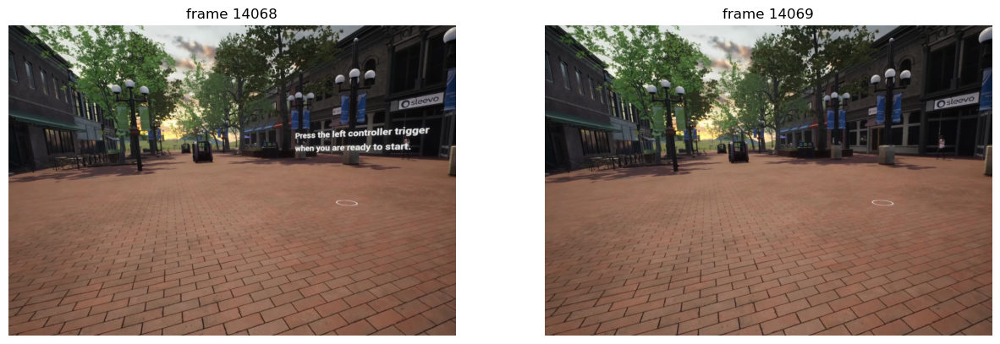

In [103]:
# find the needed frames 
print("FOR PERSON", pid, 'in VIDEO=', video_path)

frames = []
for i in [14068, 14069]:
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
    ret, frame = cap.read()
    if not ret:
        continue
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    frames.append((int(i), rgb))

fig, axs = plt.subplots(1, len(frames), figsize=(15, 5))
for ax, (i, fr) in zip(axs, frames):
    ax.imshow(fr)
    ax.set_title(f'frame {i}')
    ax.axis('off')
plt.show()

# 10764 - 10964

In [104]:
# check visually 
start = 390.974267
start_s1 = 524.046241
end_s1 = 535.340384

start_time = start
end_time = start + (end_s1 - start_s1)
output_path = f"../data/videoclips/testP{pid}S.mp4"

command = [
    "ffmpeg",
    "-y",
    "-i", f'../data/rawvideos/videos/{filename}.mp4',
    "-ss", str(start_time), # 
    "-to", str(end_time), # 626967, 654767, 682567
    # "-avoid_negative_ts", "1",
    output_path
]

subprocess.run(command, stdout=subprocess.DEVNULL, stderr=subprocess.STDOUT)
print(f"Clipped frames {start_time}–{end_time} saved to {output_path}")

Clipped frames 390.974267–402.26840999999996 saved to ../data/videoclips/testP28S.mp4


## P32

In [97]:
(4*60+21)*36

9396

In [96]:
# Get fps and basic info
filename = 'P32'
pid = 32

video_path = f'../data/rawvideos/videos/{filename}.mp4'
print('VIDEO=', video_path)
cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    print('Cannot open', video_path)
else:
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duration_sec = frame_count / fps if fps > 0 else None
    print(f'FPS={fps}, frames={frame_count}, duration(s)={duration_sec:.2f}')
# cap.release()

VIDEO= ../data/rawvideos/videos/P32.mp4
FPS=35.99325461388319, frames=17867, duration(s)=496.40


FOR PERSON 32 in VIDEO= ../data/rawvideos/videos/P32.mp4


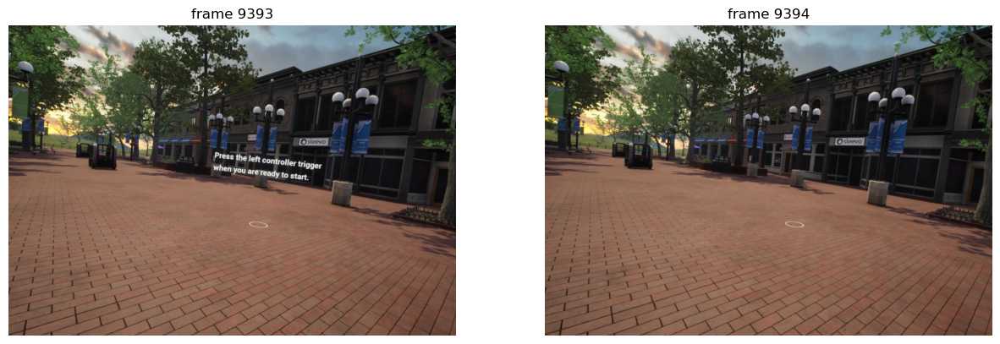

In [100]:
# find the needed frames 
print("FOR PERSON", pid, 'in VIDEO=', video_path)

frames = []
for i in [9393, 9394]:
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
    ret, frame = cap.read()
    if not ret:
        continue
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    frames.append((int(i), rgb))

fig, axs = plt.subplots(1, len(frames), figsize=(15, 5))
for ax, (i, fr) in zip(axs, frames):
    ax.imshow(fr)
    ax.set_title(f'frame {i}')
    ax.axis('off')
plt.show()

# 10764 - 10964

In [101]:
# check visually 
start = 261.045433
start_s1 = 404.490926
end_s1 = 414.688012

start_time = start
end_time = start + (end_s1 - start_s1)
output_path = f"../data/videoclips/testP{pid}S.mp4"

command = [
    "ffmpeg",
    "-y",
    "-i", f'../data/rawvideos/videos/{filename}.mp4',
    "-ss", str(start_time), # 
    "-to", str(end_time), # 626967, 654767, 682567
    # "-avoid_negative_ts", "1",
    output_path
]

subprocess.run(command, stdout=subprocess.DEVNULL, stderr=subprocess.STDOUT)
print(f"Clipped frames {start_time}–{end_time} saved to {output_path}")

Clipped frames 261.045433–271.242519 saved to ../data/videoclips/testP32S.mp4


## P35

In [106]:
(5*60+50)*36

12600

In [105]:
# Get fps and basic info
filename = 'P35'
pid = 35

video_path = f'../data/rawvideos/videos/{filename}.mp4'
print('VIDEO=', video_path)
cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    print('Cannot open', video_path)
else:
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duration_sec = frame_count / fps if fps > 0 else None
    print(f'FPS={fps}, frames={frame_count}, duration(s)={duration_sec:.2f}')
# cap.release()

VIDEO= ../data/rawvideos/videos/P35.mp4
FPS=35.99179305153134, frames=20726, duration(s)=575.85


FOR PERSON 35 in VIDEO= ../data/rawvideos/videos/P35.mp4


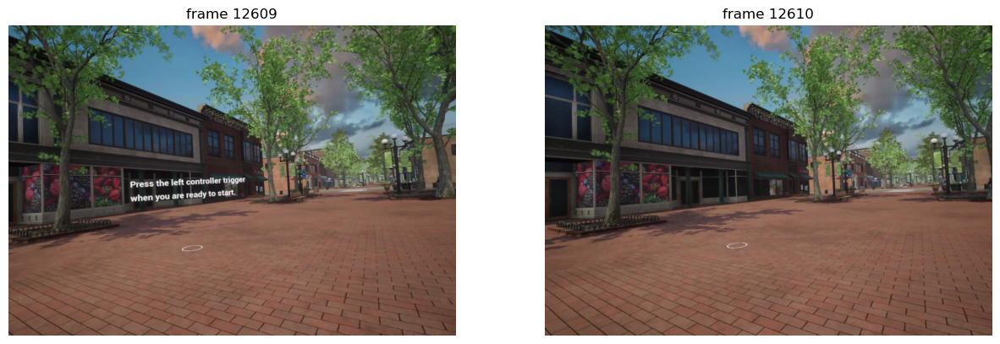

In [111]:
# find the needed frames 
print("FOR PERSON", pid, 'in VIDEO=', video_path)

frames = []
for i in [12609, 12610]:
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
    ret, frame = cap.read()
    if not ret:
        continue
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    frames.append((int(i), rgb))

fig, axs = plt.subplots(1, len(frames), figsize=(15, 5))
for ax, (i, fr) in zip(axs, frames):
    ax.imshow(fr)
    ax.set_title(f'frame {i}')
    ax.axis('off')
plt.show()

# 10764 - 10964

In [112]:
# check visually 
start = 350.417700
start_s1 = 557.936503
end_s1 = 564.33063

start_time = start
end_time = start + (end_s1 - start_s1)
output_path = f"../data/videoclips/testP{pid}S.mp4"

command = [
    "ffmpeg",
    "-y",
    "-i", f'../data/rawvideos/videos/{filename}.mp4',
    "-ss", str(start_time), # 
    "-to", str(end_time), # 626967, 654767, 682567
    # "-avoid_negative_ts", "1",
    output_path
]

subprocess.run(command, stdout=subprocess.DEVNULL, stderr=subprocess.STDOUT)
print(f"Clipped frames {start_time}–{end_time} saved to {output_path}")

Clipped frames 350.4177–356.81182700000005 saved to ../data/videoclips/testP35S.mp4


## P42

In [122]:
(5*60+15)*36

11340

In [123]:
# Get fps and basic info
filename = 'P42'
pid = 42

video_path = f'../data/rawvideos/videos/{filename}.mp4'
print('VIDEO=', video_path)
cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    print('Cannot open', video_path)
else:
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duration_sec = frame_count / fps if fps > 0 else None
    print(f'FPS={fps}, frames={frame_count}, duration(s)={duration_sec:.2f}')
# cap.release()

VIDEO= ../data/rawvideos/videos/P42.mp4
FPS=35.99160747651713, frames=19132, duration(s)=531.57


FOR PERSON 42 in VIDEO= ../data/rawvideos/videos/P42.mp4


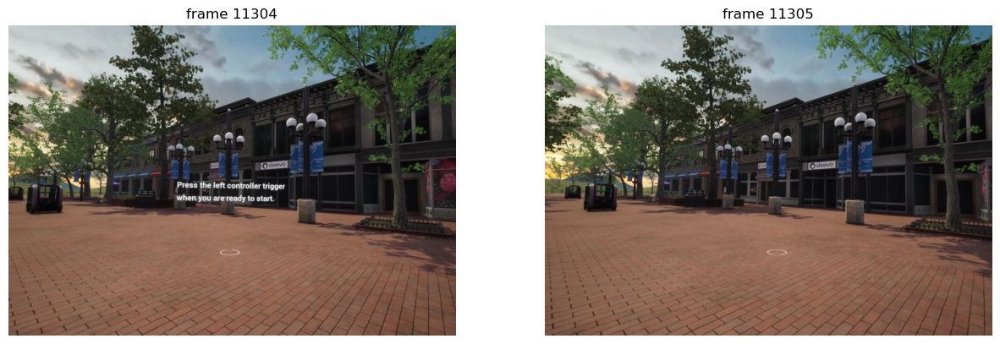

In [128]:
# find the needed frames 
print("FOR PERSON", pid, 'in VIDEO=', video_path)

frames = []
for i in [11304, 11305]:
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
    ret, frame = cap.read()
    if not ret:
        continue
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    frames.append((int(i), rgb))

fig, axs = plt.subplots(1, len(frames), figsize=(15, 5))
for ax, (i, fr) in zip(axs, frames):
    ax.imshow(fr)
    ax.set_title(f'frame {i}')
    ax.axis('off')
plt.show()

# 10764 - 10964

In [132]:
# check visually 
start = 295.963100
start_s1 = 455.189242
end_s1 = 462.027459
# start = 314.194067
# start_s1 = 473.44166
# end_s1 = 483.881104

start_time = start
end_time = start + (end_s1 - start_s1)
output_path = f"../data/videoclips/testP{pid}S.mp4"

command = [
    "ffmpeg",
    "-y",
    "-i", f'../data/rawvideos/videos/{filename}.mp4',
    "-ss", str(start_time), # 
    "-to", str(end_time), # 626967, 654767, 682567
    # "-avoid_negative_ts", "1",
    output_path
]

subprocess.run(command, stdout=subprocess.DEVNULL, stderr=subprocess.STDOUT)
print(f"Clipped frames {start_time}–{end_time} saved to {output_path}")

Clipped frames 295.9631–302.80131700000004 saved to ../data/videoclips/testP42S.mp4


In [130]:
473.44166 - 455.189242

18.252418000000034

In [131]:
314.194067 - 18.252418000000034

295.941649

## P43

In [134]:
(4*60+34)*36

9864

In [133]:
# Get fps and basic info
filename = 'P43'
pid = 43

video_path = f'../data/rawvideos/videos/{filename}.mp4'
print('VIDEO=', video_path)
cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    print('Cannot open', video_path)
else:
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duration_sec = frame_count / fps if fps > 0 else None
    print(f'FPS={fps}, frames={frame_count}, duration(s)={duration_sec:.2f}')
# cap.release()

VIDEO= ../data/rawvideos/videos/P43.mp4
FPS=35.99349467419958, frames=17442, duration(s)=484.59


FOR PERSON 43 in VIDEO= ../data/rawvideos/videos/P43.mp4


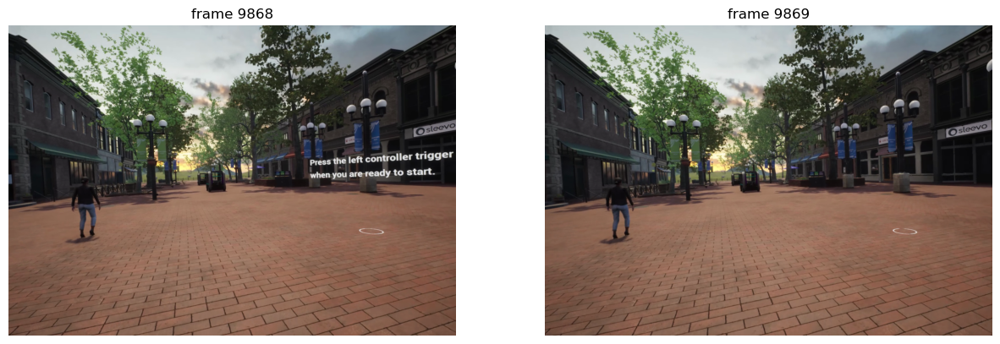

In [138]:
# find the needed frames 
print("FOR PERSON", pid, 'in VIDEO=', video_path)

frames = []
for i in [9868, 9869]:
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
    ret, frame = cap.read()
    if not ret:
        continue
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    frames.append((int(i), rgb))

fig, axs = plt.subplots(1, len(frames), figsize=(15, 5))
for ax, (i, fr) in zip(axs, frames):
    ax.imshow(fr)
    ax.set_title(f'frame {i}')
    ax.axis('off')
plt.show()

# 10764 - 10964

In [142]:
# check visually 
start = 238.788700
start_s1 = 408.398212
end_s1 = 433.2865
# start = 274.278000
# start_s1 = 443.892602
# end_s1 = 459.777457

start_time = start
end_time = start + (end_s1 - start_s1)
output_path = f"../data/videoclips/testP{pid}S.mp4"

command = [
    "ffmpeg",
    "-y",
    "-i", f'../data/rawvideos/videos/{filename}.mp4',
    "-ss", str(start_time), # 
    "-to", str(end_time), # 626967, 654767, 682567
    # "-avoid_negative_ts", "1",
    output_path
]

subprocess.run(command, stdout=subprocess.DEVNULL, stderr=subprocess.STDOUT)
print(f"Clipped frames {start_time}–{end_time} saved to {output_path}")

Clipped frames 238.7887–263.676988 saved to ../data/videoclips/testP43S.mp4


In [141]:
274.278000 - (443.892602 - 408.398212)

238.78361

## P45

In [144]:
(6*60+1)*36

12996

In [143]:
# Get fps and basic info
filename = 'P45'
pid = 45

video_path = f'../data/rawvideos/videos/{filename}.mp4'
print('VIDEO=', video_path)
cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    print('Cannot open', video_path)
else:
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duration_sec = frame_count / fps if fps > 0 else None
    print(f'FPS={fps}, frames={frame_count}, duration(s)={duration_sec:.2f}')
# cap.release()

VIDEO= ../data/rawvideos/videos/P45.mp4
FPS=35.991437657982004, frames=21594, duration(s)=599.98


FOR PERSON 45 in VIDEO= ../data/rawvideos/videos/P45.mp4


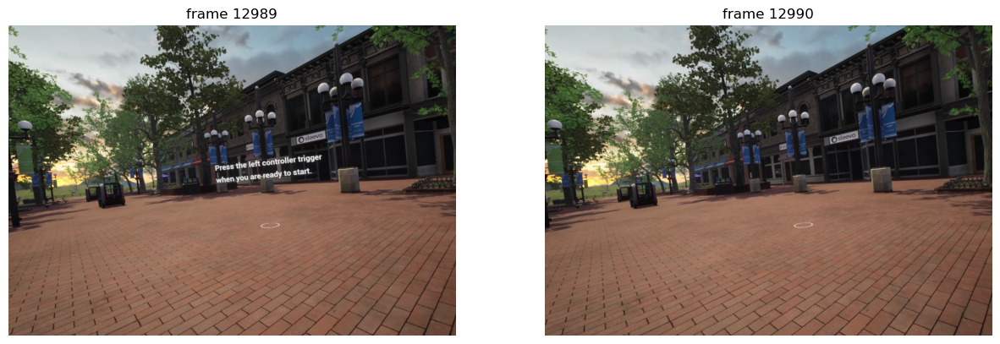

In [150]:
# find the needed frames 
print("FOR PERSON", pid, 'in VIDEO=', video_path)

frames = []
for i in [12989, 12990]:
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
    ret, frame = cap.read()
    if not ret:
        continue
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    frames.append((int(i), rgb))

fig, axs = plt.subplots(1, len(frames), figsize=(15, 5))
for ax, (i, fr) in zip(axs, frames):
    ax.imshow(fr)
    ax.set_title(f'frame {i}')
    ax.axis('off')
plt.show()

# 10764 - 10964

In [151]:
# check visually 
start = 361.009833
start_s1 = 516.951644
end_s1 = 526.94887
# start = 274.278000
# start_s1 = 443.892602
# end_s1 = 459.777457

start_time = start
end_time = start + (end_s1 - start_s1)
output_path = f"../data/videoclips/testP{pid}S.mp4"

command = [
    "ffmpeg",
    "-y",
    "-i", f'../data/rawvideos/videos/{filename}.mp4',
    "-ss", str(start_time), # 
    "-to", str(end_time), # 626967, 654767, 682567
    # "-avoid_negative_ts", "1",
    output_path
]

subprocess.run(command, stdout=subprocess.DEVNULL, stderr=subprocess.STDOUT)
print(f"Clipped frames {start_time}–{end_time} saved to {output_path}")

Clipped frames 361.009833–371.0070590000001 saved to ../data/videoclips/testP45S.mp4


## P4

In [152]:
(5*60+31)*36

11916

In [153]:
# Get fps and basic info
filename = 'P4-1'
pid = 4

video_path = f'../data/rawvideos/videos/{filename}.mp4'
print('VIDEO=', video_path)
cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    print('Cannot open', video_path)
else:
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duration_sec = frame_count / fps if fps > 0 else None
    print(f'FPS={fps}, frames={frame_count}, duration(s)={duration_sec:.2f}')
# cap.release()

VIDEO= ../data/rawvideos/videos/P4-1.mp4
FPS=35.991080639671495, frames=22308, duration(s)=619.82


FOR PERSON 4 in VIDEO= ../data/rawvideos/videos/P4-1.mp4


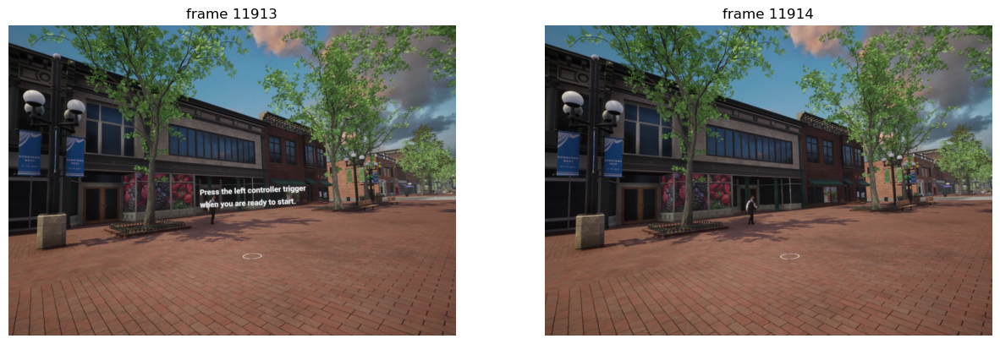

In [158]:
# find the needed frames 
print("FOR PERSON", pid, 'in VIDEO=', video_path)

frames = []
for i in [11913, 11914]:
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
    ret, frame = cap.read()
    if not ret:
        continue
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    frames.append((int(i), rgb))

fig, axs = plt.subplots(1, len(frames), figsize=(15, 5))
for ax, (i, fr) in zip(axs, frames):
    ax.imshow(fr)
    ax.set_title(f'frame {i}')
    ax.axis('off')
plt.show()

# 10764 - 10964

In [159]:
# check visually 
start = 331.084133
start_s1 = 537.276603
end_s1 = 550.911037
# start = 274.278000
# start_s1 = 443.892602
# end_s1 = 459.777457

start_time = start
end_time = start + (end_s1 - start_s1)
output_path = f"../data/videoclips/testP{pid}S.mp4"

command = [
    "ffmpeg",
    "-y",
    "-i", f'../data/rawvideos/videos/{filename}.mp4',
    "-ss", str(start_time), # 
    "-to", str(end_time), # 626967, 654767, 682567
    # "-avoid_negative_ts", "1",
    output_path
]

subprocess.run(command, stdout=subprocess.DEVNULL, stderr=subprocess.STDOUT)
print(f"Clipped frames {start_time}–{end_time} saved to {output_path}")

Clipped frames 331.084133–344.71856699999995 saved to ../data/videoclips/testP4S.mp4


In [161]:
(0*60+9)*36

324

In [160]:
# Get fps and basic info
filename = 'P4-2'
pid = 4

video_path = f'../data/rawvideos/videos/{filename}.mp4'
print('VIDEO=', video_path)
cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    print('Cannot open', video_path)
else:
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duration_sec = frame_count / fps if fps > 0 else None
    print(f'FPS={fps}, frames={frame_count}, duration(s)={duration_sec:.2f}')
# cap.release()

VIDEO= ../data/rawvideos/videos/P4-2.mp4
FPS=36.151598492985904, frames=1123, duration(s)=31.06


FOR PERSON 4 in VIDEO= ../data/rawvideos/videos/P4-2.mp4


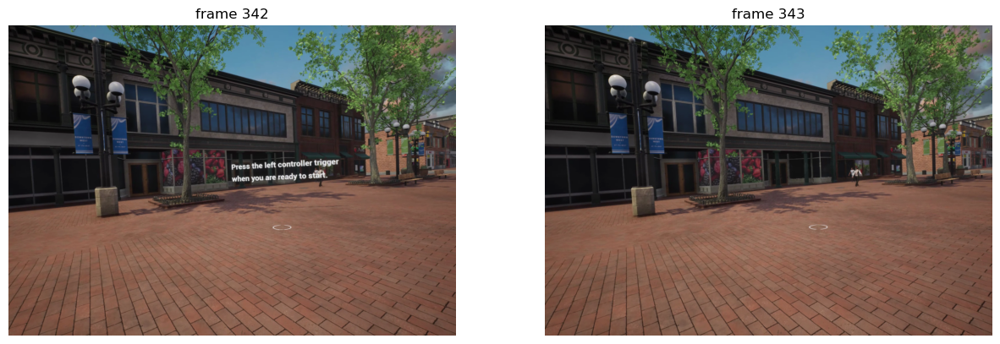

In [166]:
# find the needed frames 
print("FOR PERSON", pid, 'in VIDEO=', video_path)

frames = []
for i in [342, 343]:
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
    ret, frame = cap.read()
    if not ret:
        continue
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    frames.append((int(i), rgb))

fig, axs = plt.subplots(1, len(frames), figsize=(15, 5))
for ax, (i, fr) in zip(axs, frames):
    ax.imshow(fr)
    ax.set_title(f'frame {i}')
    ax.axis('off')
plt.show()

# 10764 - 10964

In [168]:
# check visually 
start = 9.538800
start_s1 = 18.673017
end_s1 = 35.681634

start_time = start
end_time = start + (end_s1 - start_s1)
output_path = f"../data/videoclips/testP{pid}S.mp4"

command = [
    "ffmpeg",
    "-y",
    "-i", f'../data/rawvideos/videos/{filename}.mp4',
    "-ss", str(start_time), # 
    "-to", str(end_time), # 626967, 654767, 682567
    # "-avoid_negative_ts", "1",
    output_path
]

subprocess.run(command, stdout=subprocess.DEVNULL, stderr=subprocess.STDOUT)
print(f"Clipped frames {start_time}–{end_time} saved to {output_path}")

Clipped frames 9.5388–26.547417000000003 saved to ../data/videoclips/testP4S.mp4


## P5

In [171]:
(3*60+47)*36

8172

In [170]:
# Get fps and basic info
filename = 'P5-2'
pid = 5

video_path = f'../data/rawvideos/videos/{filename}.mp4'
print('VIDEO=', video_path)
cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    print('Cannot open', video_path)
else:
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duration_sec = frame_count / fps if fps > 0 else None
    print(f'FPS={fps}, frames={frame_count}, duration(s)={duration_sec:.2f}')
# cap.release()

VIDEO= ../data/rawvideos/videos/P5-2.mp4
FPS=35.99824384290827, frames=12094, duration(s)=335.96


FOR PERSON 5 in VIDEO= ../data/rawvideos/videos/P5-2.mp4


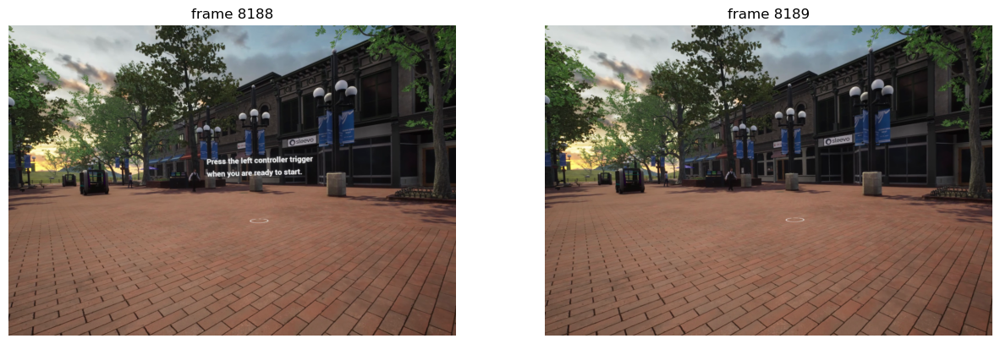

In [176]:
# find the needed frames 
print("FOR PERSON", pid, 'in VIDEO=', video_path)

frames = []
for i in [8188, 8189]:
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
    ret, frame = cap.read()
    if not ret:
        continue
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    frames.append((int(i), rgb))

fig, axs = plt.subplots(1, len(frames), figsize=(15, 5))
for ax, (i, fr) in zip(axs, frames):
    ax.imshow(fr)
    ax.set_title(f'frame {i}')
    ax.axis('off')
plt.show()

# 10764 - 10964

In [177]:
# check visually 
start = 227.554433
start_s1 = 365.793515
end_s1 = 377.742659

start_time = start
end_time = start + (end_s1 - start_s1)
output_path = f"../data/videoclips/testP{pid}S.mp4"

command = [
    "ffmpeg",
    "-y",
    "-i", f'../data/rawvideos/videos/{filename}.mp4',
    "-ss", str(start_time), # 
    "-to", str(end_time), # 626967, 654767, 682567
    # "-avoid_negative_ts", "1",
    output_path
]

subprocess.run(command, stdout=subprocess.DEVNULL, stderr=subprocess.STDOUT)
print(f"Clipped frames {start_time}–{end_time} saved to {output_path}")

Clipped frames 227.554433–239.50357699999998 saved to ../data/videoclips/testP5S.mp4


In [179]:
(0*60+35)*36

1260

In [180]:
# Get fps and basic info
filename = 'P5-3'
pid = 5

video_path = f'../data/rawvideos/videos/{filename}.mp4'
print('VIDEO=', video_path)
cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    print('Cannot open', video_path)
else:
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duration_sec = frame_count / fps if fps > 0 else None
    print(f'FPS={fps}, frames={frame_count}, duration(s)={duration_sec:.2f}')
# cap.release()

VIDEO= ../data/rawvideos/videos/P5-3.mp4
FPS=36.03163388847218, frames=3859, duration(s)=107.10


FOR PERSON 5 in VIDEO= ../data/rawvideos/videos/P5-3.mp4


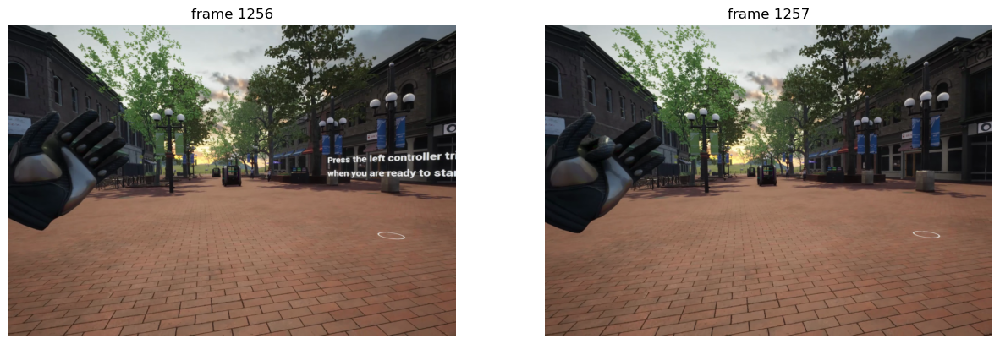

In [184]:
# find the needed frames 
print("FOR PERSON", pid, 'in VIDEO=', video_path)

frames = []
for i in [1256, 1257]:
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
    ret, frame = cap.read()
    if not ret:
        continue
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    frames.append((int(i), rgb))

fig, axs = plt.subplots(1, len(frames), figsize=(15, 5))
for ax, (i, fr) in zip(axs, frames):
    ax.imshow(fr)
    ax.set_title(f'frame {i}')
    ax.axis('off')
plt.show()

# 10764 - 10964

In [186]:
# check visually 
start = 34.941600
start_s1 = 56.181407
end_s1 = 65.477146

start_time = start
end_time = start + (end_s1 - start_s1)
output_path = f"../data/videoclips/testP{pid}S.mp4"

command = [
    "ffmpeg",
    "-y",
    "-i", f'../data/rawvideos/videos/{filename}.mp4',
    "-ss", str(start_time), # 
    "-to", str(end_time), # 626967, 654767, 682567
    # "-avoid_negative_ts", "1",
    output_path
]

subprocess.run(command, stdout=subprocess.DEVNULL, stderr=subprocess.STDOUT)
print(f"Clipped frames {start_time}–{end_time} saved to {output_path}")

Clipped frames 34.9416–44.237339000000006 saved to ../data/videoclips/testP5S.mp4


In [187]:
34.941600 - (56.181407 - 38.755185)

17.515378

## P9

In [188]:
(1*60+46)*36

3816

In [189]:
# Get fps and basic info
filename = 'P9-1'
pid = 9

video_path = f'../data/rawvideos/videos/{filename}.mp4'
print('VIDEO=', video_path)
cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    print('Cannot open', video_path)
else:
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duration_sec = frame_count / fps if fps > 0 else None
    print(f'FPS={fps}, frames={frame_count}, duration(s)={duration_sec:.2f}')
# cap.release()

VIDEO= ../data/rawvideos/videos/P9-1.mp4
FPS=36.00026614590486, frames=10713, duration(s)=297.58


FOR PERSON 9 in VIDEO= ../data/rawvideos/videos/P9-1.mp4


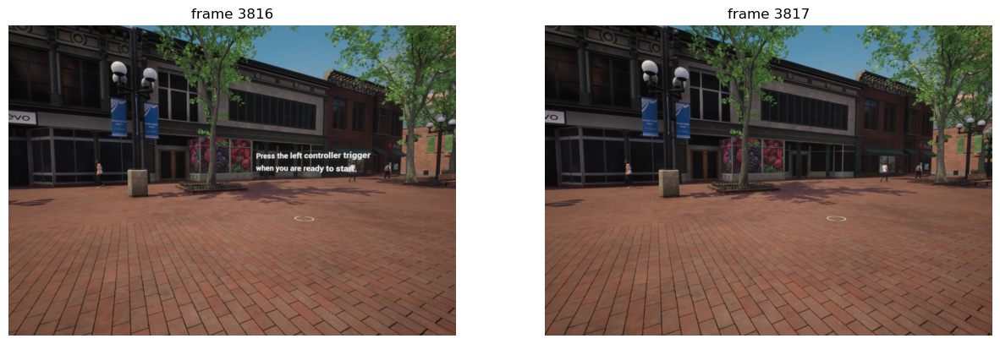

In [193]:
# find the needed frames 
print("FOR PERSON", pid, 'in VIDEO=', video_path)

frames = []
for i in [3816, 3817]:
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
    ret, frame = cap.read()
    if not ret:
        continue
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    frames.append((int(i), rgb))

fig, axs = plt.subplots(1, len(frames), figsize=(15, 5))
for ax, (i, fr) in zip(axs, frames):
    ax.imshow(fr)
    ax.set_title(f'frame {i}')
    ax.axis('off')
plt.show()

# 10764 - 10964

In [194]:
# check visually 
start = 106.079033
start_s1 = 180.389208
end_s1 = 186.584127

start_time = start
end_time = start + (end_s1 - start_s1)
output_path = f"../data/videoclips/testP{pid}S.mp4"

command = [
    "ffmpeg",
    "-y",
    "-i", f'../data/rawvideos/videos/{filename}.mp4',
    "-ss", str(start_time), # 
    "-to", str(end_time), # 626967, 654767, 682567
    # "-avoid_negative_ts", "1",
    output_path
]

subprocess.run(command, stdout=subprocess.DEVNULL, stderr=subprocess.STDOUT)
print(f"Clipped frames {start_time}–{end_time} saved to {output_path}")

Clipped frames 106.079033–112.273952 saved to ../data/videoclips/testP9S.mp4


## P10

In [195]:
(0*60+36)*36

1296

In [196]:
# Get fps and basic info
filename = 'P10-2'
pid = 10

video_path = f'../data/rawvideos/videos/{filename}.mp4'
print('VIDEO=', video_path)
cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    print('Cannot open', video_path)
else:
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duration_sec = frame_count / fps if fps > 0 else None
    print(f'FPS={fps}, frames={frame_count}, duration(s)={duration_sec:.2f}')
# cap.release()

VIDEO= ../data/rawvideos/videos/P10-2.mp4
FPS=36.00044393886063, frames=10088, duration(s)=280.22


FOR PERSON 10 in VIDEO= ../data/rawvideos/videos/P10-2.mp4


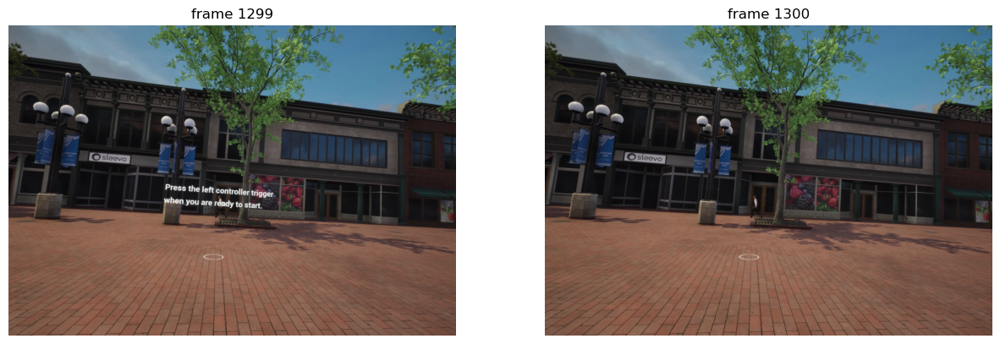

In [199]:
# find the needed frames 
print("FOR PERSON", pid, 'in VIDEO=', video_path)

frames = []
for i in [1299, 1300]:
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
    ret, frame = cap.read()
    if not ret:
        continue
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    frames.append((int(i), rgb))

fig, axs = plt.subplots(1, len(frames), figsize=(15, 5))
for ax, (i, fr) in zip(axs, frames):
    ax.imshow(fr)
    ax.set_title(f'frame {i}')
    ax.axis('off')
plt.show()

# 10764 - 10964

In [201]:
# check visually 
start = 36.156933
start_s1 = 42.502172
end_s1 = 49.447437

start_time = start
end_time = start + (end_s1 - start_s1)
output_path = f"../data/videoclips/testP{pid}S.mp4"

command = [
    "ffmpeg",
    "-y",
    "-i", f'../data/rawvideos/videos/{filename}.mp4',
    "-ss", str(start_time), # 
    "-to", str(end_time), # 626967, 654767, 682567
    # "-avoid_negative_ts", "1",
    output_path
]

subprocess.run(command, stdout=subprocess.DEVNULL, stderr=subprocess.STDOUT)
print(f"Clipped frames {start_time}–{end_time} saved to {output_path}")

Clipped frames 36.156933–43.102198 saved to ../data/videoclips/testP10S.mp4


## P11

In [202]:
(4*60+22)*36

9432

In [203]:
# Get fps and basic info
filename = 'P11-2'
pid = 11

video_path = f'../data/rawvideos/videos/{filename}.mp4'
print('VIDEO=', video_path)
cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    print('Cannot open', video_path)
else:
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duration_sec = frame_count / fps if fps > 0 else None
    print(f'FPS={fps}, frames={frame_count}, duration(s)={duration_sec:.2f}')
# cap.release()

VIDEO= ../data/rawvideos/videos/P11-2.mp4
FPS=35.992997693846576, frames=18373, duration(s)=510.46


FOR PERSON 11 in VIDEO= ../data/rawvideos/videos/P11-2.mp4


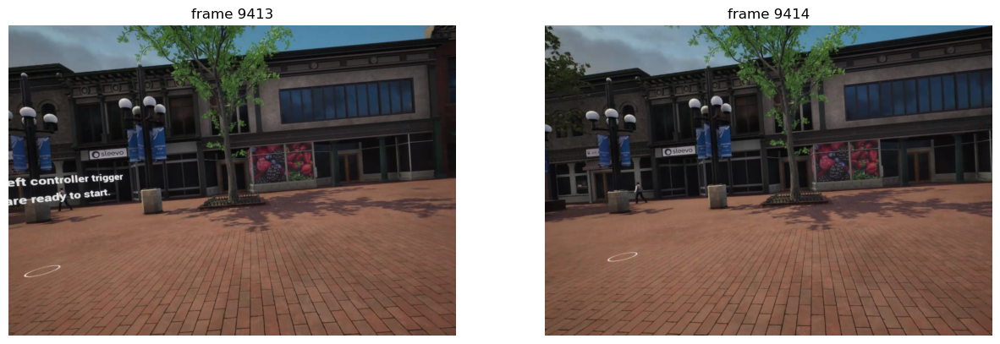

In [217]:
# find the needed frames 
print("FOR PERSON", pid, 'in VIDEO=', video_path)

frames = []
for i in [9413, 9414]:
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
    ret, frame = cap.read()
    if not ret:
        continue
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    frames.append((int(i), rgb))

fig, axs = plt.subplots(1, len(frames), figsize=(15, 5))
for ax, (i, fr) in zip(axs, frames):
    ax.imshow(fr)
    ax.set_title(f'frame {i}')
    ax.axis('off')
plt.show()

In [218]:
# check visually 
start = 261.629567
start_s1 = 301.780297
end_s1 = 311.769193

start_time = start
end_time = start + (end_s1 - start_s1)
output_path = f"../data/videoclips/testP{pid}S.mp4"

command = [
    "ffmpeg",
    "-y",
    "-i", f'../data/rawvideos/videos/{filename}.mp4',
    "-ss", str(start_time), # 
    "-to", str(end_time), # 626967, 654767, 682567
    # "-avoid_negative_ts", "1",
    output_path
]

subprocess.run(command, stdout=subprocess.DEVNULL, stderr=subprocess.STDOUT)
print(f"Clipped frames {start_time}–{end_time} saved to {output_path}")

Clipped frames 261.629567–271.61846299999996 saved to ../data/videoclips/testP11S.mp4


In [220]:
(0*60+14)*36

504

In [221]:
# Get fps and basic info
filename = 'P11-3'
pid = 11

video_path = f'../data/rawvideos/videos/{filename}.mp4'
print('VIDEO=', video_path)
cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    print('Cannot open', video_path)
else:
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duration_sec = frame_count / fps if fps > 0 else None
    print(f'FPS={fps}, frames={frame_count}, duration(s)={duration_sec:.2f}')
# cap.release()

VIDEO= ../data/rawvideos/videos/P11-3.mp4
FPS=36.141481044624896, frames=1195, duration(s)=33.06


FOR PERSON 11 in VIDEO= ../data/rawvideos/videos/P11-3.mp4


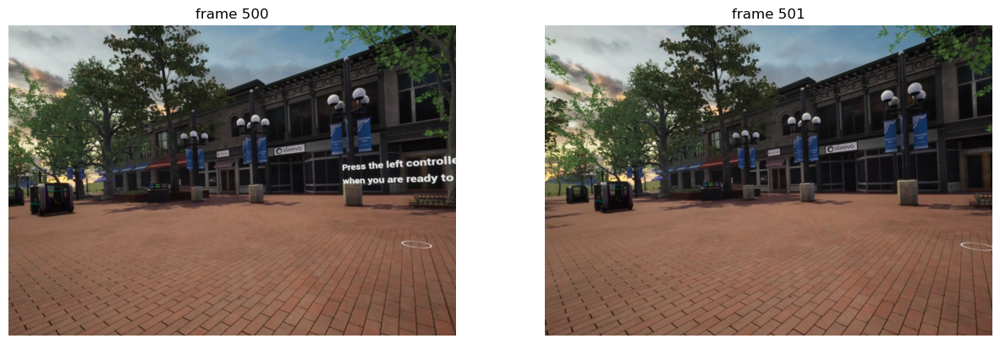

In [232]:
# find the needed frames 
print("FOR PERSON", pid, 'in VIDEO=', video_path)

frames = []
for i in [500, 501]:
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
    ret, frame = cap.read()
    if not ret:
        continue
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    frames.append((int(i), rgb))

fig, axs = plt.subplots(1, len(frames), figsize=(15, 5))
for ax, (i, fr) in zip(axs, frames):
    ax.imshow(fr)
    ax.set_title(f'frame {i}')
    ax.axis('off')
plt.show()

In [233]:
# check visually 
start = 13.929200
start_s1 = 22.669471
end_s1 = 37.819136

start_time = start
end_time = start + (end_s1 - start_s1)
output_path = f"../data/videoclips/testP{pid}S.mp4"

command = [
    "ffmpeg",
    "-y",
    "-i", f'../data/rawvideos/videos/{filename}.mp4',
    "-ss", str(start_time), # 
    "-to", str(end_time), # 626967, 654767, 682567
    # "-avoid_negative_ts", "1",
    output_path
]

subprocess.run(command, stdout=subprocess.DEVNULL, stderr=subprocess.STDOUT)
print(f"Clipped frames {start_time}–{end_time} saved to {output_path}")

Clipped frames 13.9292–29.078865 saved to ../data/videoclips/testP11S.mp4


## P12

In [242]:
(7*60+8)*36

15408

In [235]:
# Get fps and basic info
filename = 'P12-1'
pid = 12

video_path = f'../data/rawvideos/videos/{filename}.mp4'
print('VIDEO=', video_path)
cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    print('Cannot open', video_path)
else:
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duration_sec = frame_count / fps if fps > 0 else None
    print(f'FPS={fps}, frames={frame_count}, duration(s)={duration_sec:.2f}')
# cap.release()

VIDEO= ../data/rawvideos/videos/P12-1.mp4
FPS=35.99031780317763, frames=24792, duration(s)=688.85


FOR PERSON 12 in VIDEO= ../data/rawvideos/videos/P12-1.mp4


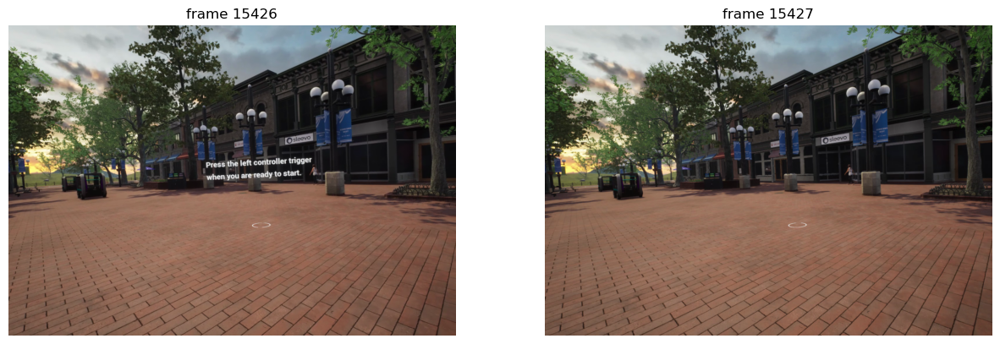

In [247]:
# find the needed frames 
print("FOR PERSON", pid, 'in VIDEO=', video_path)

frames = []
for i in [15426, 15427]:
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
    ret, frame = cap.read()
    if not ret:
        continue
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    frames.append((int(i), rgb))

fig, axs = plt.subplots(1, len(frames), figsize=(15, 5))
for ax, (i, fr) in zip(axs, frames):
    ax.imshow(fr)
    ax.set_title(f'frame {i}')
    ax.axis('off')
plt.show()

In [248]:
# check visually 
start = 428.708967
start_s1 = 520.070449
end_s1 = 531.676689

start_time = start
end_time = start + (end_s1 - start_s1)
output_path = f"../data/videoclips/testP{pid}S.mp4"

command = [
    "ffmpeg",
    "-y",
    "-i", f'../data/rawvideos/videos/{filename}.mp4',
    "-ss", str(start_time), # 
    "-to", str(end_time), # 626967, 654767, 682567
    # "-avoid_negative_ts", "1",
    output_path
]

subprocess.run(command, stdout=subprocess.DEVNULL, stderr=subprocess.STDOUT)
print(f"Clipped frames {start_time}–{end_time} saved to {output_path}")

Clipped frames 428.708967–440.31520699999993 saved to ../data/videoclips/testP12S.mp4


In [250]:
(0*60+46)*36

1656

In [249]:
# Get fps and basic info
filename = 'P12-2'
pid = 12

video_path = f'../data/rawvideos/videos/{filename}.mp4'
print('VIDEO=', video_path)
cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    print('Cannot open', video_path)
else:
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duration_sec = frame_count / fps if fps > 0 else None
    print(f'FPS={fps}, frames={frame_count}, duration(s)={duration_sec:.2f}')
# cap.release()

VIDEO= ../data/rawvideos/videos/P12-2.mp4
FPS=36.06045123694012, frames=2435, duration(s)=67.53


FOR PERSON 12 in VIDEO= ../data/rawvideos/videos/P12-2.mp4


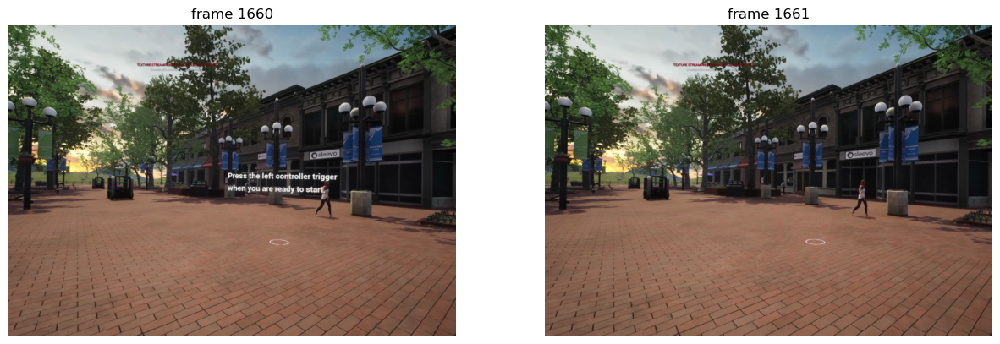

In [257]:
# find the needed frames 
print("FOR PERSON", pid, 'in VIDEO=', video_path)

frames = []
for i in [1660, 1661]:
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
    ret, frame = cap.read()
    if not ret:
        continue
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    frames.append((int(i), rgb))

fig, axs = plt.subplots(1, len(frames), figsize=(15, 5))
for ax, (i, fr) in zip(axs, frames):
    ax.imshow(fr)
    ax.set_title(f'frame {i}')
    ax.axis('off')
plt.show()

In [259]:
# check visually 
start = 46.168967
start_s1 = 39.358893
end_s1 = 63.505889

start_time = start
end_time = start + (end_s1 - start_s1)
output_path = f"../data/videoclips/testP{pid}S.mp4"

command = [
    "ffmpeg",
    "-y",
    "-i", f'../data/rawvideos/videos/{filename}.mp4',
    "-ss", str(start_time), # 
    "-to", str(end_time), # 626967, 654767, 682567
    # "-avoid_negative_ts", "1",
    output_path
]

subprocess.run(command, stdout=subprocess.DEVNULL, stderr=subprocess.STDOUT)
print(f"Clipped frames {start_time}–{end_time} saved to {output_path}")

Clipped frames 46.168967–70.31596300000001 saved to ../data/videoclips/testP12S.mp4


In [261]:
(0*60+11)*36

396

In [260]:
# Get fps and basic info
filename = 'P12-3'
pid = 12

video_path = f'../data/rawvideos/videos/{filename}.mp4'
print('VIDEO=', video_path)
cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    print('Cannot open', video_path)
else:
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duration_sec = frame_count / fps if fps > 0 else None
    print(f'FPS={fps}, frames={frame_count}, duration(s)={duration_sec:.2f}')
# cap.release()

VIDEO= ../data/rawvideos/videos/P12-3.mp4
FPS=36.09457033114389, frames=1694, duration(s)=46.93


FOR PERSON 12 in VIDEO= ../data/rawvideos/videos/P12-3.mp4


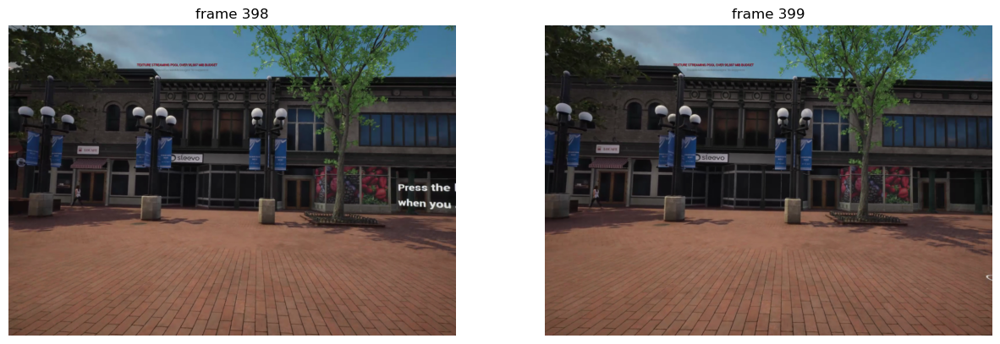

In [265]:
# find the needed frames 
print("FOR PERSON", pid, 'in VIDEO=', video_path)

frames = []
for i in [398, 399]:
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
    ret, frame = cap.read()
    if not ret:
        continue
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    frames.append((int(i), rgb))

fig, axs = plt.subplots(1, len(frames), figsize=(15, 5))
for ax, (i, fr) in zip(axs, frames):
    ax.imshow(fr)
    ax.set_title(f'frame {i}')
    ax.axis('off')
plt.show()

In [266]:
# check visually 
start = 11.092767
start_s1 = 16.199554
end_s1 = 26.863804

start_time = start
end_time = start + (end_s1 - start_s1)
output_path = f"../data/videoclips/testP{pid}S.mp4"

command = [
    "ffmpeg",
    "-y",
    "-i", f'../data/rawvideos/videos/{filename}.mp4',
    "-ss", str(start_time), # 
    "-to", str(end_time), # 626967, 654767, 682567
    # "-avoid_negative_ts", "1",
    output_path
]

subprocess.run(command, stdout=subprocess.DEVNULL, stderr=subprocess.STDOUT)
print(f"Clipped frames {start_time}–{end_time} saved to {output_path}")

Clipped frames 11.092767–21.757016999999998 saved to ../data/videoclips/testP12S.mp4


## P14

In [9]:
(5*60+8)*36

11088

In [3]:
# Get fps and basic info
filename = 'P14-1'
pid = 14

video_path = f'../data/videodata/videoraw/{filename}.mp4'
print('VIDEO=', video_path)
cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    print('Cannot open', video_path)
else:
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duration_sec = frame_count / fps if fps > 0 else None
    print(f'FPS={fps}, frames={frame_count}, duration(s)={duration_sec:.2f}')
# cap.release()

VIDEO= ../data/videodata/videoraw/P14-1.mp4
FPS=35.99173434277297, frames=21002, duration(s)=583.52


FOR PERSON 14 in VIDEO= ../data/videodata/videoraw/P14-1.mp4


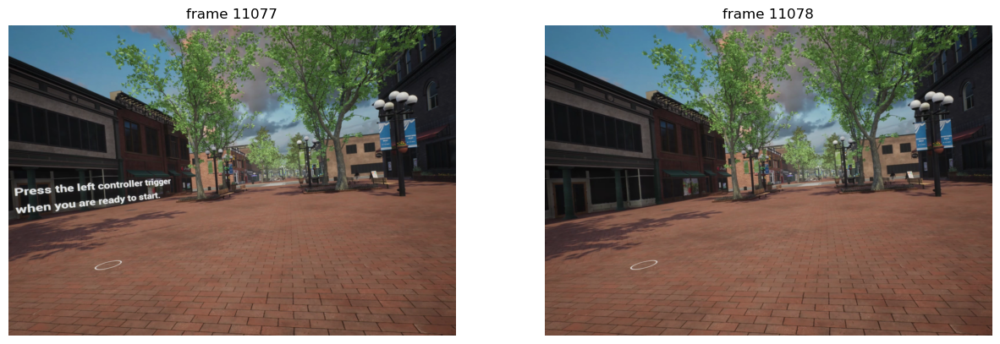

In [14]:
# find the needed frames 
print("FOR PERSON", pid, 'in VIDEO=', video_path)

frames = []
for i in [11077, 11078]:
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
    ret, frame = cap.read()
    if not ret:
        continue
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    frames.append((int(i), rgb))

fig, axs = plt.subplots(1, len(frames), figsize=(15, 5))
for ax, (i, fr) in zip(axs, frames):
    ax.imshow(fr)
    ax.set_title(f'frame {i}')
    ax.axis('off')
plt.show()

In [17]:
# check visually 
start = 307.845900
start_s1 = 538.588106
end_s1 = 548.885074

start_time = start
end_time = start + (end_s1 - start_s1)
output_path = f"../data/videodata/testP{pid}S.mp4"

command = [
    "ffmpeg",
    "-y",
    "-i", f'../data/videodata/videoraw/{filename}.mp4',
    "-ss", str(start_time), # 
    "-to", str(end_time), # 626967, 654767, 682567
    # "-avoid_negative_ts", "1",
    output_path
]

subprocess.run(command, stdout=subprocess.DEVNULL, stderr=subprocess.STDOUT)
print(f"Clipped frames {start_time}–{end_time} saved to {output_path}")

Clipped frames 307.8459–318.14286799999996 saved to ../data/videodata/testP14S.mp4


In [22]:
(0*60+15)*36

540

In [20]:
# Get fps and basic info
filename = 'P14-2'
pid = 14

video_path = f'../data/videodata/videoraw/{filename}.mp4'
print('VIDEO=', video_path)
cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    print('Cannot open', video_path)
else:
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duration_sec = frame_count / fps if fps > 0 else None
    print(f'FPS={fps}, frames={frame_count}, duration(s)={duration_sec:.2f}')
# cap.release()

VIDEO= ../data/videodata/videoraw/P14-2.mp4
FPS=36.16386925795053, frames=1048, duration(s)=28.98


FOR PERSON 14 in VIDEO= ../data/videodata/videoraw/P14-2.mp4


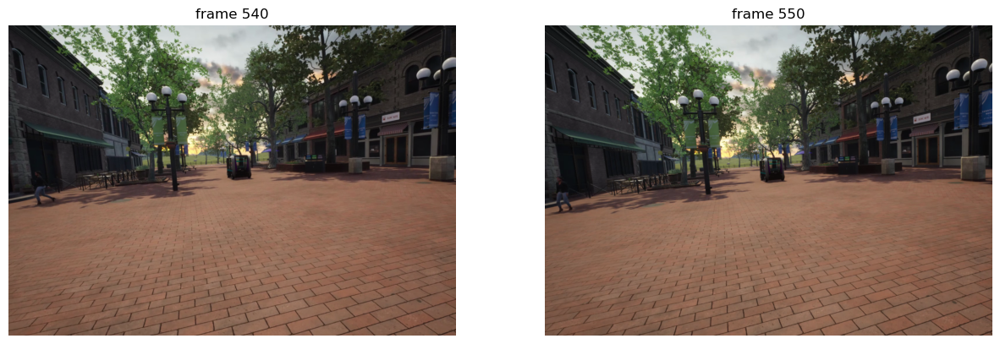

In [23]:
# find the needed frames 
print("FOR PERSON", pid, 'in VIDEO=', video_path)

frames = []
for i in [540, 550]:
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
    ret, frame = cap.read()
    if not ret:
        continue
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    frames.append((int(i), rgb))

fig, axs = plt.subplots(1, len(frames), figsize=(15, 5))
for ax, (i, fr) in zip(axs, frames):
    ax.imshow(fr)
    ax.set_title(f'frame {i}')
    ax.axis('off')
plt.show()

In [27]:
# check visually 
start = 14.583367
start_s1 = 24.906768
end_s1 = 35.641987

start_time = start
end_time = start + (end_s1 - start_s1)
output_path = f"../data/videodata/testP{pid}S.mp4"

command = [
    "ffmpeg",
    "-y",
    "-i", f'../data/videodata/videoraw/{filename}.mp4',
    "-ss", str(start_time), # 
    "-to", str(end_time), # 626967, 654767, 682567
    # "-avoid_negative_ts", "1",
    output_path
]

subprocess.run(command, stdout=subprocess.DEVNULL, stderr=subprocess.STDOUT)
print(f"Clipped frames {start_time}–{end_time} saved to {output_path}")

Clipped frames 14.583367–25.318586000000003 saved to ../data/videodata/testP14S.mp4


### P15

In [33]:
(4*60+53)*36

10548

In [31]:
# Get fps and basic info
pid = 15
filename = f'P{pid}-1'

video_path = f'../data/videodata/videoraw/{filename}.mp4'
print('VIDEO=', video_path)
cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    print('Cannot open', video_path)
else:
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duration_sec = frame_count / fps if fps > 0 else None
    print(f'FPS={fps}, frames={frame_count}, duration(s)={duration_sec:.2f}')
# cap.release()

VIDEO= ../data/videodata/videoraw/P15-1.mp4
FPS=35.99236457783402, frames=19621, duration(s)=545.14


FOR PERSON 15 in VIDEO= ../data/videodata/videoraw/P15-1.mp4


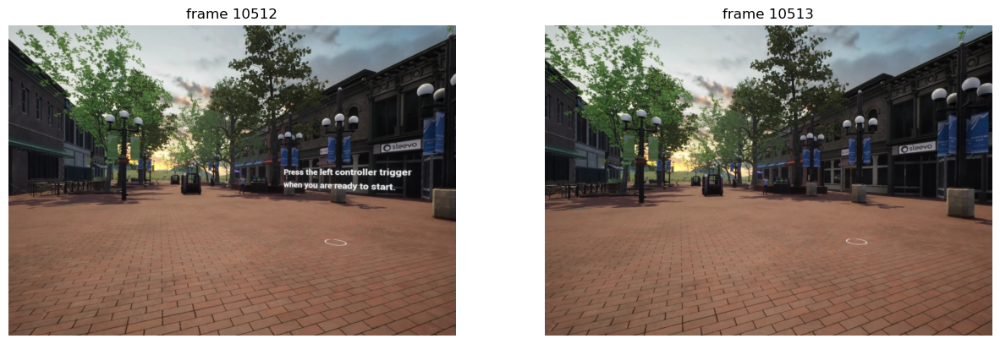

In [40]:
# find the needed frames 
print("FOR PERSON", pid, 'in VIDEO=', video_path)

frames = []
for i in [10512, 10513]:
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
    ret, frame = cap.read()
    if not ret:
        continue
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    frames.append((int(i), rgb))

fig, axs = plt.subplots(1, len(frames), figsize=(15, 5))
for ax, (i, fr) in zip(axs, frames):
    ax.imshow(fr)
    ax.set_title(f'frame {i}')
    ax.axis('off')
plt.show()

In [41]:
# check visually 
start = 292.140233
start_s1 = 301.139872
end_s1 = 311.381358

start_time = start
end_time = start + (end_s1 - start_s1)
output_path = f"../data/videodata/testP{pid}S.mp4"

command = [
    "ffmpeg",
    "-y",
    "-i", f'../data/videodata/videoraw/{filename}.mp4',
    "-ss", str(start_time), # 
    "-to", str(end_time), # 626967, 654767, 682567
    # "-avoid_negative_ts", "1",
    output_path
]

subprocess.run(command, stdout=subprocess.DEVNULL, stderr=subprocess.STDOUT)
print(f"Clipped frames {start_time}–{end_time} saved to {output_path}")

Clipped frames 292.140233–302.381719 saved to ../data/videodata/testP15S.mp4


In [43]:
(0*60+9)*36

324

In [42]:
# Get fps and basic info
filename = f'P{pid}-2'

video_path = f'../data/videodata/videoraw/{filename}.mp4'
print('VIDEO=', video_path)
cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    print('Cannot open', video_path)
else:
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duration_sec = frame_count / fps if fps > 0 else None
    print(f'FPS={fps}, frames={frame_count}, duration(s)={duration_sec:.2f}')
# cap.release()

VIDEO= ../data/videodata/videoraw/P15-2.mp4
FPS=36.20498372540108, frames=855, duration(s)=23.62


FOR PERSON 15 in VIDEO= ../data/videodata/videoraw/P15-2.mp4


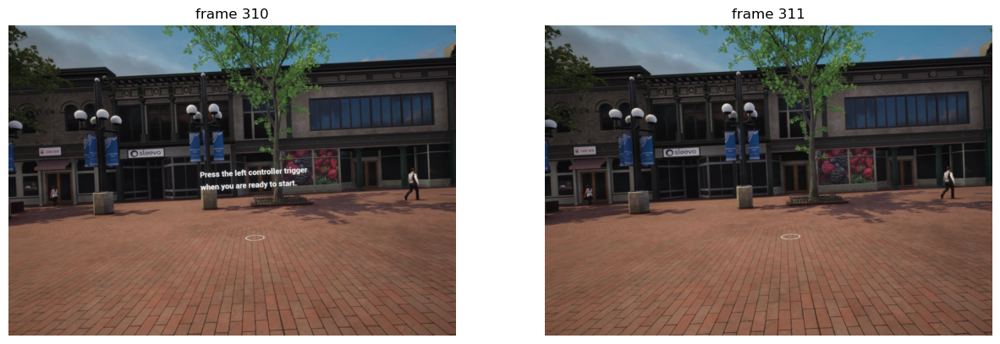

In [49]:
# find the needed frames 
print("FOR PERSON", pid, 'in VIDEO=', video_path)

frames = []
for i in [310, 311]:
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
    ret, frame = cap.read()
    if not ret:
        continue
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    frames.append((int(i), rgb))

fig, axs = plt.subplots(1, len(frames), figsize=(15, 5))
for ax, (i, fr) in zip(axs, frames):
    ax.imshow(fr)
    ax.set_title(f'frame {i}')
    ax.axis('off')
plt.show()

In [51]:
# check visually 
start = 8.673833
start_s1 = 15.564042
end_s1 = 25.618688

start_time = start
end_time = start + (end_s1 - start_s1)
output_path = f"../data/videodata/testP{pid}S.mp4"

command = [
    "ffmpeg",
    "-y",
    "-i", f'../data/videodata/videoraw/{filename}.mp4',
    "-ss", str(start_time), # 
    "-to", str(end_time), # 626967, 654767, 682567
    # "-avoid_negative_ts", "1",
    output_path
]

subprocess.run(command, stdout=subprocess.DEVNULL, stderr=subprocess.STDOUT)
print(f"Clipped frames {start_time}–{end_time} saved to {output_path}")

Clipped frames 8.673833–18.728479 saved to ../data/videodata/testP15S.mp4


In [ ]:
(0*60+6)*36

216

In [53]:
# Get fps and basic info
filename = f'P{pid}-3_2'

video_path = f'../data/videodata/videoraw/{filename}.mp4'
print('VIDEO=', video_path)
cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    print('Cannot open', video_path)
else:
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duration_sec = frame_count / fps if fps > 0 else None
    print(f'FPS={fps}, frames={frame_count}, duration(s)={duration_sec:.2f}')
# cap.release()

VIDEO= ../data/videodata/videoraw/P15-3_2.mp4
FPS=36.27262438234401, frames=657, duration(s)=18.11


FOR PERSON 15 in VIDEO= ../data/videodata/videoraw/P15-3_2.mp4


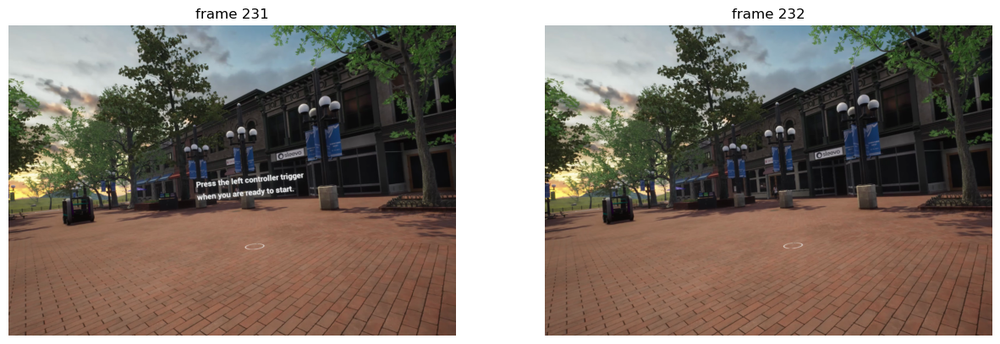

In [58]:
# find the needed frames 
print("FOR PERSON", pid, 'in VIDEO=', video_path)

frames = []
for i in [231, 232]:
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
    ret, frame = cap.read()
    if not ret:
        continue
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    frames.append((int(i), rgb))

fig, axs = plt.subplots(1, len(frames), figsize=(15, 5))
for ax, (i, fr) in zip(axs, frames):
    ax.imshow(fr)
    ax.set_title(f'frame {i}')
    ax.axis('off')
plt.show()

In [59]:
# check visually 
start = 6.452367
start_s1 = 15.626789
end_s1 = 23.624237

start_time = start
end_time = start + (end_s1 - start_s1)
output_path = f"../data/videodata/testP{pid}S.mp4"

command = [
    "ffmpeg",
    "-y",
    "-i", f'../data/videodata/videoraw/{filename}.mp4',
    "-ss", str(start_time), # 
    "-to", str(end_time), # 626967, 654767, 682567
    # "-avoid_negative_ts", "1",
    output_path
]

subprocess.run(command, stdout=subprocess.DEVNULL, stderr=subprocess.STDOUT)
print(f"Clipped frames {start_time}–{end_time} saved to {output_path}")

Clipped frames 6.452367–14.449815000000001 saved to ../data/videodata/testP15S.mp4


## P16

In [69]:
(0*60+15)*36

540

In [68]:
# Get fps and basic info
pid = 16
filename = f'P{pid}-2'

video_path = f'../data/videodata/videoraw/{filename}.mp4'
print('VIDEO=', video_path)
cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    print('Cannot open', video_path)
else:
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duration_sec = frame_count / fps if fps > 0 else None
    print(f'FPS={fps}, frames={frame_count}, duration(s)={duration_sec:.2f}')
# cap.release()

VIDEO= ../data/videodata/videoraw/P16-2.mp4
FPS=36.00185942869527, frames=9890, duration(s)=274.71


FOR PERSON 16 in VIDEO= ../data/videodata/videoraw/P16-2.mp4


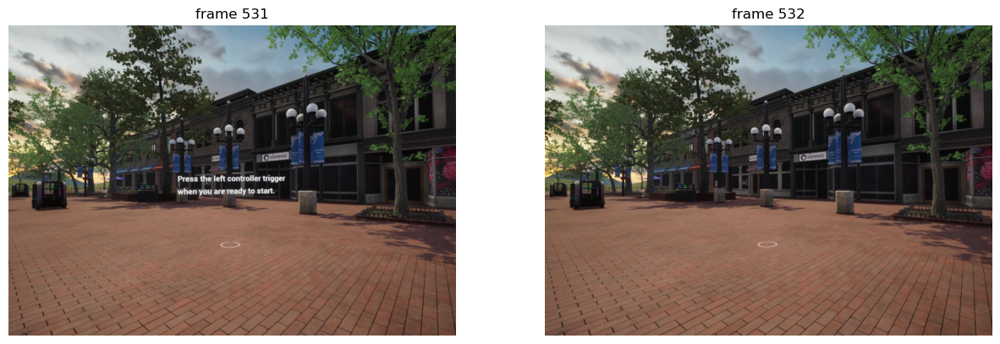

In [74]:
# find the needed frames 
print("FOR PERSON", pid, 'in VIDEO=', video_path)

frames = []
for i in [531, 532]:
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
    ret, frame = cap.read()
    if not ret:
        continue
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    frames.append((int(i), rgb))

fig, axs = plt.subplots(1, len(frames), figsize=(15, 5))
for ax, (i, fr) in zip(axs, frames):
    ax.imshow(fr)
    ax.set_title(f'frame {i}')
    ax.axis('off')
plt.show()

In [76]:
# check visually 
start = 14.818367
start_s1 = 31.216348
end_s1 = 43.85086

start_time = start
end_time = start + (end_s1 - start_s1)
output_path = f"../data/videodata/testPS.mp4"

command = [
    "ffmpeg",
    "-y",
    "-i", f'../data/videodata/videoraw/{filename}.mp4',
    "-ss", str(start_time), # 
    "-to", str(end_time), # 626967, 654767, 682567
    # "-avoid_negative_ts", "1",
    output_path
]

subprocess.run(command, stdout=subprocess.DEVNULL, stderr=subprocess.STDOUT)
print(f"Clipped frames {start_time}–{end_time} saved to {output_path}")

Clipped frames 14.818367–27.452878999999996 saved to ../data/videodata/testPS.mp4


## P17

In [77]:
(2*60+34)*36

5544

In [78]:
# Get fps and basic info
pid = 17
filename = f'P{pid}-1'

video_path = f'../data/videodata/videoraw/{filename}.mp4'
print('VIDEO=', video_path)
cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    print('Cannot open', video_path)
else:
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duration_sec = frame_count / fps if fps > 0 else None
    print(f'FPS={fps}, frames={frame_count}, duration(s)={duration_sec:.2f}')
# cap.release()

VIDEO= ../data/videodata/videoraw/P17-1.mp4
FPS=35.99712088791072, frames=13138, duration(s)=364.97


FOR PERSON 17 in VIDEO= ../data/videodata/videoraw/P17-1.mp4


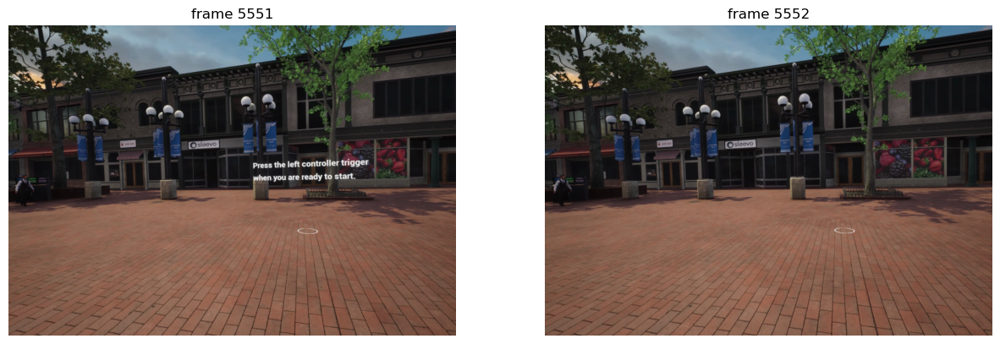

In [82]:
# find the needed frames 
print("FOR PERSON", pid, 'in VIDEO=', video_path)

frames = []
for i in [5551, 5552]:
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
    ret, frame = cap.read()
    if not ret:
        continue
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    frames.append((int(i), rgb))

fig, axs = plt.subplots(1, len(frames), figsize=(15, 5))
for ax, (i, fr) in zip(axs, frames):
    ax.imshow(fr)
    ax.set_title(f'frame {i}')
    ax.axis('off')
plt.show()

In [83]:
# check visually 
start = 154.268433
start_s1 = 168.524087
end_s1 = 172.967882

start_time = start
end_time = start + (end_s1 - start_s1)
output_path = f"../data/videodata/testPS.mp4"

command = [
    "ffmpeg",
    "-y",
    "-i", f'../data/videodata/videoraw/{filename}.mp4',
    "-ss", str(start_time), # 
    "-to", str(end_time), # 626967, 654767, 682567
    # "-avoid_negative_ts", "1",
    output_path
]

subprocess.run(command, stdout=subprocess.DEVNULL, stderr=subprocess.STDOUT)
print(f"Clipped frames {start_time}–{end_time} saved to {output_path}")

Clipped frames 154.268433–158.71222799999998 saved to ../data/videodata/testPS.mp4


In [84]:
(0*60+9)*36

324

In [85]:
# Get fps and basic info
pid = 17
filename = f'P{pid}-2'

video_path = f'../data/videodata/videoraw/{filename}.mp4'
print('VIDEO=', video_path)
cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    print('Cannot open', video_path)
else:
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duration_sec = frame_count / fps if fps > 0 else None
    print(f'FPS={fps}, frames={frame_count}, duration(s)={duration_sec:.2f}')
# cap.release()

VIDEO= ../data/videodata/videoraw/P17-2.mp4
FPS=36.082223503854266, frames=1904, duration(s)=52.77


FOR PERSON 17 in VIDEO= ../data/videodata/videoraw/P17-2.mp4


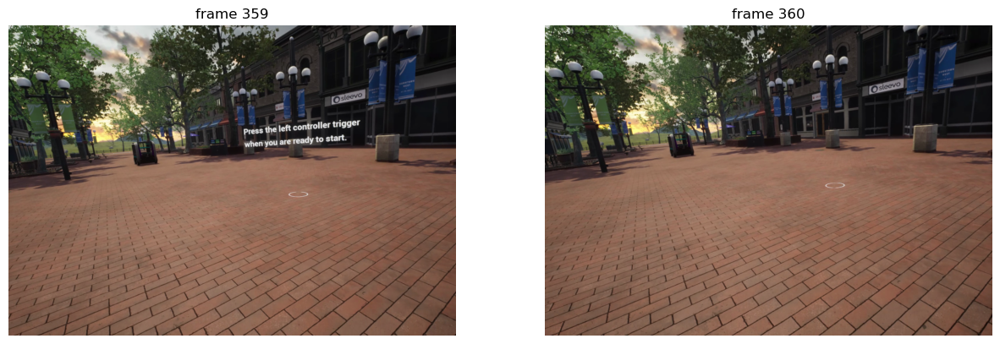

In [91]:
# find the needed frames 
print("FOR PERSON", pid, 'in VIDEO=', video_path)

frames = []
for i in [359, 360]:
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
    ret, frame = cap.read()
    if not ret:
        continue
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    frames.append((int(i), rgb))

fig, axs = plt.subplots(1, len(frames), figsize=(15, 5))
for ax, (i, fr) in zip(axs, frames):
    ax.imshow(fr)
    ax.set_title(f'frame {i}')
    ax.axis('off')
plt.show()

In [94]:
# check visually 
start = 10.036567
start_s1 = 14.18561
end_s1 = 21.127939

start_time = start
end_time = start + (end_s1 - start_s1)
output_path = f"../data/videodata/testPS.mp4"

command = [
    "ffmpeg",
    "-y",
    "-i", f'../data/videodata/videoraw/{filename}.mp4',
    "-ss", str(start_time), # 
    "-to", str(end_time), # 626967, 654767, 682567
    # "-avoid_negative_ts", "1",
    output_path
]

subprocess.run(command, stdout=subprocess.DEVNULL, stderr=subprocess.STDOUT)
print(f"Clipped frames {start_time}–{end_time} saved to {output_path}")

Clipped frames 10.036567–16.978896 saved to ../data/videodata/testPS.mp4


In [ ]:
(0*60+9)*36

324

In [95]:
# Get fps and basic info
pid = 17
filename = f'P{pid}-3'

video_path = f'../data/videodata/videoraw/{filename}.mp4'
print('VIDEO=', video_path)
cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    print('Cannot open', video_path)
else:
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duration_sec = frame_count / fps if fps > 0 else None
    print(f'FPS={fps}, frames={frame_count}, duration(s)={duration_sec:.2f}')
# cap.release()

VIDEO= ../data/videodata/videoraw/P17-3.mp4
FPS=36.26187239578256, frames=682, duration(s)=18.81


FOR PERSON 17 in VIDEO= ../data/videodata/videoraw/P17-3.mp4


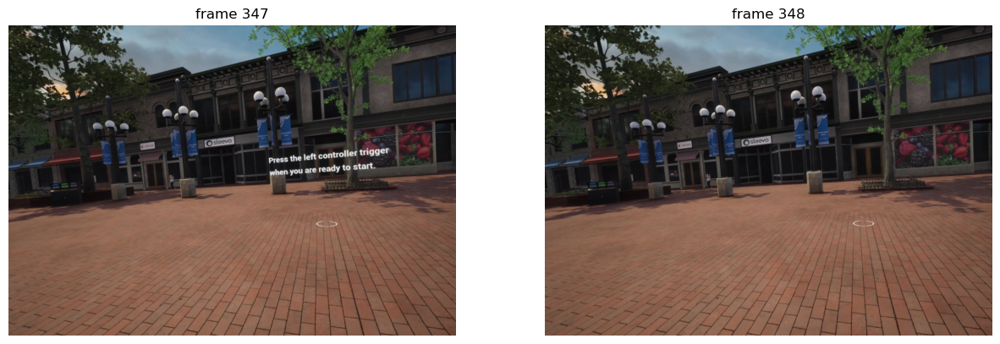

In [101]:
# find the needed frames 
print("FOR PERSON", pid, 'in VIDEO=', video_path)

frames = []
for i in [347, 348]:
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
    ret, frame = cap.read()
    if not ret:
        continue
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    frames.append((int(i), rgb))

fig, axs = plt.subplots(1, len(frames), figsize=(15, 5))
for ax, (i, fr) in zip(axs, frames):
    ax.imshow(fr)
    ax.set_title(f'frame {i}')
    ax.axis('off')
plt.show()

In [102]:
# check visually 
start = 9.647033
start_s1 = 14.117733
end_s1 = 18.610591

start_time = start
end_time = start + (end_s1 - start_s1)
output_path = f"../data/videodata/testPS.mp4"

command = [
    "ffmpeg",
    "-y",
    "-i", f'../data/videodata/videoraw/{filename}.mp4',
    "-ss", str(start_time), # 
    "-to", str(end_time), # 626967, 654767, 682567
    # "-avoid_negative_ts", "1",
    output_path
]

subprocess.run(command, stdout=subprocess.DEVNULL, stderr=subprocess.STDOUT)
print(f"Clipped frames {start_time}–{end_time} saved to {output_path}")

Clipped frames 9.647033–14.139891 saved to ../data/videodata/testPS.mp4


## P18

In [104]:
(5*60+27)*36

11772

In [103]:
# Get fps and basic info
pid = 18
filename = f'P{pid}-1'

video_path = f'../data/videodata/videoraw/{filename}.mp4'
print('VIDEO=', video_path)
cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    print('Cannot open', video_path)
else:
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duration_sec = frame_count / fps if fps > 0 else None
    print(f'FPS={fps}, frames={frame_count}, duration(s)={duration_sec:.2f}')
# cap.release()

VIDEO= ../data/videodata/videoraw/P18-1.mp4
FPS=35.99138076458273, frames=21869, duration(s)=607.62


FOR PERSON 18 in VIDEO= ../data/videodata/videoraw/P18-1.mp4


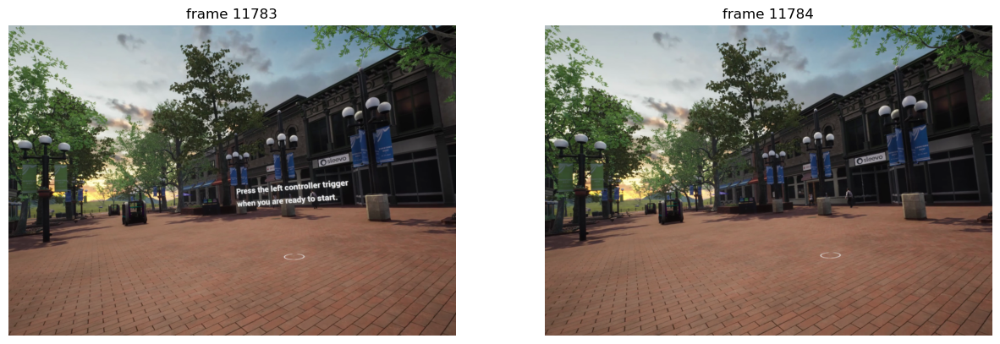

In [108]:
# find the needed frames 
print("FOR PERSON", pid, 'in VIDEO=', video_path)

frames = []
for i in [11783, 11784]:
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
    ret, frame = cap.read()
    if not ret:
        continue
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    frames.append((int(i), rgb))

fig, axs = plt.subplots(1, len(frames), figsize=(15, 5))
for ax, (i, fr) in zip(axs, frames):
    ax.imshow(fr)
    ax.set_title(f'frame {i}')
    ax.axis('off')
plt.show()

In [110]:
# check visually 
start = 327.468200
start_s1 = 519.243779
end_s1 = 530.575751

start_time = start
end_time = start + (end_s1 - start_s1)
output_path = f"../data/videodata/testPS.mp4"

command = [
    "ffmpeg",
    "-y",
    "-i", f'../data/videodata/videoraw/{filename}.mp4',
    "-ss", str(start_time), # 
    "-to", str(end_time), # 626967, 654767, 682567
    # "-avoid_negative_ts", "1",
    output_path
]

subprocess.run(command, stdout=subprocess.DEVNULL, stderr=subprocess.STDOUT)
print(f"Clipped frames {start_time}–{end_time} saved to {output_path}")

Clipped frames 327.4682–338.800172 saved to ../data/videodata/testPS.mp4


In [112]:
(0*60+19)*36

684

In [111]:
# Get fps and basic info
pid = 18
filename = f'P{pid}-2'

video_path = f'../data/videodata/videoraw/{filename}.mp4'
print('VIDEO=', video_path)
cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    print('Cannot open', video_path)
else:
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duration_sec = frame_count / fps if fps > 0 else None
    print(f'FPS={fps}, frames={frame_count}, duration(s)={duration_sec:.2f}')
# cap.release()

VIDEO= ../data/videodata/videoraw/P18-2.mp4
FPS=36.1410890193034, frames=1198, duration(s)=33.15


FOR PERSON 18 in VIDEO= ../data/videodata/videoraw/P18-2.mp4


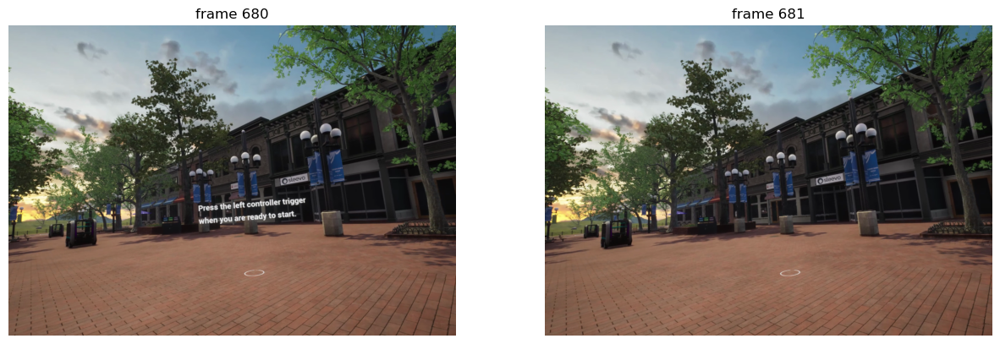

In [116]:
# find the needed frames 
print("FOR PERSON", pid, 'in VIDEO=', video_path)

frames = []
for i in [680, 681]:
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
    ret, frame = cap.read()
    if not ret:
        continue
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    frames.append((int(i), rgb))

fig, axs = plt.subplots(1, len(frames), figsize=(15, 5))
for ax, (i, fr) in zip(axs, frames):
    ax.imshow(fr)
    ax.set_title(f'frame {i}')
    ax.axis('off')
plt.show()

In [118]:
# check visually 
start = 18.904633
start_s1 = 23.416484
end_s1 = 33.666657

start_time = start
end_time = start + (end_s1 - start_s1)
output_path = f"../data/videodata/testPS.mp4"

command = [
    "ffmpeg",
    "-y",
    "-i", f'../data/videodata/videoraw/{filename}.mp4',
    "-ss", str(start_time), # 
    "-to", str(end_time), # 626967, 654767, 682567
    # "-avoid_negative_ts", "1",
    output_path
]

subprocess.run(command, stdout=subprocess.DEVNULL, stderr=subprocess.STDOUT)
print(f"Clipped frames {start_time}–{end_time} saved to {output_path}")

Clipped frames 18.904633–29.154806 saved to ../data/videodata/testPS.mp4


In [119]:
(0*60+16)*36

576

In [122]:
# Get fps and basic info
pid = 18
filename = f'P{pid}-3'

video_path = f'../data/videodata/videoraw/{filename}.mp4'
print('VIDEO=', video_path)
cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    print('Cannot open', video_path)
else:
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duration_sec = frame_count / fps if fps > 0 else None
    print(f'FPS={fps}, frames={frame_count}, duration(s)={duration_sec:.2f}')
# cap.release()

VIDEO= ../data/videodata/videoraw/P18-3.mp4
FPS=36.15770759023042, frames=1085, duration(s)=30.01


FOR PERSON 18 in VIDEO= ../data/videodata/videoraw/P18-3.mp4


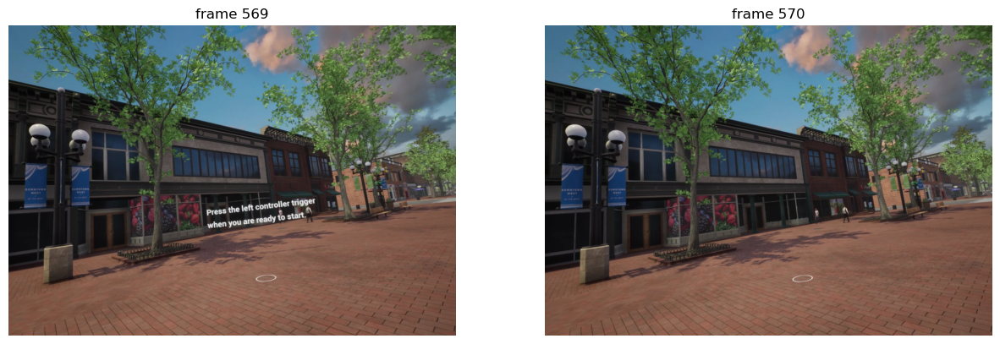

In [128]:
# find the needed frames 
print("FOR PERSON", pid, 'in VIDEO=', video_path)

frames = []
for i in [569, 570]:
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
    ret, frame = cap.read()
    if not ret:
        continue
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    frames.append((int(i), rgb))

fig, axs = plt.subplots(1, len(frames), figsize=(15, 5))
for ax, (i, fr) in zip(axs, frames):
    ax.imshow(fr)
    ax.set_title(f'frame {i}')
    ax.axis('off')
plt.show()

In [129]:
# check visually 
start = 15.816233
start_s1 = 20.04929
end_s1 = 30.368935

start_time = start
end_time = start + (end_s1 - start_s1)
output_path = f"../data/videodata/testPS.mp4"

command = [
    "ffmpeg",
    "-y",
    "-i", f'../data/videodata/videoraw/{filename}.mp4',
    "-ss", str(start_time), # 
    "-to", str(end_time), # 626967, 654767, 682567
    # "-avoid_negative_ts", "1",
    output_path
]

subprocess.run(command, stdout=subprocess.DEVNULL, stderr=subprocess.STDOUT)
print(f"Clipped frames {start_time}–{end_time} saved to {output_path}")

Clipped frames 15.816233–26.135878 saved to ../data/videodata/testPS.mp4


## P20

In [130]:
(2*60+57)*36

6372

In [131]:
# Get fps and basic info
pid = 20
filename = f'P{pid}-1'

video_path = f'../data/videodata/videoraw/{filename}.mp4'
print('VIDEO=', video_path)
cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    print('Cannot open', video_path)
else:
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duration_sec = frame_count / fps if fps > 0 else None
    print(f'FPS={fps}, frames={frame_count}, duration(s)={duration_sec:.2f}')
# cap.release()

VIDEO= ../data/videodata/videoraw/P20-1.mp4
FPS=35.9949637947652, frames=15378, duration(s)=427.23


FOR PERSON 20 in VIDEO= ../data/videodata/videoraw/P20-1.mp4


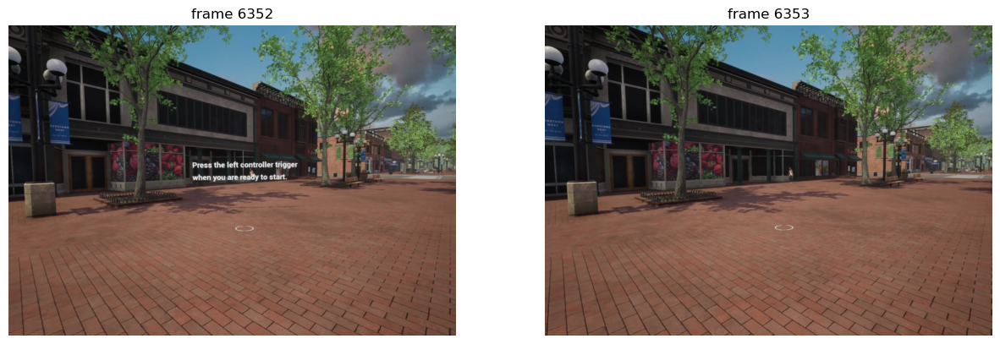

In [135]:
# find the needed frames 
print("FOR PERSON", pid, 'in VIDEO=', video_path)

frames = []
for i in [6352, 6353]:
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
    ret, frame = cap.read()
    if not ret:
        continue
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    frames.append((int(i), rgb))

fig, axs = plt.subplots(1, len(frames), figsize=(15, 5))
for ax, (i, fr) in zip(axs, frames):
    ax.imshow(fr)
    ax.set_title(f'frame {i}')
    ax.axis('off')
plt.show()

In [136]:
# check visually 
start = 176.558567
start_s1 = 378.235294
end_s1 = 389.028058

start_time = start
end_time = start + (end_s1 - start_s1)
output_path = f"../data/videodata/testPS.mp4"

command = [
    "ffmpeg",
    "-y",
    "-i", f'../data/videodata/videoraw/{filename}.mp4',
    "-ss", str(start_time), # 
    "-to", str(end_time), # 626967, 654767, 682567
    # "-avoid_negative_ts", "1",
    output_path
]

subprocess.run(command, stdout=subprocess.DEVNULL, stderr=subprocess.STDOUT)
print(f"Clipped frames {start_time}–{end_time} saved to {output_path}")

Clipped frames 176.558567–187.351331 saved to ../data/videodata/testPS.mp4


In [137]:
(0*60+10)*36

360

In [141]:
# Get fps and basic info
pid = 20
filename = f'P{pid}-2'

video_path = f'../data/videodata/videoraw/{filename}.mp4'
print('VIDEO=', video_path)
cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    print('Cannot open', video_path)
else:
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duration_sec = frame_count / fps if fps > 0 else None
    print(f'FPS={fps}, frames={frame_count}, duration(s)={duration_sec:.2f}')
# cap.release()

VIDEO= ../data/videodata/videoraw/P20-2.mp4
FPS=36.1998563038085, frames=875, duration(s)=24.17


FOR PERSON 20 in VIDEO= ../data/videodata/videoraw/P20-2.mp4


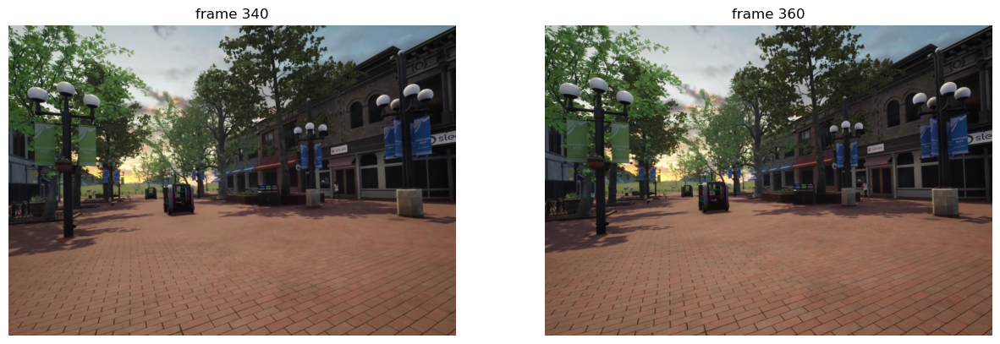

In [142]:
# find the needed frames 
print("FOR PERSON", pid, 'in VIDEO=', video_path)

frames = []
for i in [340, 360]:
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
    ret, frame = cap.read()
    if not ret:
        continue
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    frames.append((int(i), rgb))

fig, axs = plt.subplots(1, len(frames), figsize=(15, 5))
for ax, (i, fr) in zip(axs, frames):
    ax.imshow(fr)
    ax.set_title(f'frame {i}')
    ax.axis('off')
plt.show()

In [144]:
# check visually 
start = 9.426767
start_s1 = 16.236679
end_s1 = 27.018252

start_time = start
end_time = start + (end_s1 - start_s1)
output_path = f"../data/videodata/testPS.mp4"

command = [
    "ffmpeg",
    "-y",
    "-i", f'../data/videodata/videoraw/{filename}.mp4',
    "-ss", str(start_time), # 
    "-to", str(end_time), # 626967, 654767, 682567
    # "-avoid_negative_ts", "1",
    output_path
]

subprocess.run(command, stdout=subprocess.DEVNULL, stderr=subprocess.STDOUT)
print(f"Clipped frames {start_time}–{end_time} saved to {output_path}")

Clipped frames 9.426767–20.20834 saved to ../data/videodata/testPS.mp4


In [ ]:
import glob
import pandas as pd
def get_start_end_in_first_valid_trial(pid, sid):
    file = glob.glob(f'../data/vrdata/combined/P{pid}_*.csv')
    print(file)
    if len(file) != 1:
        raise ValueError(f"File error")
    # Get the first valid trial
    df = pd.read_csv(file[0])
    if not df[df['Scenario'] == sid].empty:
        start = df[df['Scenario'] == sid]['TimeElapsed'].min()
        end = df[df['Scenario'] == sid]['TimeElapsed'].max()
        return start, end
    raise ValueError(f"No valid trial for P{pid} in S{sid}")

In [159]:
start_s1, end_s1 = get_start_end_in_first_valid_trial(pid=20, sid=str(3))
start_s1, end_s1

['../data/vrdata/combined/P20_202511010139902.csv']


(16.236679, 27.018252)

## P23

In [184]:
(7*60+6)*36

15336

In [185]:
# Get fps and basic info
pid = 23
filename = f'P{pid}-1'

video_path = f'../data/videodata/videoraw/{filename}.mp4'
print('VIDEO=', video_path)
cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    print('Cannot open', video_path)
else:
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duration_sec = frame_count / fps if fps > 0 else None
    print(f'FPS={fps}, frames={frame_count}, duration(s)={duration_sec:.2f}')
# cap.release()

VIDEO= ../data/videodata/videoraw/P23-1.mp4
FPS=35.990560000359274, frames=24042, duration(s)=668.01


FOR PERSON 23 in VIDEO= ../data/videodata/videoraw/P23-1.mp4


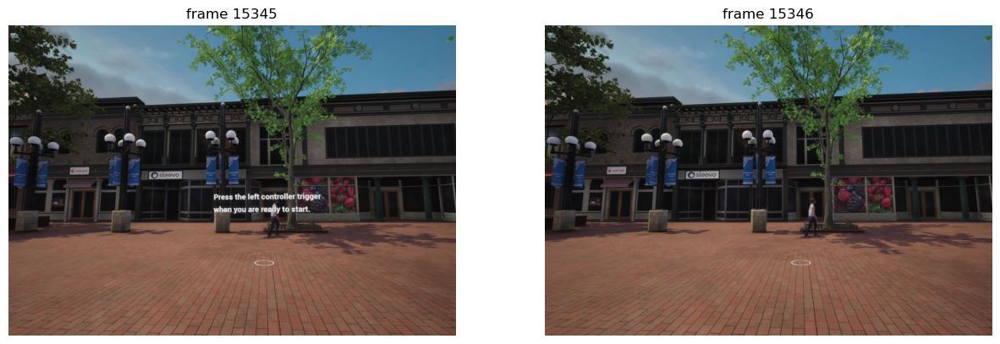

In [190]:
# find the needed frames 
print("FOR PERSON", pid, 'in VIDEO=', video_path)

frames = []
for i in [15345, 15346]:
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
    ret, frame = cap.read()
    if not ret:
        continue
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    frames.append((int(i), rgb))

fig, axs = plt.subplots(1, len(frames), figsize=(15, 5))
for ax, (i, fr) in zip(axs, frames):
    ax.imshow(fr)
    ax.set_title(f'frame {i}')
    ax.axis('off')
plt.show()

In [192]:
# check visually 
start = 426.457600
sid = 3
start_s1, end_s1 = get_start_end_in_first_valid_trial(pid=pid, sid=str(sid))

start_time = start
end_time = start + (end_s1 - start_s1)
output_path = f"../data/videodata/testPS.mp4"

command = [
    "ffmpeg",
    "-y",
    "-i", f'../data/videodata/videoraw/{filename}.mp4',
    "-ss", str(start_time), # 
    "-to", str(end_time), # 626967, 654767, 682567
    # "-avoid_negative_ts", "1",
    output_path
]

subprocess.run(command, stdout=subprocess.DEVNULL, stderr=subprocess.STDOUT)
print(f"Clipped frames {start_time}–{end_time} saved to {output_path}")

['../data/vrdata/combined/P23_202511014555424.csv']
Clipped frames 426.4576–432.157487 saved to ../data/videodata/testPS.mp4


In [193]:
(0*60+17)*36

612

In [195]:
# Get fps and basic info
pid = 23
filename = f'P{pid}-2'

video_path = f'../data/videodata/videoraw/{filename}.mp4'
print('VIDEO=', video_path)
cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    print('Cannot open', video_path)
else:
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duration_sec = frame_count / fps if fps > 0 else None
    print(f'FPS={fps}, frames={frame_count}, duration(s)={duration_sec:.2f}')
# cap.release()

VIDEO= ../data/videodata/videoraw/P23-2.mp4
FPS=36.09469096587431, frames=1692, duration(s)=46.88


FOR PERSON 23 in VIDEO= ../data/videodata/videoraw/P23-2.mp4


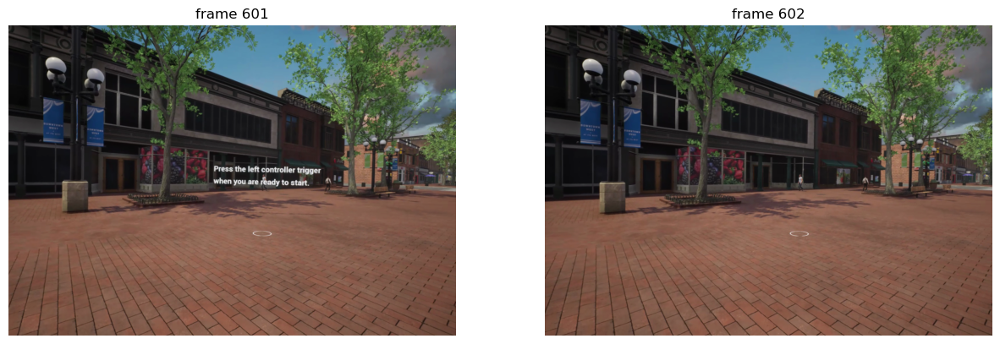

In [200]:
# find the needed frames 
print("FOR PERSON", pid, 'in VIDEO=', video_path)

frames = []
for i in [601, 602]:
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
    ret, frame = cap.read()
    if not ret:
        continue
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    frames.append((int(i), rgb))

fig, axs = plt.subplots(1, len(frames), figsize=(15, 5))
for ax, (i, fr) in zip(axs, frames):
    ax.imshow(fr)
    ax.set_title(f'frame {i}')
    ax.axis('off')
plt.show()

In [202]:
# check visually 
start = 16.735767
sid = 1
start_s1, end_s1 = get_start_end_in_first_valid_trial(pid=pid, sid=str(sid))

start_time = start
end_time = start + (end_s1 - start_s1)
output_path = f"../data/videodata/testPS.mp4"

command = [
    "ffmpeg",
    "-y",
    "-i", f'../data/videodata/videoraw/{filename}.mp4',
    "-ss", str(start_time), # 
    "-to", str(end_time), # 626967, 654767, 682567
    # "-avoid_negative_ts", "1",
    output_path
]

subprocess.run(command, stdout=subprocess.DEVNULL, stderr=subprocess.STDOUT)
print(f"Clipped frames {start_time}–{end_time} saved to {output_path}")

['../data/vrdata/combined/P23_202511014555424.csv']
Clipped frames 16.735767–23.476687 saved to ../data/videodata/testPS.mp4


## P24

In [203]:
(3*60+59)*36

8604

In [204]:
# Get fps and basic info
pid = 24
filename = f'P{pid}-1'

video_path = f'../data/videodata/videoraw/{filename}.mp4'
print('VIDEO=', video_path)
cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    print('Cannot open', video_path)
else:
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duration_sec = frame_count / fps if fps > 0 else None
    print(f'FPS={fps}, frames={frame_count}, duration(s)={duration_sec:.2f}')
# cap.release()

VIDEO= ../data/videodata/videoraw/P24-1.mp4
FPS=35.99304741594772, frames=18258, duration(s)=507.26


FOR PERSON 24 in VIDEO= ../data/videodata/videoraw/P24-1.mp4


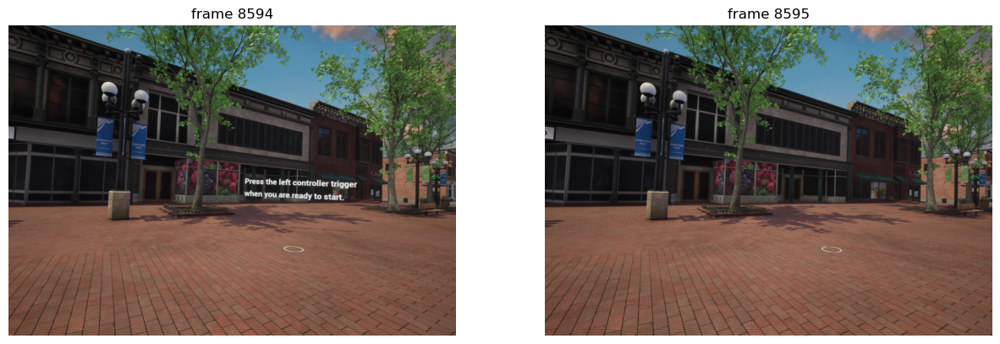

In [208]:
# find the needed frames 
print("FOR PERSON", pid, 'in VIDEO=', video_path)

frames = []
for i in [8594, 8595]:
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
    ret, frame = cap.read()
    if not ret:
        continue
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    frames.append((int(i), rgb))

fig, axs = plt.subplots(1, len(frames), figsize=(15, 5))
for ax, (i, fr) in zip(axs, frames):
    ax.imshow(fr)
    ax.set_title(f'frame {i}')
    ax.axis('off')
plt.show()

In [209]:
# check visually 
start = 238.837267
sid = 1
start_s1, end_s1 = get_start_end_in_first_valid_trial(pid=pid, sid=str(sid))
print(start_s1, end_s1)

start_time = start
end_time = start + (end_s1 - start_s1)
output_path = f"../data/videodata/testPS.mp4"

command = [
    "ffmpeg",
    "-y",
    "-i", f'../data/videodata/videoraw/{filename}.mp4',
    "-ss", str(start_time), # 
    "-to", str(end_time), # 626967, 654767, 682567
    # "-avoid_negative_ts", "1",
    output_path
]

subprocess.run(command, stdout=subprocess.DEVNULL, stderr=subprocess.STDOUT)
print(f"Clipped frames {start_time}–{end_time} saved to {output_path}")

['../data/vrdata/combined/P24_202511015455563.csv']
Clipped frames 238.837267–249.07374199999998 saved to ../data/videodata/testPS.mp4


In [210]:
(0*60+11)*36

396

In [211]:
# Get fps and basic info
pid = 24
filename = f'P{pid}-2'

video_path = f'../data/videodata/videoraw/{filename}.mp4'
print('VIDEO=', video_path)
cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    print('Cannot open', video_path)
else:
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duration_sec = frame_count / fps if fps > 0 else None
    print(f'FPS={fps}, frames={frame_count}, duration(s)={duration_sec:.2f}')
# cap.release()

VIDEO= ../data/videodata/videoraw/P24-2.mp4
FPS=36.08037149557517, frames=1937, duration(s)=53.69


FOR PERSON 24 in VIDEO= ../data/videodata/videoraw/P24-2.mp4


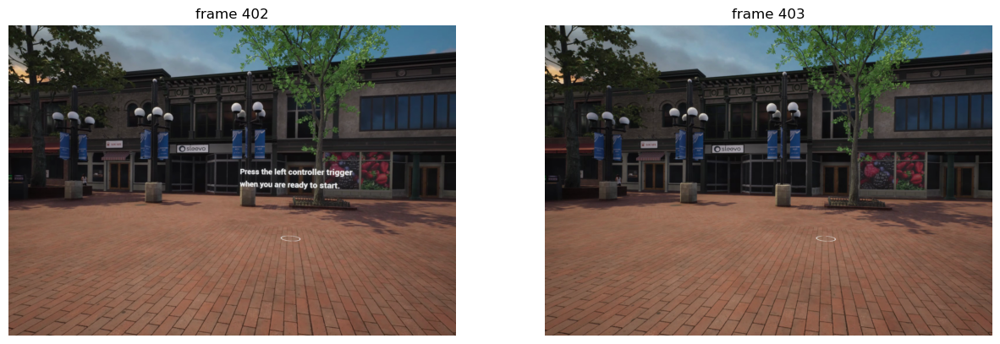

In [215]:
# find the needed frames 
print("FOR PERSON", pid, 'in VIDEO=', video_path)

frames = []
for i in [402, 403]:
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
    ret, frame = cap.read()
    if not ret:
        continue
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    frames.append((int(i), rgb))

fig, axs = plt.subplots(1, len(frames), figsize=(15, 5))
for ax, (i, fr) in zip(axs, frames):
    ax.imshow(fr)
    ax.set_title(f'frame {i}')
    ax.axis('off')
plt.show()

In [217]:
# check visually 
start = 11.202767
sid = 2
start_s1, end_s1 = get_start_end_in_first_valid_trial(pid=pid, sid=str(sid))
print(start_s1, end_s1)

start_time = start
end_time = start + (end_s1 - start_s1)
output_path = f"../data/videodata/testPS.mp4"

command = [
    "ffmpeg",
    "-y",
    "-i", f'../data/videodata/videoraw/{filename}.mp4',
    "-ss", str(start_time), # 
    "-to", str(end_time), # 626967, 654767, 682567
    # "-avoid_negative_ts", "1",
    output_path
]

subprocess.run(command, stdout=subprocess.DEVNULL, stderr=subprocess.STDOUT)
print(f"Clipped frames {start_time}–{end_time} saved to {output_path}")

['../data/vrdata/combined/P24_202511015455563.csv']
17.995284 27.798099
Clipped frames 11.202767–21.005581999999997 saved to ../data/videodata/testPS.mp4


In [219]:
(0*60+15)*36

540

In [218]:
# Get fps and basic info
pid = 24
filename = f'P{pid}-3'

video_path = f'../data/videodata/videoraw/{filename}.mp4'
print('VIDEO=', video_path)
cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    print('Cannot open', video_path)
else:
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duration_sec = frame_count / fps if fps > 0 else None
    print(f'FPS={fps}, frames={frame_count}, duration(s)={duration_sec:.2f}')
# cap.release()

VIDEO= ../data/videodata/videoraw/P24-3.mp4
FPS=36.162625555150576, frames=1055, duration(s)=29.17


FOR PERSON 24 in VIDEO= ../data/videodata/videoraw/P24-3.mp4


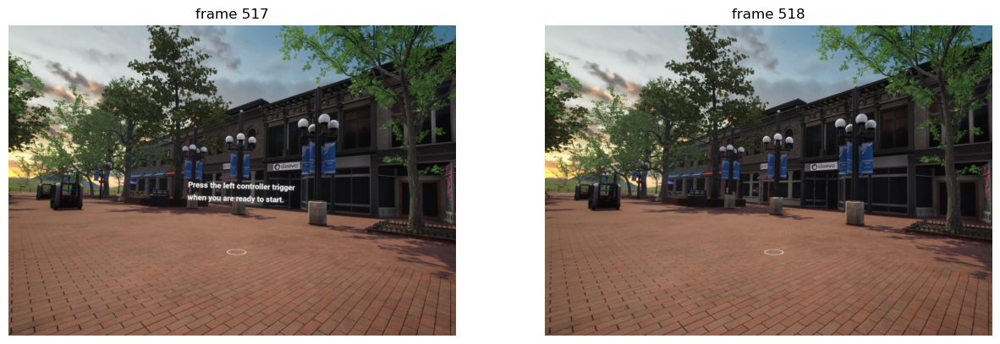

In [227]:
# find the needed frames 
print("FOR PERSON", pid, 'in VIDEO=', video_path)

frames = []
for i in [517, 518]:
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
    ret, frame = cap.read()
    if not ret:
        continue
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    frames.append((int(i), rgb))

fig, axs = plt.subplots(1, len(frames), figsize=(15, 5))
for ax, (i, fr) in zip(axs, frames):
    ax.imshow(fr)
    ax.set_title(f'frame {i}')
    ax.axis('off')
plt.show()

In [228]:
# check visually 
start = 14.375333
sid = 8
start_s1, end_s1 = get_start_end_in_first_valid_trial(pid=pid, sid=str(sid))
print(start_s1, end_s1)

start_time = start
end_time = start + (end_s1 - start_s1)
output_path = f"../data/videodata/testPS.mp4"

command = [
    "ffmpeg",
    "-y",
    "-i", f'../data/videodata/videoraw/{filename}.mp4',
    "-ss", str(start_time), # 
    "-to", str(end_time), # 626967, 654767, 682567
    # "-avoid_negative_ts", "1",
    output_path
]

subprocess.run(command, stdout=subprocess.DEVNULL, stderr=subprocess.STDOUT)
print(f"Clipped frames {start_time}–{end_time} saved to {output_path}")

['../data/vrdata/combined/P24_202511015455563.csv']
19.723624 31.324885
Clipped frames 14.375333–25.976594 saved to ../data/videodata/testPS.mp4


## P25 

In [232]:
(5*60+10)*36

11160

In [229]:
# Get fps and basic info
pid = 25
filename = f'P{pid}-1'

video_path = f'../data/videodata/videoraw/{filename}.mp4'
print('VIDEO=', video_path)
cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    print('Cannot open', video_path)
else:
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duration_sec = frame_count / fps if fps > 0 else None
    print(f'FPS={fps}, frames={frame_count}, duration(s)={duration_sec:.2f}')
# cap.release()

VIDEO= ../data/videodata/videoraw/P25-1.mp4
FPS=35.990593552113815, frames=23938, duration(s)=665.12


FOR PERSON 25 in VIDEO= ../data/videodata/videoraw/P25-1.mp4


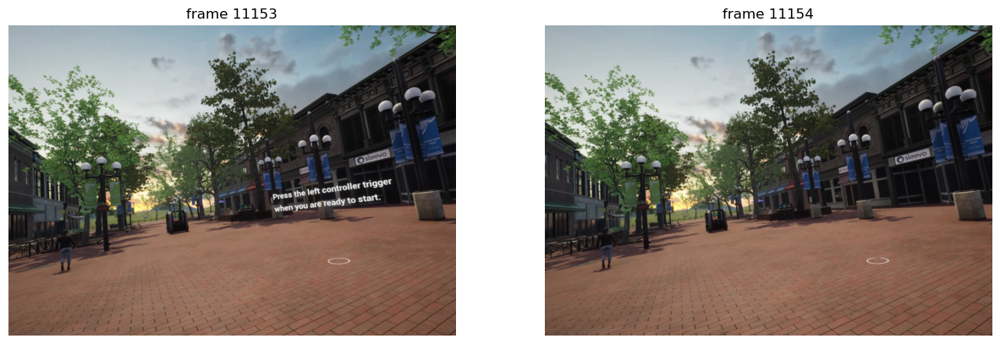

In [235]:
# find the needed frames 
print("FOR PERSON", pid, 'in VIDEO=', video_path)

frames = []
for i in [11153, 11154]:
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
    ret, frame = cap.read()
    if not ret:
        continue
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    frames.append((int(i), rgb))

fig, axs = plt.subplots(1, len(frames), figsize=(15, 5))
for ax, (i, fr) in zip(axs, frames):
    ax.imshow(fr)
    ax.set_title(f'frame {i}')
    ax.axis('off')
plt.show()

In [236]:
# check visually 
start = 309.954467
sid = 1
start_s1, end_s1 = get_start_end_in_first_valid_trial(pid=pid, sid=str(sid))
print(start_s1, end_s1)

start_time = start
end_time = start + (end_s1 - start_s1)
output_path = f"../data/videodata/testPS.mp4"

command = [
    "ffmpeg",
    "-y",
    "-i", f'../data/videodata/videoraw/{filename}.mp4',
    "-ss", str(start_time), # 
    "-to", str(end_time), # 626967, 654767, 682567
    # "-avoid_negative_ts", "1",
    output_path
]

subprocess.run(command, stdout=subprocess.DEVNULL, stderr=subprocess.STDOUT)
print(f"Clipped frames {start_time}–{end_time} saved to {output_path}")

['../data/vrdata/combined/P25_2025110161322537.csv']
319.759689 330.843723
Clipped frames 309.954467–321.03850100000005 saved to ../data/videodata/testPS.mp4


In [237]:
(0*60+22)*36

792

In [238]:
# Get fps and basic info
pid = 25
filename = f'P{pid}-2'

video_path = f'../data/videodata/videoraw/{filename}.mp4'
print('VIDEO=', video_path)
cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    print('Cannot open', video_path)
else:
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duration_sec = frame_count / fps if fps > 0 else None
    print(f'FPS={fps}, frames={frame_count}, duration(s)={duration_sec:.2f}')
# cap.release()

VIDEO= ../data/videodata/videoraw/P25-2.mp4
FPS=36.11923247281089, frames=1389, duration(s)=38.46


FOR PERSON 25 in VIDEO= ../data/videodata/videoraw/P25-2.mp4


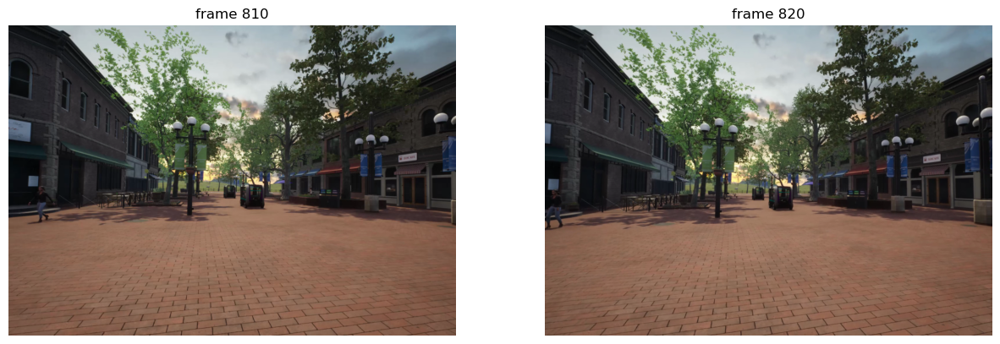

In [240]:
# find the needed frames 
print("FOR PERSON", pid, 'in VIDEO=', video_path)

frames = []
for i in [810, 820]:
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
    ret, frame = cap.read()
    if not ret:
        continue
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    frames.append((int(i), rgb))

fig, axs = plt.subplots(1, len(frames), figsize=(15, 5))
for ax, (i, fr) in zip(axs, frames):
    ax.imshow(fr)
    ax.set_title(f'frame {i}')
    ax.axis('off')
plt.show()

In [245]:
# check visually 
start = 22.629300
sid = 12
start_s1, end_s1 = get_start_end_in_first_valid_trial(pid=pid, sid=str(sid))
print(start_s1, end_s1)

start_time = start
end_time = start + (end_s1 - start_s1)
output_path = f"../data/videodata/testPS.mp4"

command = [
    "ffmpeg",
    "-y",
    "-i", f'../data/videodata/videoraw/{filename}.mp4',
    "-ss", str(start_time), # 
    "-to", str(end_time), # 626967, 654767, 682567
    # "-avoid_negative_ts", "1",
    output_path
]

subprocess.run(command, stdout=subprocess.DEVNULL, stderr=subprocess.STDOUT)
print(f"Clipped frames {start_time}–{end_time} saved to {output_path}")

['../data/vrdata/combined/P25_2025110161322537.csv']
27.57929 38.319693
Clipped frames 22.6293–33.369703 saved to ../data/videodata/testPS.mp4


## P26 

In [246]:
(3*60+36)*36

7776

In [248]:
# Get fps and basic info
pid = 26
filename = f'P{pid}-1'

video_path = f'../data/videodata/videoraw/{filename}.mp4'
print('VIDEO=', video_path)
cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    print('Cannot open', video_path)
else:
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duration_sec = frame_count / fps if fps > 0 else None
    print(f'FPS={fps}, frames={frame_count}, duration(s)={duration_sec:.2f}')
# cap.release()

VIDEO= ../data/videodata/videoraw/P26-1.mp4
FPS=35.992886642869, frames=18499, duration(s)=513.96


FOR PERSON 26 in VIDEO= ../data/videodata/videoraw/P26-1.mp4


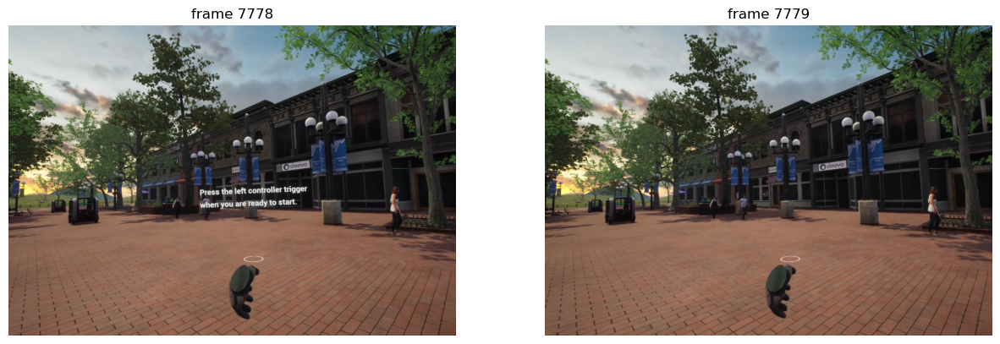

In [251]:
# find the needed frames 
print("FOR PERSON", pid, 'in VIDEO=', video_path)

frames = []
for i in [7778, 7779]:
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
    ret, frame = cap.read()
    if not ret:
        continue
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    frames.append((int(i), rgb))

fig, axs = plt.subplots(1, len(frames), figsize=(15, 5))
for ax, (i, fr) in zip(axs, frames):
    ax.imshow(fr)
    ax.set_title(f'frame {i}')
    ax.axis('off')
plt.show()

In [252]:
# check visually 
start = 216.165533
sid = 1
start_s1, end_s1 = get_start_end_in_first_valid_trial(pid=pid, sid=str(sid))
print(start_s1, end_s1)

start_time = start
end_time = start + (end_s1 - start_s1)
output_path = f"../data/videodata/testPS.mp4"

command = [
    "ffmpeg",
    "-y",
    "-i", f'../data/videodata/videoraw/{filename}.mp4',
    "-ss", str(start_time), # 
    "-to", str(end_time), # 626967, 654767, 682567
    # "-avoid_negative_ts", "1",
    output_path
]

subprocess.run(command, stdout=subprocess.DEVNULL, stderr=subprocess.STDOUT)
print(f"Clipped frames {start_time}–{end_time} saved to {output_path}")

['../data/vrdata/combined/P26_202511017318590.csv']
230.111398 247.005562
Clipped frames 216.165533–233.059697 saved to ../data/videodata/testPS.mp4


In [254]:
(0*60+36)*36

1296

In [253]:
# Get fps and basic info
pid = 26
filename = f'P{pid}-2'

video_path = f'../data/videodata/videoraw/{filename}.mp4'
print('VIDEO=', video_path)
cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    print('Cannot open', video_path)
else:
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duration_sec = frame_count / fps if fps > 0 else None
    print(f'FPS={fps}, frames={frame_count}, duration(s)={duration_sec:.2f}')
# cap.release()

VIDEO= ../data/videodata/videoraw/P26-2.mp4
FPS=36.083340629675384, frames=1882, duration(s)=52.16


FOR PERSON 26 in VIDEO= ../data/videodata/videoraw/P26-2.mp4


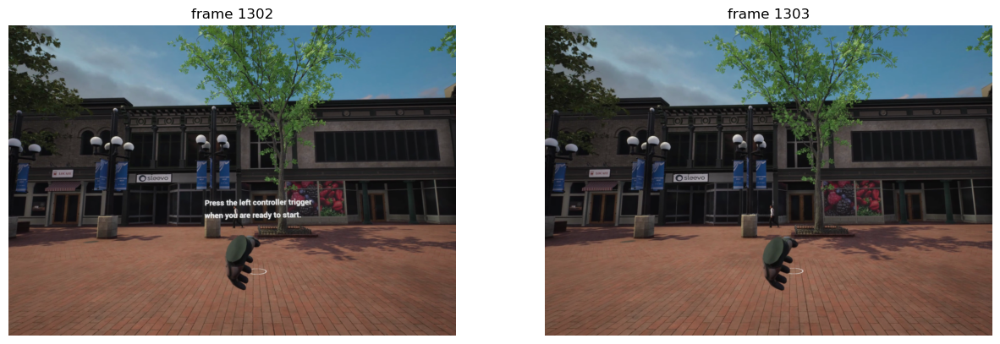

In [259]:
# find the needed frames 
print("FOR PERSON", pid, 'in VIDEO=', video_path)

frames = []
for i in [1302, 1303]:
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
    ret, frame = cap.read()
    if not ret:
        continue
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    frames.append((int(i), rgb))

fig, axs = plt.subplots(1, len(frames), figsize=(15, 5))
for ax, (i, fr) in zip(axs, frames):
    ax.imshow(fr)
    ax.set_title(f'frame {i}')
    ax.axis('off')
plt.show()

In [260]:
# check visually 
start = 36.183833
sid = 3
start_s1, end_s1 = get_start_end_in_first_valid_trial(pid=pid, sid=str(sid))
print(start_s1, end_s1)

start_time = start
end_time = start + (end_s1 - start_s1)
output_path = f"../data/videodata/testPS.mp4"

command = [
    "ffmpeg",
    "-y",
    "-i", f'../data/videodata/videoraw/{filename}.mp4',
    "-ss", str(start_time), # 
    "-to", str(end_time), # 626967, 654767, 682567
    # "-avoid_negative_ts", "1",
    output_path
]

subprocess.run(command, stdout=subprocess.DEVNULL, stderr=subprocess.STDOUT)
print(f"Clipped frames {start_time}–{end_time} saved to {output_path}")

['../data/vrdata/combined/P26_202511017318590.csv']
42.548515 54.699586
Clipped frames 36.183833–48.334903999999995 saved to ../data/videodata/testPS.mp4


In [262]:
(0*60+16)*36

576

In [261]:
# Get fps and basic info
pid = 26
filename = f'P{pid}-4'

video_path = f'../data/videodata/videoraw/{filename}.mp4'
print('VIDEO=', video_path)
cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    print('Cannot open', video_path)
else:
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duration_sec = frame_count / fps if fps > 0 else None
    print(f'FPS={fps}, frames={frame_count}, duration(s)={duration_sec:.2f}')
# cap.release()

VIDEO= ../data/videodata/videoraw/P26-4.mp4
FPS=36.03908946034876, frames=3353, duration(s)=93.04


FOR PERSON 26 in VIDEO= ../data/videodata/videoraw/P26-4.mp4


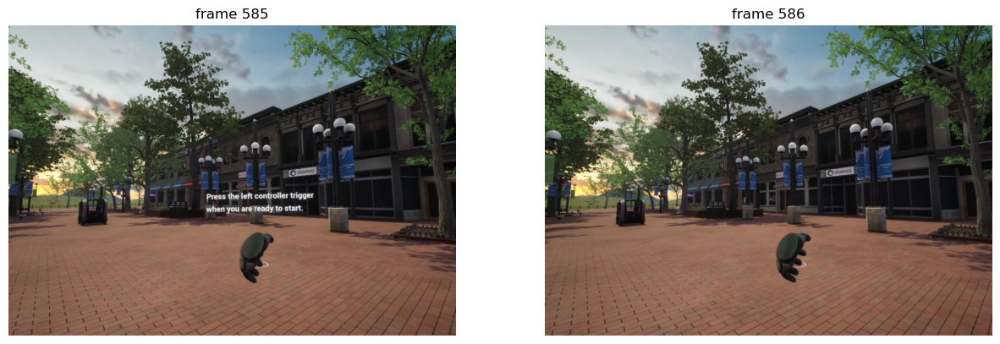

In [266]:
# find the needed frames 
print("FOR PERSON", pid, 'in VIDEO=', video_path)

frames = []
for i in [585, 586]:
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
    ret, frame = cap.read()
    if not ret:
        continue
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    frames.append((int(i), rgb))

fig, axs = plt.subplots(1, len(frames), figsize=(15, 5))
for ax, (i, fr) in zip(axs, frames):
    ax.imshow(fr)
    ax.set_title(f'frame {i}')
    ax.axis('off')
plt.show()

In [268]:
# check visually 
start = 16.319733
sid = 10
start_s1, end_s1 = get_start_end_in_first_valid_trial(pid=pid, sid=str(sid))
print(start_s1, end_s1)

start_time = start
end_time = start + (end_s1 - start_s1)
output_path = f"../data/videodata/testPS.mp4"

command = [
    "ffmpeg",
    "-y",
    "-i", f'../data/videodata/videoraw/{filename}.mp4',
    "-ss", str(start_time), # 
    "-to", str(end_time), # 626967, 654767, 682567
    # "-avoid_negative_ts", "1",
    output_path
]

subprocess.run(command, stdout=subprocess.DEVNULL, stderr=subprocess.STDOUT)
print(f"Clipped frames {start_time}–{end_time} saved to {output_path}")

['../data/vrdata/combined/P26_202511017318590.csv']
20.022151 33.924742
Clipped frames 16.319733–30.222324 saved to ../data/videodata/testPS.mp4


## P27

In [269]:
(6*60+55)*36

14940

In [270]:
# Get fps and basic info
pid = 27
filename = f'P{pid}-1'

video_path = f'../data/videodata/videoraw/{filename}.mp4'
print('VIDEO=', video_path)
cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    print('Cannot open', video_path)
else:
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duration_sec = frame_count / fps if fps > 0 else None
    print(f'FPS={fps}, frames={frame_count}, duration(s)={duration_sec:.2f}')
# cap.release()

VIDEO= ../data/videodata/videoraw/P27-1.mp4
FPS=35.99057078596315, frames=23955, duration(s)=665.59


FOR PERSON 27 in VIDEO= ../data/videodata/videoraw/P27-1.mp4


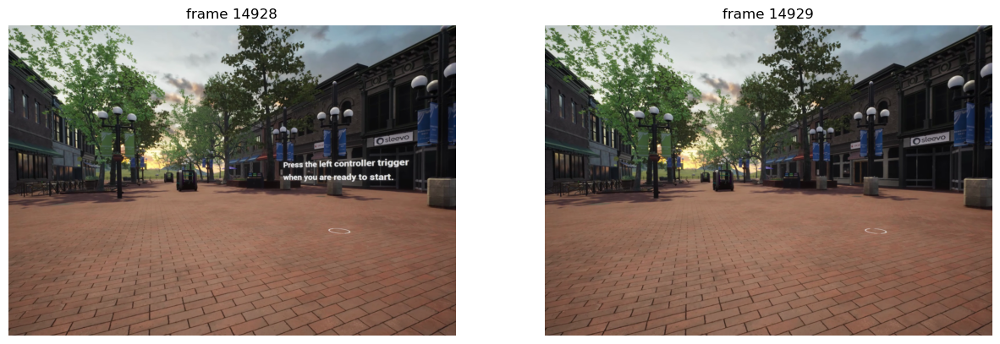

In [276]:
# find the needed frames 
print("FOR PERSON", pid, 'in VIDEO=', video_path)

frames = []
for i in [14928, 14929]:
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
    ret, frame = cap.read()
    if not ret:
        continue
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    frames.append((int(i), rgb))

fig, axs = plt.subplots(1, len(frames), figsize=(15, 5))
for ax, (i, fr) in zip(axs, frames):
    ax.imshow(fr)
    ax.set_title(f'frame {i}')
    ax.axis('off')
plt.show()

In [277]:
# check visually 
start = 414.873100
sid = 1
start_s1, end_s1 = get_start_end_in_first_valid_trial(pid=pid, sid=str(sid))
print(start_s1, end_s1)

start_time = start
end_time = start + (end_s1 - start_s1)
output_path = f"../data/videodata/testPS.mp4"

command = [
    "ffmpeg",
    "-y",
    "-i", f'../data/videodata/videoraw/{filename}.mp4',
    "-ss", str(start_time), # 
    "-to", str(end_time), # 626967, 654767, 682567
    # "-avoid_negative_ts", "1",
    output_path
]

subprocess.run(command, stdout=subprocess.DEVNULL, stderr=subprocess.STDOUT)
print(f"Clipped frames {start_time}–{end_time} saved to {output_path}")

['../data/vrdata/combined/P27_202511194845442.csv']
632.257157 646.14777
Clipped frames 414.8731–428.76371300000005 saved to ../data/videodata/testPS.mp4


In [278]:
(0*60+20)*36

720

In [280]:
# Get fps and basic info
pid = 27
filename = f'P{pid}-2'

video_path = f'../data/videodata/videoraw/{filename}.mp4'
print('VIDEO=', video_path)
cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    print('Cannot open', video_path)
else:
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duration_sec = frame_count / fps if fps > 0 else None
    print(f'FPS={fps}, frames={frame_count}, duration(s)={duration_sec:.2f}')
# cap.release()

VIDEO= ../data/videodata/videoraw/P27-2.mp4
FPS=36.121733419488784, frames=1364, duration(s)=37.76


FOR PERSON 27 in VIDEO= ../data/videodata/videoraw/P27-2.mp4


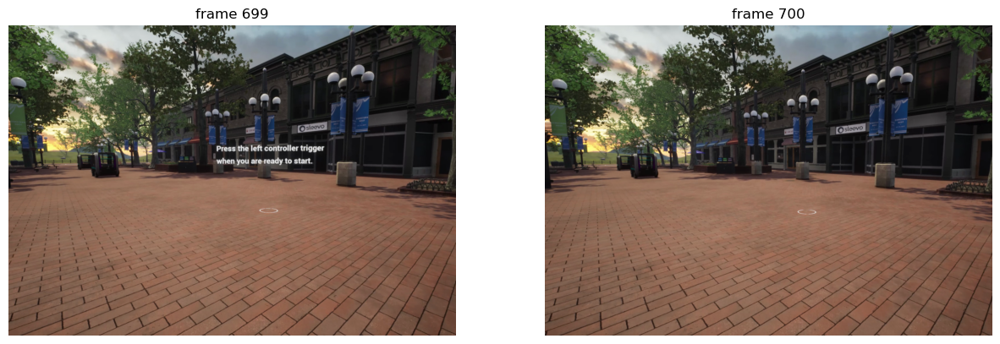

In [285]:
# find the needed frames 
print("FOR PERSON", pid, 'in VIDEO=', video_path)

frames = []
for i in [699, 700]:
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
    ret, frame = cap.read()
    if not ret:
        continue
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    frames.append((int(i), rgb))

fig, axs = plt.subplots(1, len(frames), figsize=(15, 5))
for ax, (i, fr) in zip(axs, frames):
    ax.imshow(fr)
    ax.set_title(f'frame {i}')
    ax.axis('off')
plt.show()

In [286]:
# check visually 
start = 19.459000
sid = 5
start_s1, end_s1 = get_start_end_in_first_valid_trial(pid=pid, sid=str(sid))
print(start_s1, end_s1)

start_time = start
end_time = start + (end_s1 - start_s1)
output_path = f"../data/videodata/testPS.mp4"

command = [
    "ffmpeg",
    "-y",
    "-i", f'../data/videodata/videoraw/{filename}.mp4',
    "-ss", str(start_time), # 
    "-to", str(end_time), # 626967, 654767, 682567
    # "-avoid_negative_ts", "1",
    output_path
]

subprocess.run(command, stdout=subprocess.DEVNULL, stderr=subprocess.STDOUT)
print(f"Clipped frames {start_time}–{end_time} saved to {output_path}")

['../data/vrdata/combined/P27_202511194845442.csv']
25.013677 38.798008
Clipped frames 19.459–33.243331 saved to ../data/videodata/testPS.mp4


In [287]:
(0*60+10)*36

360

In [289]:
# Get fps and basic info
pid = 27
filename = f'P{pid}-3'

video_path = f'../data/videodata/videoraw/{filename}.mp4'
print('VIDEO=', video_path)
cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    print('Cannot open', video_path)
else:
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duration_sec = frame_count / fps if fps > 0 else None
    print(f'FPS={fps}, frames={frame_count}, duration(s)={duration_sec:.2f}')
# cap.release()

VIDEO= ../data/videodata/videoraw/P27-3.mp4
FPS=36.20393902228291, frames=859, duration(s)=23.73


FOR PERSON 27 in VIDEO= ../data/videodata/videoraw/P27-3.mp4


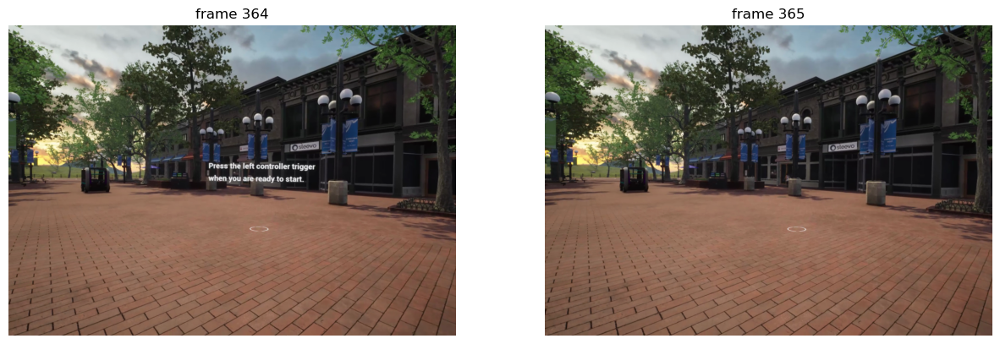

In [294]:
# find the needed frames 
print("FOR PERSON", pid, 'in VIDEO=', video_path)

frames = []
for i in [364, 365]:
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
    ret, frame = cap.read()
    if not ret:
        continue
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    frames.append((int(i), rgb))

fig, axs = plt.subplots(1, len(frames), figsize=(15, 5))
for ax, (i, fr) in zip(axs, frames):
    ax.imshow(fr)
    ax.set_title(f'frame {i}')
    ax.axis('off')
plt.show()

In [295]:
# check visually 
start = 10.146233
sid = 7
start_s1, end_s1 = get_start_end_in_first_valid_trial(pid=pid, sid=str(sid))
print(start_s1, end_s1)

start_time = start
end_time = start + (end_s1 - start_s1)
output_path = f"../data/videodata/testPS.mp4"

command = [
    "ffmpeg",
    "-y",
    "-i", f'../data/videodata/videoraw/{filename}.mp4',
    "-ss", str(start_time), # 
    "-to", str(end_time), # 626967, 654767, 682567
    # "-avoid_negative_ts", "1",
    output_path
]

subprocess.run(command, stdout=subprocess.DEVNULL, stderr=subprocess.STDOUT)
print(f"Clipped frames {start_time}–{end_time} saved to {output_path}")

['../data/vrdata/combined/P27_202511194845442.csv']
14.82042 25.213028
Clipped frames 10.146233–20.538841 saved to ../data/videodata/testPS.mp4


## P29

In [296]:
(0*60+16)*36

576

In [297]:
# Get fps and basic info
pid = 29
filename = f'P{pid}-1'

video_path = f'../data/videodata/videoraw/{filename}.mp4'
print('VIDEO=', video_path)
cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    print('Cannot open', video_path)
else:
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duration_sec = frame_count / fps if fps > 0 else None
    print(f'FPS={fps}, frames={frame_count}, duration(s)={duration_sec:.2f}')
# cap.release()

VIDEO= ../data/videodata/videoraw/P29-1.mp4
FPS=35.997169245761505, frames=13042, duration(s)=362.31


FOR PERSON 29 in VIDEO= ../data/videodata/videoraw/P29-1.mp4


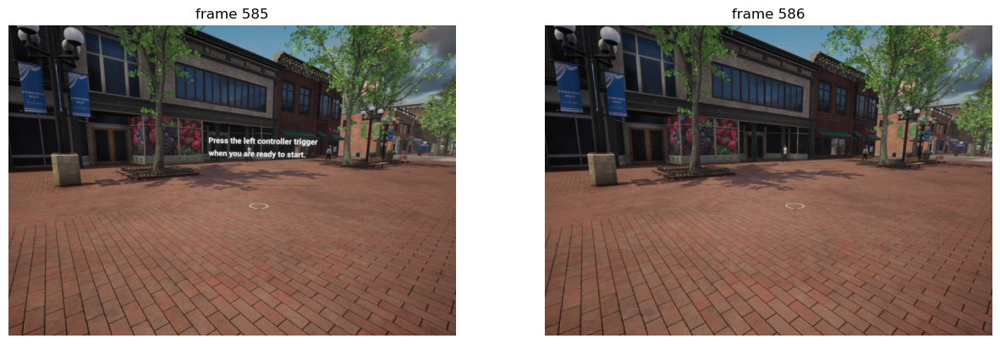

In [301]:
# find the needed frames 
print("FOR PERSON", pid, 'in VIDEO=', video_path)

frames = []
for i in [585, 586]:
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
    ret, frame = cap.read()
    if not ret:
        continue
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    frames.append((int(i), rgb))

fig, axs = plt.subplots(1, len(frames), figsize=(15, 5))
for ax, (i, fr) in zip(axs, frames):
    ax.imshow(fr)
    ax.set_title(f'frame {i}')
    ax.axis('off')
plt.show()

In [304]:
# check visually 
start = 16.317267
sid = 2
start_s1, end_s1 = get_start_end_in_first_valid_trial(pid=pid, sid=str(sid))
print(start_s1, end_s1)

start_time = start
end_time = start + (end_s1 - start_s1)
output_path = f"../data/videodata/testPS.mp4"

command = [
    "ffmpeg",
    "-y",
    "-i", f'../data/videodata/videoraw/{filename}.mp4',
    "-ss", str(start_time), # 
    "-to", str(end_time), # 626967, 654767, 682567
    # "-avoid_negative_ts", "1",
    output_path
]

subprocess.run(command, stdout=subprocess.DEVNULL, stderr=subprocess.STDOUT)
print(f"Clipped frames {start_time}–{end_time} saved to {output_path}")

['../data/vrdata/combined/P29_20251111435533.csv']
24.324352 30.734625
Clipped frames 16.317267–22.72754 saved to ../data/videodata/testPS.mp4


In [334]:
(0*60+22)*36

792

In [335]:
# Get fps and basic info
pid = 29
filename = f'P{pid}-2'

video_path = f'../data/videodata/videoraw/{filename}.mp4'
print('VIDEO=', video_path)
cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    print('Cannot open', video_path)
else:
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duration_sec = frame_count / fps if fps > 0 else None
    print(f'FPS={fps}, frames={frame_count}, duration(s)={duration_sec:.2f}')
# cap.release()

VIDEO= ../data/videodata/videoraw/P29-2.mp4
FPS=36.10957588569974, frames=1494, duration(s)=41.37


FOR PERSON 29 in VIDEO= ../data/videodata/videoraw/P29-2.mp4


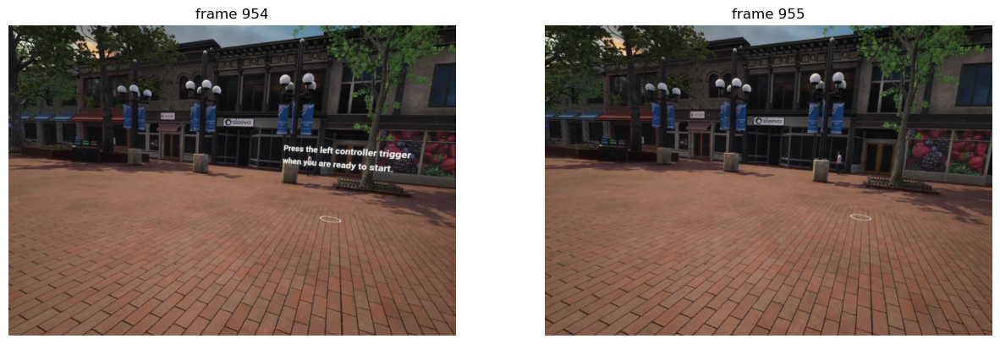

In [336]:
# find the needed frames 
print("FOR PERSON", pid, 'in VIDEO=', video_path)

frames = []
for i in [954, 955]:
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
    ret, frame = cap.read()
    if not ret:
        continue
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    frames.append((int(i), rgb))

fig, axs = plt.subplots(1, len(frames), figsize=(15, 5))
for ax, (i, fr) in zip(axs, frames):
    ax.imshow(fr)
    ax.set_title(f'frame {i}')
    ax.axis('off')
plt.show()

In [337]:
# check visually 
start = 26.548400
sid = 1
start_s1, end_s1 = get_start_end_in_first_valid_trial(pid=pid, sid=str(sid))
print(start_s1, end_s1)

start_time = start
end_time = start + (end_s1 - start_s1)
output_path = f"../data/videodata/testPS.mp4"

command = [
    "ffmpeg",
    "-y",
    "-i", f'../data/videodata/videoraw/{filename}.mp4',
    "-ss", str(start_time), # 
    "-to", str(end_time), # 626967, 654767, 682567
    # "-avoid_negative_ts", "1",
    output_path
]

subprocess.run(command, stdout=subprocess.DEVNULL, stderr=subprocess.STDOUT)
print(f"Clipped frames {start_time}–{end_time} saved to {output_path}")

['../data/vrdata/combined/P29_20251111435533.csv']
31.150428 42.554753
Clipped frames 26.5484–37.952725 saved to ../data/videodata/testPS.mp4


In [338]:
(0*60+21)*36

756

In [339]:
# Get fps and basic info
pid = 29
filename = f'P{pid}-3'

video_path = f'../data/videodata/videoraw/{filename}.mp4'
print('VIDEO=', video_path)
cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    print('Cannot open', video_path)
else:
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duration_sec = frame_count / fps if fps > 0 else None
    print(f'FPS={fps}, frames={frame_count}, duration(s)={duration_sec:.2f}')
# cap.release()

VIDEO= ../data/videodata/videoraw/P29-3.mp4
FPS=36.135660262624654, frames=1240, duration(s)=34.32


FOR PERSON 29 in VIDEO= ../data/videodata/videoraw/P29-3.mp4


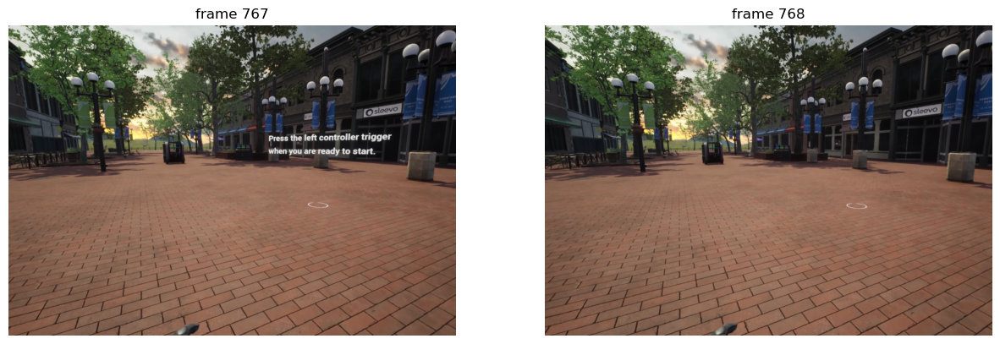

In [340]:
# find the needed frames 
print("FOR PERSON", pid, 'in VIDEO=', video_path)

frames = []
for i in [767, 768]:
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
    ret, frame = cap.read()
    if not ret:
        continue
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    frames.append((int(i), rgb))

fig, axs = plt.subplots(1, len(frames), figsize=(15, 5))
for ax, (i, fr) in zip(axs, frames):
    ax.imshow(fr)
    ax.set_title(f'frame {i}')
    ax.axis('off')
plt.show()

In [341]:
# check visually 
start = 21.322500
sid = 7
start_s1, end_s1 = get_start_end_in_first_valid_trial(pid=pid, sid=str(sid))
print(start_s1, end_s1)

start_time = start
end_time = start + (end_s1 - start_s1)
output_path = f"../data/videodata/testPS.mp4"

command = [
    "ffmpeg",
    "-y",
    "-i", f'../data/videodata/videoraw/{filename}.mp4',
    "-ss", str(start_time), # 
    "-to", str(end_time), # 626967, 654767, 682567
    # "-avoid_negative_ts", "1",
    output_path
]

subprocess.run(command, stdout=subprocess.DEVNULL, stderr=subprocess.STDOUT)
print(f"Clipped frames {start_time}–{end_time} saved to {output_path}")

['../data/vrdata/combined/P29_20251111435533.csv']
26.087705 35.672809
Clipped frames 21.3225–30.907604000000003 saved to ../data/videodata/testPS.mp4


## P30

In [342]:
(4*60+54)*36

10584

In [343]:
# Get fps and basic info
pid = 30
filename = f'P{pid}-1'

video_path = f'../data/videodata/videoraw/{filename}.mp4'
print('VIDEO=', video_path)
cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    print('Cannot open', video_path)
else:
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duration_sec = frame_count / fps if fps > 0 else None
    print(f'FPS={fps}, frames={frame_count}, duration(s)={duration_sec:.2f}')
# cap.release()

VIDEO= ../data/videodata/videoraw/P30-1.mp4
FPS=35.99160910514536, frames=21150, duration(s)=587.64


FOR PERSON 30 in VIDEO= ../data/videodata/videoraw/P30-1.mp4


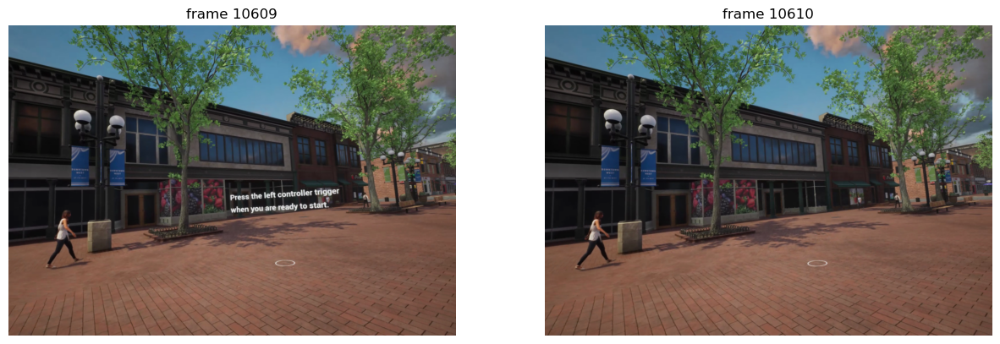

In [348]:
# find the needed frames 
print("FOR PERSON", pid, 'in VIDEO=', video_path)

frames = []
for i in [10609, 10610]:
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
    ret, frame = cap.read()
    if not ret:
        continue
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    frames.append((int(i), rgb))

fig, axs = plt.subplots(1, len(frames), figsize=(15, 5))
for ax, (i, fr) in zip(axs, frames):
    ax.imshow(fr)
    ax.set_title(f'frame {i}')
    ax.axis('off')
plt.show()

In [349]:
# check visually 
start = 294.868267
sid = 1
start_s1, end_s1 = get_start_end_in_first_valid_trial(pid=pid, sid=str(sid))
print(start_s1, end_s1)

start_time = start
end_time = start + (end_s1 - start_s1)
output_path = f"../data/videodata/testPS.mp4"

command = [
    "ffmpeg",
    "-y",
    "-i", f'../data/videodata/videoraw/{filename}.mp4',
    "-ss", str(start_time), # 
    "-to", str(end_time), # 626967, 654767, 682567
    # "-avoid_negative_ts", "1",
    output_path
]

subprocess.run(command, stdout=subprocess.DEVNULL, stderr=subprocess.STDOUT)
print(f"Clipped frames {start_time}–{end_time} saved to {output_path}")

['../data/vrdata/combined/P30_2025111151424898.csv']
541.022076 554.427977
Clipped frames 294.868267–308.2741680000001 saved to ../data/videodata/testPS.mp4


In [350]:
(0*60+13)*36

468

In [351]:
# Get fps and basic info
pid = 30
filename = f'P{pid}-2'

video_path = f'../data/videodata/videoraw/{filename}.mp4'
print('VIDEO=', video_path)
cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    print('Cannot open', video_path)
else:
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duration_sec = frame_count / fps if fps > 0 else None
    print(f'FPS={fps}, frames={frame_count}, duration(s)={duration_sec:.2f}')
# cap.release()

VIDEO= ../data/videodata/videoraw/P30-2.mp4
FPS=36.16806849327971, frames=1024, duration(s)=28.31


FOR PERSON 30 in VIDEO= ../data/videodata/videoraw/P30-2.mp4


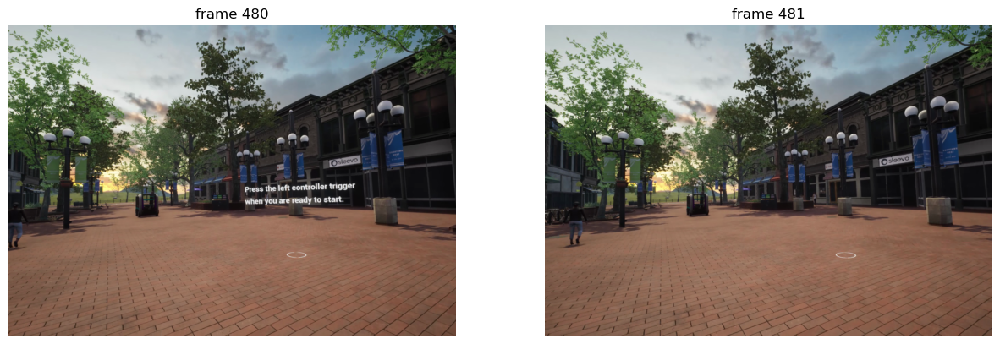

In [356]:
# find the needed frames 
print("FOR PERSON", pid, 'in VIDEO=', video_path)

frames = []
for i in [480, 481]:
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
    ret, frame = cap.read()
    if not ret:
        continue
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    frames.append((int(i), rgb))

fig, axs = plt.subplots(1, len(frames), figsize=(15, 5))
for ax, (i, fr) in zip(axs, frames):
    ax.imshow(fr)
    ax.set_title(f'frame {i}')
    ax.axis('off')
plt.show()

In [357]:
# check visually 
start = 13.375100
sid = 10
start_s1, end_s1 = get_start_end_in_first_valid_trial(pid=pid, sid=str(sid))
print(start_s1, end_s1)

start_time = start
end_time = start + (end_s1 - start_s1)
output_path = f"../data/videodata/testPS.mp4"

command = [
    "ffmpeg",
    "-y",
    "-i", f'../data/videodata/videoraw/{filename}.mp4',
    "-ss", str(start_time), # 
    "-to", str(end_time), # 626967, 654767, 682567
    # "-avoid_negative_ts", "1",
    output_path
]

subprocess.run(command, stdout=subprocess.DEVNULL, stderr=subprocess.STDOUT)
print(f"Clipped frames {start_time}–{end_time} saved to {output_path}")

['../data/vrdata/combined/P30_2025111151424898.csv']
18.899217 29.84036
Clipped frames 13.3751–24.316243 saved to ../data/videodata/testPS.mp4


## P31

In [358]:
(5*60+17)*36

11412

In [359]:
# Get fps and basic info
pid = 31
filename = f'P{pid}-1'

video_path = f'../data/videodata/videoraw/{filename}.mp4'
print('VIDEO=', video_path)
cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    print('Cannot open', video_path)
else:
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duration_sec = frame_count / fps if fps > 0 else None
    print(f'FPS={fps}, frames={frame_count}, duration(s)={duration_sec:.2f}')
# cap.release()

VIDEO= ../data/videodata/videoraw/P31-1.mp4
FPS=35.99426334529733, frames=16306, duration(s)=453.02


FOR PERSON 31 in VIDEO= ../data/videodata/videoraw/P31-1.mp4


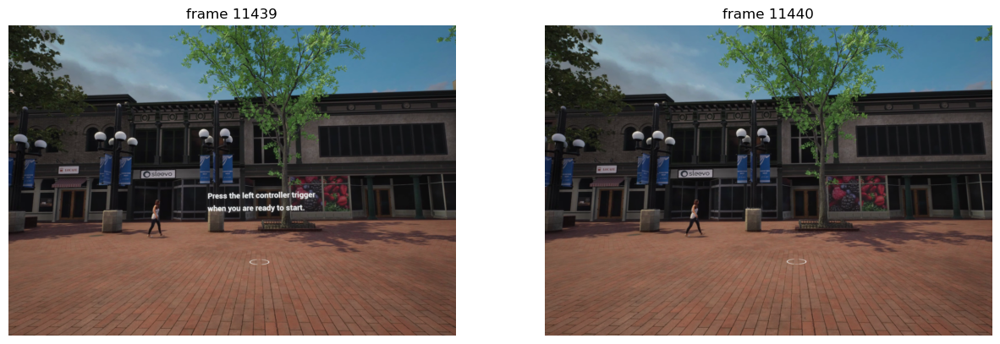

In [365]:
# find the needed frames 
print("FOR PERSON", pid, 'in VIDEO=', video_path)

frames = []
for i in range(11439, 11441):
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
    ret, frame = cap.read()
    if not ret:
        continue
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    frames.append((int(i), rgb))

fig, axs = plt.subplots(1, len(frames), figsize=(15, 5))
for ax, (i, fr) in zip(axs, frames):
    ax.imshow(fr)
    ax.set_title(f'frame {i}')
    ax.axis('off')
plt.show()

In [366]:
# check visually 
start = 317.929633
sid = 4
start_s1, end_s1 = get_start_end_in_first_valid_trial(pid=pid, sid=str(sid))
print(start_s1, end_s1)

start_time = start
end_time = start + (end_s1 - start_s1)
output_path = f"../data/videodata/testPS.mp4"

command = [
    "ffmpeg",
    "-y",
    "-i", f'../data/videodata/videoraw/{filename}.mp4',
    "-ss", str(start_time), # 
    "-to", str(end_time), # 626967, 654767, 682567
    # "-avoid_negative_ts", "1",
    output_path
]

subprocess.run(command, stdout=subprocess.DEVNULL, stderr=subprocess.STDOUT)
print(f"Clipped frames {start_time}–{end_time} saved to {output_path}")

['../data/vrdata/combined/P31_202511116142262.csv']
327.573987 332.67564
Clipped frames 317.929633–323.031286 saved to ../data/videodata/testPS.mp4


In [367]:
(0*60+15)*36

540

In [381]:
# Get fps and basic info
pid = 31
filename = f'P{pid}-2'

video_path = f'../data/videodata/videoraw/{filename}.mp4'
print('VIDEO=', video_path)
cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    print('Cannot open', video_path)
else:
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duration_sec = frame_count / fps if fps > 0 else None
    print(f'FPS={fps}, frames={frame_count}, duration(s)={duration_sec:.2f}')
# cap.release()

VIDEO= ../data/videodata/videoraw/P31-2.mp4
FPS=36.07407721222131, frames=2072, duration(s)=57.44


FOR PERSON 31 in VIDEO= ../data/videodata/videoraw/P31-2.mp4


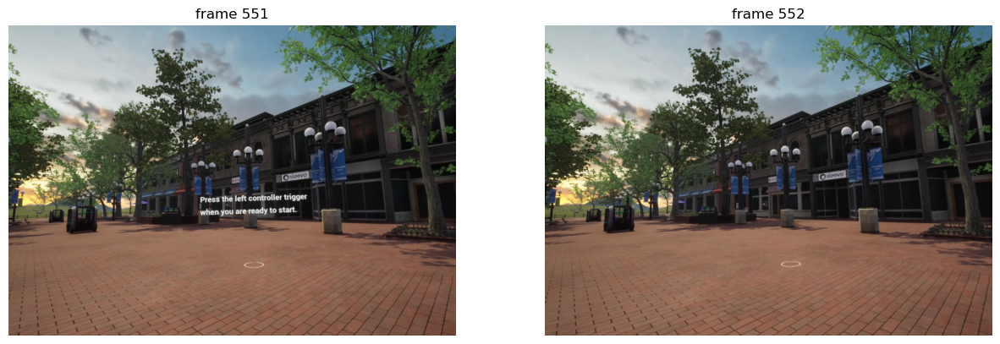

In [384]:
# find the needed frames 
print("FOR PERSON", pid, 'in VIDEO=', video_path)

frames = []
for i in range(551, 553):
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
    ret, frame = cap.read()
    if not ret:
        continue
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    frames.append((int(i), rgb))

fig, axs = plt.subplots(1, len(frames), figsize=(15, 5))
for ax, (i, fr) in zip(axs, frames):
    ax.imshow(fr)
    ax.set_title(f'frame {i}')
    ax.axis('off')
plt.show()

In [385]:
# check visually 
start = 15.348967
sid = 1
start_s1, end_s1 = get_start_end_in_first_valid_trial(pid=pid, sid=str(sid))
print(start_s1, end_s1)

start_time = start
end_time = start + (end_s1 - start_s1)
output_path = f"../data/videodata/testPS.mp4"

command = [
    "ffmpeg",
    "-y",
    "-i", f'../data/videodata/videoraw/{filename}.mp4',
    "-ss", str(start_time), # 
    "-to", str(end_time), # 626967, 654767, 682567
    # "-avoid_negative_ts", "1",
    output_path
]

subprocess.run(command, stdout=subprocess.DEVNULL, stderr=subprocess.STDOUT)
print(f"Clipped frames {start_time}–{end_time} saved to {output_path}")

['../data/vrdata/combined/P31_202511116142262.csv']
19.151339 24.448939
Clipped frames 15.348967–20.646566999999997 saved to ../data/videodata/testPS.mp4


# P33

In [409]:
(2*60+26)*36

5256

In [392]:
# Get fps and basic info
pid = 33
filename = f'P{pid}-2'

video_path = f'../data/videodata/videoraw/{filename}.mp4'
print('VIDEO=', video_path)
cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    print('Cannot open', video_path)
else:
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duration_sec = frame_count / fps if fps > 0 else None
    print(f'FPS={fps}, frames={frame_count}, duration(s)={duration_sec:.2f}')
# cap.release()

VIDEO= ../data/videodata/videoraw/P33-2.mp4
FPS=35.99588187395859, frames=14314, duration(s)=397.66


FOR PERSON 33 in VIDEO= ../data/videodata/videoraw/P33-2.mp4


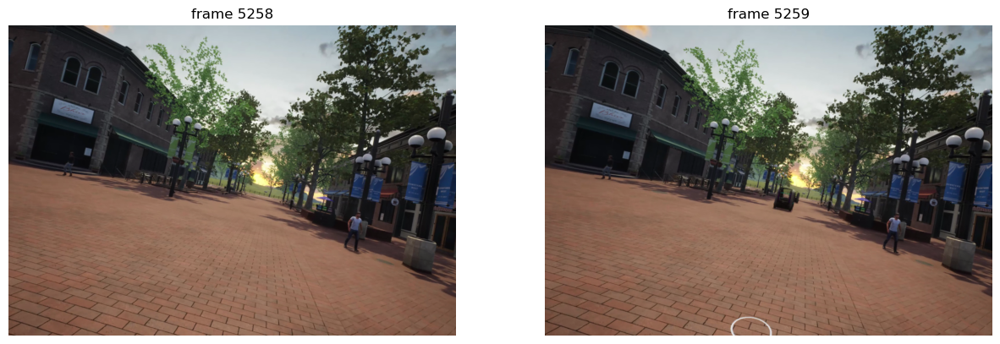

In [411]:
# find the needed frames 
print("FOR PERSON", pid, 'in VIDEO=', video_path)

frames = []
for i in range(5258, 5260):
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
    ret, frame = cap.read()
    if not ret:
        continue
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    frames.append((int(i), rgb))

fig, axs = plt.subplots(1, len(frames), figsize=(15, 5))
for ax, (i, fr) in zip(axs, frames):
    ax.imshow(fr)
    ax.set_title(f'frame {i}')
    ax.axis('off')
plt.show()

FOR PERSON 33 in VIDEO= ../data/videodata/videoraw/P33-2.mp4


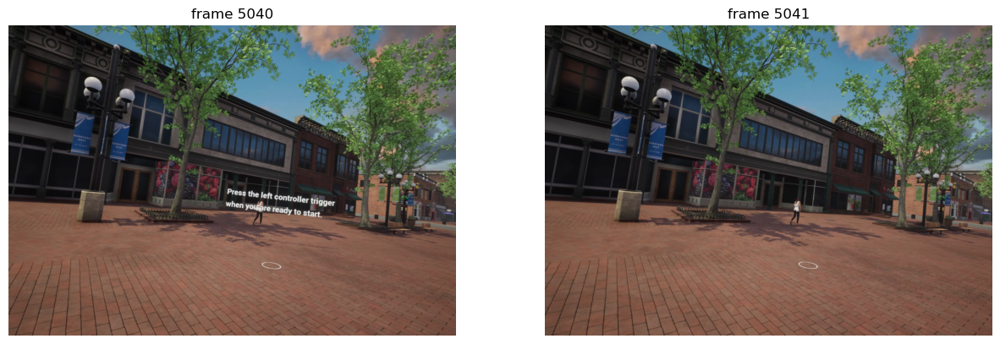

In [412]:
# find the needed frames 
print("FOR PERSON", pid, 'in VIDEO=', video_path)

frames = []
for i in range(5040, 5042):
# for i in range(5783, 5785):
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
    ret, frame = cap.read()
    if not ret:
        continue
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    frames.append((int(i), rgb))

fig, axs = plt.subplots(1, len(frames), figsize=(15, 5))
for ax, (i, fr) in zip(axs, frames):
    ax.imshow(fr)
    ax.set_title(f'frame {i}')
    ax.axis('off')
plt.show()

In [414]:
5258 - 5040

218

In [415]:
146.020267 - 139.961800

6.058466999999979

In [416]:
149.696517 - 6.058466999999979

143.63805000000002

In [421]:
# check visually 
start = 140.100733
# start = 160.749567
sid = 1
start_s1, end_s1 = get_start_end_in_first_valid_trial(pid=pid, sid=str(sid))
print(start_s1, end_s1)

start_time = start
end_time = start + (end_s1 - start_s1)
output_path = f"../data/videodata/testPS.mp4"

command = [
    "ffmpeg",
    "-y",
    "-i", f'../data/videodata/videoraw/{filename}.mp4',
    "-ss", str(start_time), # 
    "-to", str(end_time), # 626967, 654767, 682567
    # "-avoid_negative_ts", "1",
    output_path
]

subprocess.run(command, stdout=subprocess.DEVNULL, stderr=subprocess.STDOUT)
print(f"Clipped frames {start_time}–{end_time} saved to {output_path}")

['../data/vrdata/combined/P33_2025113131228931.csv']
144.139605 149.696517
Clipped frames 140.100733–145.657645 saved to ../data/videodata/testPS.mp4


## P36

In [427]:
(6*60+12)*36

13392

In [422]:
# Get fps and basic info
pid = 36
filename = f'P{pid}-1'

video_path = f'../data/videodata/videoraw/{filename}.mp4'
print('VIDEO=', video_path)
cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    print('Cannot open', video_path)
else:
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duration_sec = frame_count / fps if fps > 0 else None
    print(f'FPS={fps}, frames={frame_count}, duration(s)={duration_sec:.2f}')
# cap.release()

VIDEO= ../data/videodata/videoraw/P36-1.mp4
FPS=35.99090125941771, frames=22963, duration(s)=638.02


FOR PERSON 36 in VIDEO= ../data/videodata/videoraw/P36-1.mp4


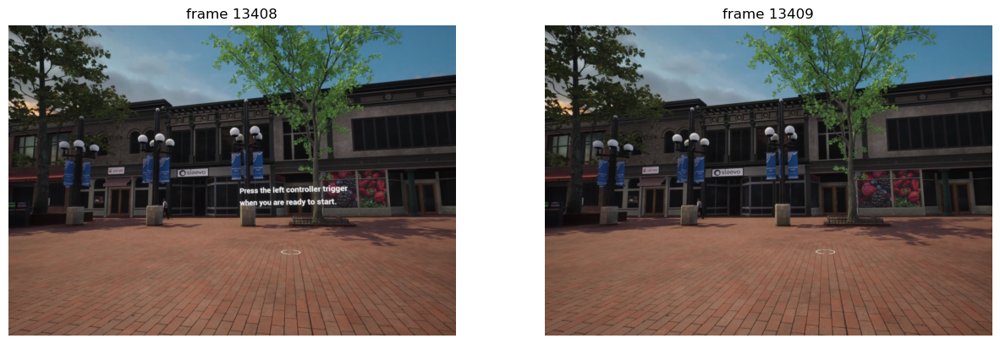

In [430]:
# find the needed frames 
print("FOR PERSON", pid, 'in VIDEO=', video_path)

frames = []
for i in range(13408, 13410):
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
    ret, frame = cap.read()
    if not ret:
        continue
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    frames.append((int(i), rgb))

fig, axs = plt.subplots(1, len(frames), figsize=(15, 5))
for ax, (i, fr) in zip(axs, frames):
    ax.imshow(fr)
    ax.set_title(f'frame {i}')
    ax.axis('off')
plt.show()

In [431]:
# check visually 
start = 372.657400
sid = 2
start_s1, end_s1 = get_start_end_in_first_valid_trial(pid=pid, sid=str(sid))
print(start_s1, end_s1)

start_time = start
end_time = start + (end_s1 - start_s1)
output_path = f"../data/videodata/testPS.mp4"

command = [
    "ffmpeg",
    "-y",
    "-i", f'../data/videodata/videoraw/{filename}.mp4',
    "-ss", str(start_time), # 
    "-to", str(end_time), # 626967, 654767, 682567
    # "-avoid_negative_ts", "1",
    output_path
]

subprocess.run(command, stdout=subprocess.DEVNULL, stderr=subprocess.STDOUT)
print(f"Clipped frames {start_time}–{end_time} saved to {output_path}")

['../data/vrdata/combined/P36_20251131675773.csv']
542.346054 559.589664
Clipped frames 372.6574–389.90101 saved to ../data/videodata/testPS.mp4


In [432]:
(0*60+18)*36

648

In [433]:
# Get fps and basic info
pid = 36
filename = f'P{pid}-2'

video_path = f'../data/videodata/videoraw/{filename}.mp4'
print('VIDEO=', video_path)
cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    print('Cannot open', video_path)
else:
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duration_sec = frame_count / fps if fps > 0 else None
    print(f'FPS={fps}, frames={frame_count}, duration(s)={duration_sec:.2f}')
# cap.release()

VIDEO= ../data/videodata/videoraw/P36-2.mp4
FPS=36.13516410418779, frames=1244, duration(s)=34.43


FOR PERSON 36 in VIDEO= ../data/videodata/videoraw/P36-2.mp4


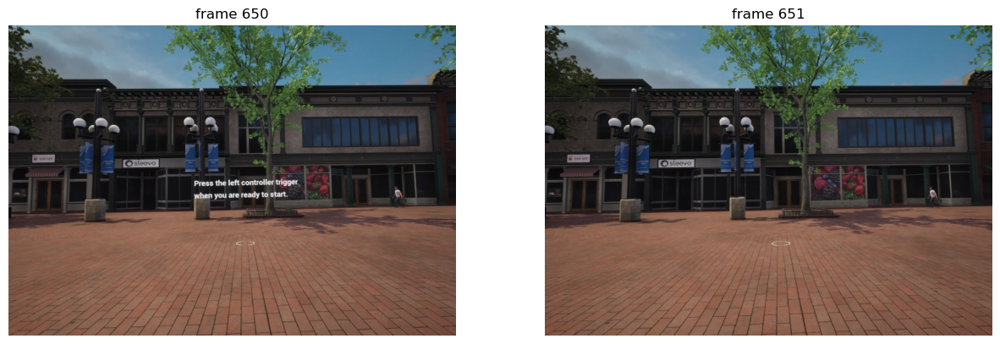

In [435]:
# find the needed frames 
print("FOR PERSON", pid, 'in VIDEO=', video_path)

frames = []
for i in range(650, 652):
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
    ret, frame = cap.read()
    if not ret:
        continue
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    frames.append((int(i), rgb))

fig, axs = plt.subplots(1, len(frames), figsize=(15, 5))
for ax, (i, fr) in zip(axs, frames):
    ax.imshow(fr)
    ax.set_title(f'frame {i}')
    ax.axis('off')
plt.show()

In [436]:
# check visually 
start = 18.097600
sid = 1
start_s1, end_s1 = get_start_end_in_first_valid_trial(pid=pid, sid=str(sid))
print(start_s1, end_s1)

start_time = start
end_time = start + (end_s1 - start_s1)
output_path = f"../data/videodata/testPS.mp4"

command = [
    "ffmpeg",
    "-y",
    "-i", f'../data/videodata/videoraw/{filename}.mp4',
    "-ss", str(start_time), # 
    "-to", str(end_time), # 626967, 654767, 682567
    # "-avoid_negative_ts", "1",
    output_path
]

subprocess.run(command, stdout=subprocess.DEVNULL, stderr=subprocess.STDOUT)
print(f"Clipped frames {start_time}–{end_time} saved to {output_path}")

['../data/vrdata/combined/P36_20251131675773.csv']
22.396706 35.642546
Clipped frames 18.0976–31.343440000000005 saved to ../data/videodata/testPS.mp4


In [437]:
(0*60+8)*36

288

In [439]:
# Get fps and basic info
pid = 36
filename = f'P{pid}-3'

video_path = f'../data/videodata/videoraw/{filename}.mp4'
print('VIDEO=', video_path)
cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    print('Cannot open', video_path)
else:
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duration_sec = frame_count / fps if fps > 0 else None
    print(f'FPS={fps}, frames={frame_count}, duration(s)={duration_sec:.2f}')
# cap.release()

VIDEO= ../data/videodata/videoraw/P36-3.mp4
FPS=36.16680932268792, frames=1031, duration(s)=28.51


FOR PERSON 36 in VIDEO= ../data/videodata/videoraw/P36-3.mp4


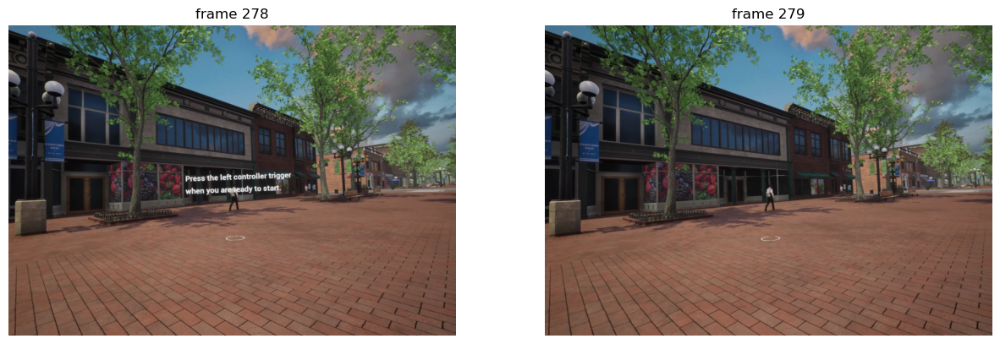

In [442]:
# find the needed frames 
print("FOR PERSON", pid, 'in VIDEO=', video_path)

frames = []
for i in range(278, 280):
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
    ret, frame = cap.read()
    if not ret:
        continue
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    frames.append((int(i), rgb))

fig, axs = plt.subplots(1, len(frames), figsize=(15, 5))
for ax, (i, fr) in zip(axs, frames):
    ax.imshow(fr)
    ax.set_title(f'frame {i}')
    ax.axis('off')
plt.show()

In [443]:
# check visually 
start = 7.752900
sid = 11
start_s1, end_s1 = get_start_end_in_first_valid_trial(pid=pid, sid=str(sid))
print(start_s1, end_s1)

start_time = start
end_time = start + (end_s1 - start_s1)
output_path = f"../data/videodata/testPS.mp4"

command = [
    "ffmpeg",
    "-y",
    "-i", f'../data/videodata/videoraw/{filename}.mp4',
    "-ss", str(start_time), # 
    "-to", str(end_time), # 626967, 654767, 682567
    # "-avoid_negative_ts", "1",
    output_path
]

subprocess.run(command, stdout=subprocess.DEVNULL, stderr=subprocess.STDOUT)
print(f"Clipped frames {start_time}–{end_time} saved to {output_path}")

['../data/vrdata/combined/P36_20251131675773.csv']
14.615188 32.870467
Clipped frames 7.7529–26.008179 saved to ../data/videodata/testPS.mp4


In [454]:
def get_start_in_video_metadata(filename, row, plus=4):
    df = pd.read_csv(f'../data/videodata/video_metadata/{filename}.csv', header=None)
    start = df.iloc[row+plus, 5]
    return start

## P37

In [445]:
(5*60+38)*36

12168

In [444]:
# Get fps and basic info
pid = 37
filename = f'P{pid}-1'

video_path = f'../data/videodata/videoraw/{filename}.mp4'
print('VIDEO=', video_path)
cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    print('Cannot open', video_path)
else:
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duration_sec = frame_count / fps if fps > 0 else None
    print(f'FPS={fps}, frames={frame_count}, duration(s)={duration_sec:.2f}')
# cap.release()

VIDEO= ../data/videodata/videoraw/P37-1.mp4
FPS=35.99153688772188, frames=21308, duration(s)=592.03


FOR PERSON 37 in VIDEO= ../data/videodata/videoraw/P37-1.mp4


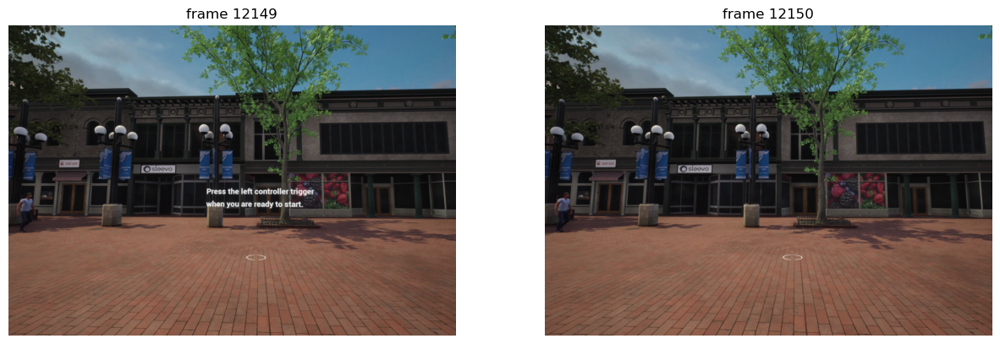

In [450]:
# find the needed frames 
print("FOR PERSON", pid, 'in VIDEO=', video_path)

frames = []
for i in range(12149, 12151):
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
    ret, frame = cap.read()
    if not ret:
        continue
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    frames.append((int(i), rgb))

fig, axs = plt.subplots(1, len(frames), figsize=(15, 5))
for ax, (i, fr) in zip(axs, frames):
    ax.imshow(fr)
    ax.set_title(f'frame {i}')
    ax.axis('off')
plt.show()

In [ ]:
# check visually 
start = get_start_in_video_metadata(filename, row=frames[0][0], plus=4)
sid = 1
start_s1, end_s1 = get_start_end_in_first_valid_trial(pid=pid, sid=str(sid))
print(start, start_s1, end_s1)

start_time = start
end_time = start + (end_s1 - start_s1)
output_path = f"../data/videodata/testPS.mp4"

command = [
    "ffmpeg",
    "-y",
    "-i", f'../data/videodata/videoraw/{filename}.mp4',
    "-ss", str(start_time), # 
    "-to", str(end_time), # 626967, 654767, 682567
    # "-avoid_negative_ts", "1",
    output_path
]

subprocess.run(command, stdout=subprocess.DEVNULL, stderr=subprocess.STDOUT)
print(f"Clipped frames {start_time}–{end_time} saved to {output_path}")

['../data/vrdata/combined/P37_202511317103643.csv']
436.382054 445.966443
Clipped frames 337.6622–347.24658900000003 saved to ../data/videodata/testPS.mp4


In [457]:
(0*60+16)*36

576

In [469]:
# Get fps and basic info
pid = 37
filename = f'P{pid}-2'

video_path = f'../data/videodata/videoraw/{filename}.mp4'
print('VIDEO=', video_path)
cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    print('Cannot open', video_path)
else:
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duration_sec = frame_count / fps if fps > 0 else None
    print(f'FPS={fps}, frames={frame_count}, duration(s)={duration_sec:.2f}')
# cap.release()

VIDEO= ../data/videodata/videoraw/P37-2.mp4
FPS=36.19124550588952, frames=911, duration(s)=25.17


FOR PERSON 37 in VIDEO= ../data/videodata/videoraw/P37-2.mp4


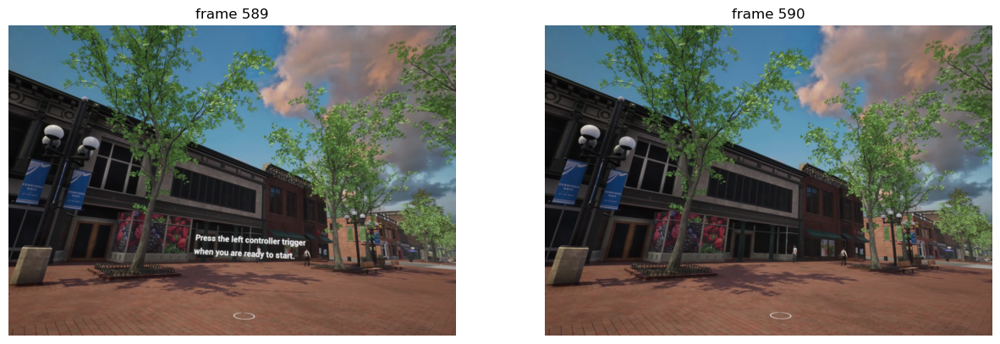

In [473]:
# find the needed frames 
print("FOR PERSON", pid, 'in VIDEO=', video_path)

frames = []
for i in range(589, 591):
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
    ret, frame = cap.read()
    if not ret:
        continue
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    frames.append((int(i), rgb))

fig, axs = plt.subplots(1, len(frames), figsize=(15, 5))
for ax, (i, fr) in zip(axs, frames):
    ax.imshow(fr)
    ax.set_title(f'frame {i}')
    ax.axis('off')
plt.show()

In [ ]:
# check visually 
start = get_start_in_video_metadata(filename, row=frames[0][0], plus=4)
sid = 2
start_s1, end_s1 = get_start_end_in_first_valid_trial(pid=pid, sid=str(sid))
print(start, start_s1, end_s1)

start_time = start
end_time = start + (end_s1 - start_s1)
output_path = f"../data/videodata/testPS.mp4"

command = [
    "ffmpeg",
    "-y",
    "-i", f'../data/videodata/videoraw/{filename}.mp4',
    "-ss", str(start_time), # 
    "-to", str(end_time), # 626967, 654767, 682567
    # "-avoid_negative_ts", "1",
    output_path
]

subprocess.run(command, stdout=subprocess.DEVNULL, stderr=subprocess.STDOUT)
print(f"Clipped frames {start_time}–{end_time} saved to {output_path}")

['../data/vrdata/combined/P37_202511317103643.csv']
21.191091 26.681702
Clipped frames 16.396567–21.887178000000002 saved to ../data/videodata/testPS.mp4


In [ ]:
(0*60+16)*36

576

In [ ]:
# Get fps and basic info
pid = 37
filename = f'P{pid}-3'

video_path = f'../data/videodata/videoraw/{filename}.mp4'
print('VIDEO=', video_path)
cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    print('Cannot open', video_path)
else:
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duration_sec = frame_count / fps if fps > 0 else None
    print(f'FPS={fps}, frames={frame_count}, duration(s)={duration_sec:.2f}')
# cap.release()

2

FOR PERSON 37 in VIDEO= ../data/videodata/videoraw/P37-3.mp4


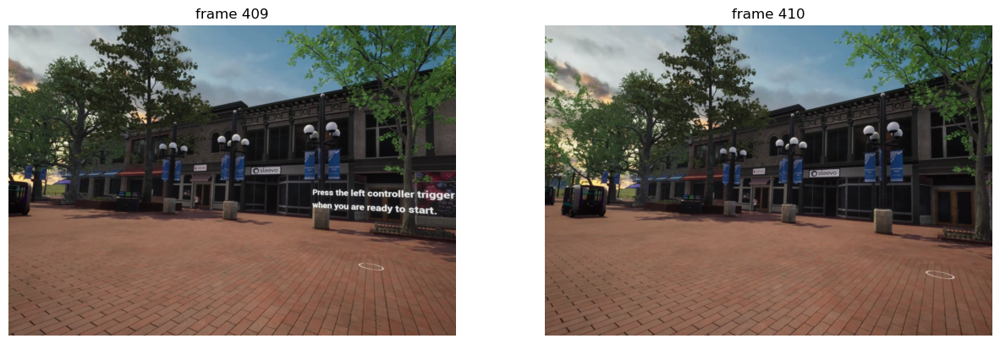

In [488]:
# find the needed frames 
print("FOR PERSON", pid, 'in VIDEO=', video_path)

frames = []
first_valid = (0*60+11)*36
# for i in range(first_valid, first_valid+36):
for i in range(409, 409+2):
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
    ret, frame = cap.read()
    if not ret:
        continue
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    frames.append((int(i), rgb))

n_row = int(np.ceil(len(frames)/10))
if n_row > 1: 
    n_col = 10
    col_size = 1.5*n_row 
else:    
    n_col = len(frames)
    col_size = 5 

fig, axs = plt.subplots(n_row, n_col, figsize=(15, col_size))
axes = axs.flatten()

# first turn everything off
for ax in axes:
    ax.axis('off')

for ax, (i, fr) in zip(axes, frames):
    ax.imshow(fr)
    ax.set_title(f'frame {i}')
    ax.axis('off')
plt.show()

In [ ]:
# check visually 
start = get_start_in_video_metadata(filename, row=frames[0][0], plus=4)
sid = 8
start_s1, end_s1 = get_start_end_in_first_valid_trial(pid=pid, sid=str(sid))
print(start, start_s1, end_s1)

start_time = start
end_time = start + (end_s1 - start_s1)
output_path = f"../testPS.mp4"

command = [
    "ffmpeg",
    "-y",
    "-i", f'../data/videodata/videoraw/{filename}.mp4',
    "-ss", str(start_time), # 
    "-to", str(end_time), # 626967, 654767, 682567
    # "-avoid_negative_ts", "1",
    output_path
]

subprocess.run(command, stdout=subprocess.DEVNULL, stderr=subprocess.STDOUT)
print(f"Clipped frames {start_time}–{end_time} saved to {output_path}")

['../data/vrdata/combined/P37_202511317103643.csv']
11.3998 15.915699 30.410431
Clipped frames 11.3998–25.894531999999998 saved to ../data/videodata/testPS.mp4


In [490]:
# Get fps and basic info
pid = 37
filename = f'P{pid}-4'
sid = 12

video_path = f'../data/videodata/videoraw/{filename}.mp4'
print('VIDEO=', video_path)
cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    print('Cannot open', video_path)
else:
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duration_sec = frame_count / fps if fps > 0 else None
    print(f'FPS={fps}, frames={frame_count}, duration(s)={duration_sec:.2f}')
# cap.release()

VIDEO= ../data/videodata/videoraw/P37-4.mp4
FPS=36.15810650043889, frames=1082, duration(s)=29.92


FOR PERSON 37 in VIDEO= ../data/videodata/videoraw/P37-4.mp4


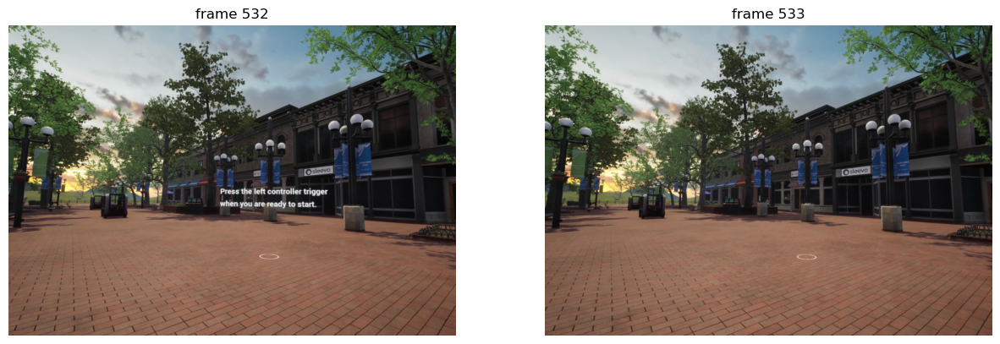

In [493]:
# find the needed frames 
print("FOR PERSON", pid, 'in VIDEO=', video_path)

frames = []
first_valid = (0*60+14)*36
# for i in range(first_valid, first_valid+36):
first_valid = 532
for i in range(first_valid, first_valid+2):
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
    ret, frame = cap.read()
    if not ret:
        continue
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    frames.append((int(i), rgb))

n_row = int(np.ceil(len(frames)/10))
if n_row > 1: 
    n_col = 10
    col_size = 1.5*n_row 
else:    
    n_col = len(frames)
    col_size = 5 

fig, axs = plt.subplots(n_row, n_col, figsize=(15, col_size))
axes = axs.flatten()

# first turn everything off
for ax in axes:
    ax.axis('off')

for ax, (i, fr) in zip(axes, frames):
    ax.imshow(fr)
    ax.set_title(f'frame {i}')
    ax.axis('off')
plt.show()

In [494]:
# check visually 
start = get_start_in_video_metadata(filename, row=frames[0][0], plus=4)
start_s1, end_s1 = get_start_end_in_first_valid_trial(pid=pid, sid=str(sid))
print(start, start_s1, end_s1)

start_time = start
end_time = start + (end_s1 - start_s1)
output_path = f"../testPS.mp4"

command = [
    "ffmpeg",
    "-y",
    "-i", f'../data/videodata/videoraw/{filename}.mp4',
    "-ss", str(start_time), # 
    "-to", str(end_time), # 626967, 654767, 682567
    # "-avoid_negative_ts", "1",
    output_path
]

subprocess.run(command, stdout=subprocess.DEVNULL, stderr=subprocess.STDOUT)
print(f"Clipped frames {start_time}–{end_time} saved to {output_path}")

['../data/vrdata/combined/P37_202511317103643.csv']
14.817767 19.306676 31.647761
Clipped frames 14.817767–27.158852 saved to ../testPS.mp4


## P38

In [498]:
# Get fps and basic info
pid = 38
filename = f'P{pid}-1'
sid = 1

video_path = f'../data/videodata/videoraw/{filename}.mp4'
print('VIDEO=', video_path)
cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    print('Cannot open', video_path)
else:
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duration_sec = frame_count / fps if fps > 0 else None
    print(f'FPS={fps}, frames={frame_count}, duration(s)={duration_sec:.2f}')
# cap.release()

VIDEO= ../data/videodata/videoraw/P38-1.mp4
FPS=35.990158649069066, frames=25235, duration(s)=701.16


FOR PERSON 38 in VIDEO= ../data/videodata/videoraw/P38-1.mp4


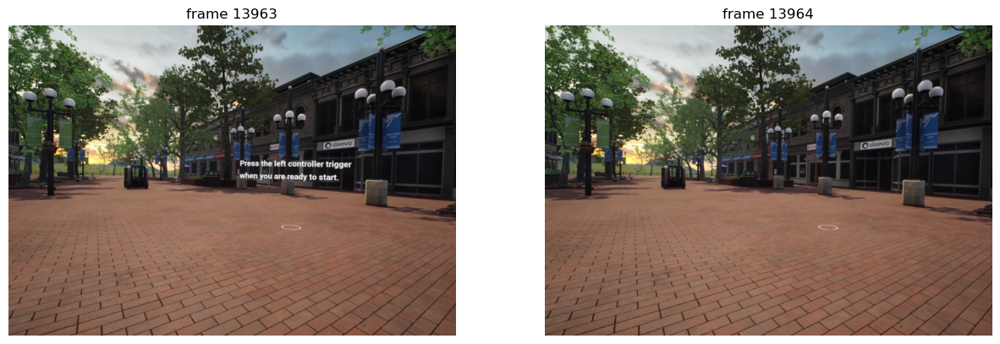

In [502]:
# find the needed frames 
print("FOR PERSON", pid, 'in VIDEO=', video_path)

frames = []
first_valid = (6*60+27)*36
# for i in range(first_valid, first_valid+36):
first_valid = 13963
for i in range(first_valid, first_valid+2):
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
    ret, frame = cap.read()
    if not ret:
        continue
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    frames.append((int(i), rgb))

n_row = int(np.ceil(len(frames)/10))
if n_row > 1: 
    n_col = 10
    col_size = 1.5*n_row 
else:    
    n_col = len(frames)
    col_size = 5 

fig, axs = plt.subplots(n_row, n_col, figsize=(15, col_size))
axes = axs.flatten()

# first turn everything off
for ax in axes:
    ax.axis('off')

for ax, (i, fr) in zip(axes, frames):
    ax.imshow(fr)
    ax.set_title(f'frame {i}')
    ax.axis('off')
plt.show()

In [503]:
# check visually 
start = get_start_in_video_metadata(filename, row=frames[0][0], plus=4)
start_s1, end_s1 = get_start_end_in_first_valid_trial(pid=pid, sid=str(sid))
print(start, start_s1, end_s1)

start_time = start
end_time = start + (end_s1 - start_s1)
output_path = f"../data/videodata/testPS.mp4"

command = [
    "ffmpeg",
    "-y",
    "-i", f'../data/videodata/videoraw/{filename}.mp4',
    "-ss", str(start_time), # 
    "-to", str(end_time), # 626967, 654767, 682567
    # "-avoid_negative_ts", "1",
    output_path
]

subprocess.run(command, stdout=subprocess.DEVNULL, stderr=subprocess.STDOUT)
print(f"Clipped frames {start_time}–{end_time} saved to {output_path}")

['../data/vrdata/combined/P38_2025114101220373.csv']
388.081767 569.17371 582.172414
Clipped frames 388.081767–401.080471 saved to ../data/videodata/testPS.mp4


In [504]:
# Get fps and basic info
pid = 38
filename = f'P{pid}-2'
sid = 11

video_path = f'../data/videodata/videoraw/{filename}.mp4'
print('VIDEO=', video_path)
cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    print('Cannot open', video_path)
else:
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duration_sec = frame_count / fps if fps > 0 else None
    print(f'FPS={fps}, frames={frame_count}, duration(s)={duration_sec:.2f}')
# cap.release()

VIDEO= ../data/videodata/videoraw/P38-2.mp4
FPS=36.078420886956714, frames=1979, duration(s)=54.85


FOR PERSON 38 in VIDEO= ../data/videodata/videoraw/P38-2.mp4


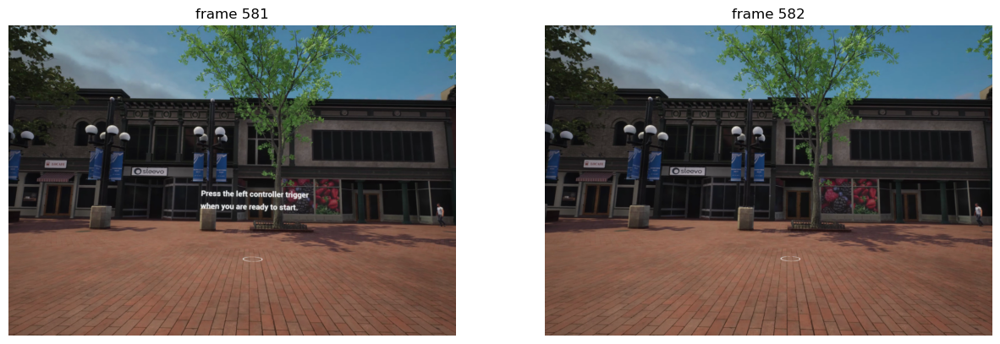

In [506]:
# find the needed frames 
print("FOR PERSON", pid, 'in VIDEO=', video_path)

frames = []
first_valid = (0*60+16)*36
# for i in range(first_valid, first_valid+36):
first_valid = 581
for i in range(first_valid, first_valid+2):
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
    ret, frame = cap.read()
    if not ret:
        continue
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    frames.append((int(i), rgb))

n_row = int(np.ceil(len(frames)/10))
if n_row > 1: 
    n_col = 10
    col_size = 1.5*n_row 
else:    
    n_col = len(frames)
    col_size = 5 

fig, axs = plt.subplots(n_row, n_col, figsize=(15, col_size))
axes = axs.flatten()

# first turn everything off
for ax in axes:
    ax.axis('off')

for ax, (i, fr) in zip(axes, frames):
    ax.imshow(fr)
    ax.set_title(f'frame {i}')
    ax.axis('off')
plt.show()

In [507]:
# check visually 
start = get_start_in_video_metadata(filename, row=frames[0][0], plus=4)
start_s1, end_s1 = get_start_end_in_first_valid_trial(pid=pid, sid=str(sid))
print(start, start_s1, end_s1)

start_time = start
end_time = start + (end_s1 - start_s1)
output_path = f"../data/videodata/testPS.mp4"

command = [
    "ffmpeg",
    "-y",
    "-i", f'../data/videodata/videoraw/{filename}.mp4',
    "-ss", str(start_time), # 
    "-to", str(end_time), # 626967, 654767, 682567
    # "-avoid_negative_ts", "1",
    output_path
]

subprocess.run(command, stdout=subprocess.DEVNULL, stderr=subprocess.STDOUT)
print(f"Clipped frames {start_time}–{end_time} saved to {output_path}")

['../data/vrdata/combined/P38_2025114101220373.csv']
16.1754 31.579486 42.527495
Clipped frames 16.1754–27.123409000000002 saved to ../data/videodata/testPS.mp4


## P39

In [512]:
# Get fps and basic info
pid = 39
filename = f'P{pid}-1'
sid = 2

video_path = f'../data/videodata/videoraw/{filename}.mp4'
print('VIDEO=', video_path)
cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    print('Cannot open', video_path)
else:
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duration_sec = frame_count / fps if fps > 0 else None
    print(f'FPS={fps}, frames={frame_count}, duration(s)={duration_sec:.2f}')
# cap.release()

VIDEO= ../data/videodata/videoraw/P39-1.mp4
FPS=35.992637438127176, frames=18958, duration(s)=526.72


FOR PERSON 39 in VIDEO= ../data/videodata/videoraw/P39-1.mp4


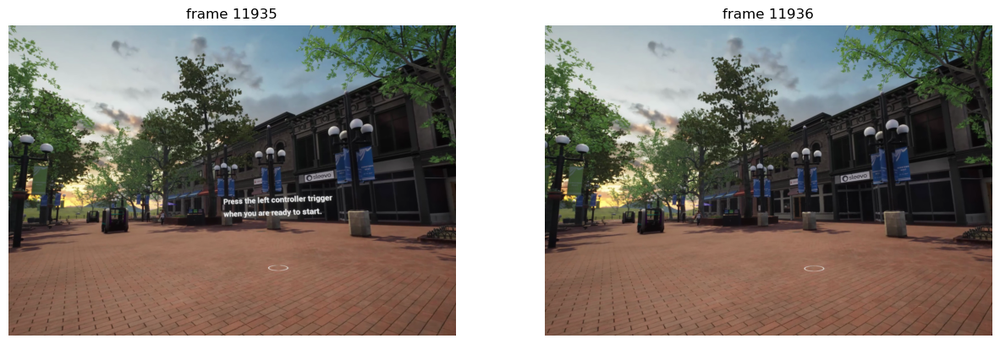

In [513]:
# find the needed frames 
print("FOR PERSON", pid, 'in VIDEO=', video_path)

frames = []
first_valid = (5*60+31)*36
# for i in range(first_valid, first_valid+36):
first_valid = 11935
for i in range(first_valid, first_valid+2):
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
    ret, frame = cap.read()
    if not ret:
        continue
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    frames.append((int(i), rgb))

n_row = int(np.ceil(len(frames)/10))
if n_row > 1: 
    n_col = 10
    col_size = 1.5*n_row 
else:    
    n_col = len(frames)
    col_size = 5 

fig, axs = plt.subplots(n_row, n_col, figsize=(15, col_size))
axes = axs.flatten()

# first turn everything off
for ax in axes:
    ax.axis('off')

for ax, (i, fr) in zip(axes, frames):
    ax.imshow(fr)
    ax.set_title(f'frame {i}')
    ax.axis('off')
plt.show()

In [514]:
# check visually 
start = get_start_in_video_metadata(filename, row=frames[0][0], plus=4)
start_s1, end_s1 = get_start_end_in_first_valid_trial(pid=pid, sid=str(sid))
print(start, start_s1, end_s1)

start_time = start
end_time = start + (end_s1 - start_s1)
output_path = f"../data/videodata/testPS.mp4"

command = [
    "ffmpeg",
    "-y",
    "-i", f'../data/videodata/videoraw/{filename}.mp4',
    "-ss", str(start_time), # 
    "-to", str(end_time), # 626967, 654767, 682567
    # "-avoid_negative_ts", "1",
    output_path
]

subprocess.run(command, stdout=subprocess.DEVNULL, stderr=subprocess.STDOUT)
print(f"Clipped frames {start_time}–{end_time} saved to {output_path}")

['../data/vrdata/combined/P39_20251141112424.csv']
331.723033 422.582671 429.120475
Clipped frames 331.723033–338.260837 saved to ../data/videodata/testPS.mp4


In [515]:
# Get fps and basic info
pid = 39
filename = f'P{pid}-2'
sid = 1

video_path = f'../data/videodata/videoraw/{filename}.mp4'
print('VIDEO=', video_path)
cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    print('Cannot open', video_path)
else:
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duration_sec = frame_count / fps if fps > 0 else None
    print(f'FPS={fps}, frames={frame_count}, duration(s)={duration_sec:.2f}')
# cap.release()

VIDEO= ../data/videodata/videoraw/P39-2.mp4
FPS=36.2346082902864, frames=755, duration(s)=20.84


FOR PERSON 39 in VIDEO= ../data/videodata/videoraw/P39-2.mp4


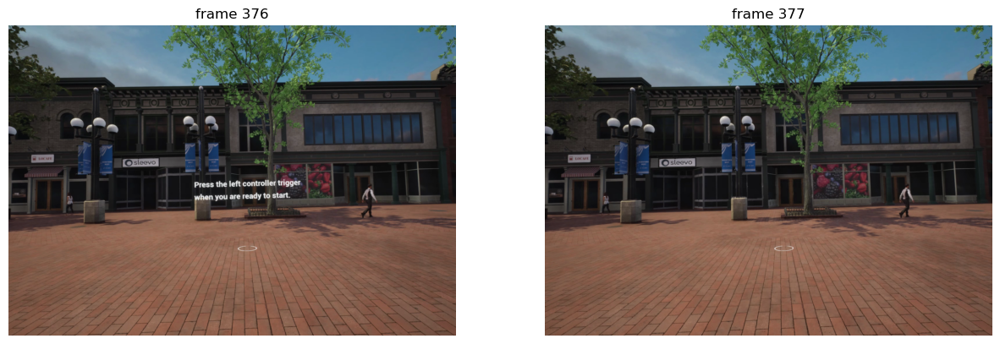

In [517]:
# find the needed frames 
print("FOR PERSON", pid, 'in VIDEO=', video_path)

frames = []
first_valid = (0*60+10)*36
# for i in range(first_valid, first_valid+36):
first_valid = 376
for i in range(first_valid, first_valid+2):
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
    ret, frame = cap.read()
    if not ret:
        continue
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    frames.append((int(i), rgb))

n_row = int(np.ceil(len(frames)/10))
if n_row > 1: 
    n_col = 10
    col_size = 1.5*n_row 
else:    
    n_col = len(frames)
    col_size = 5 

fig, axs = plt.subplots(n_row, n_col, figsize=(15, col_size))
axes = axs.flatten()

# first turn everything off
for ax in axes:
    ax.axis('off')

for ax, (i, fr) in zip(axes, frames):
    ax.imshow(fr)
    ax.set_title(f'frame {i}')
    ax.axis('off')
plt.show()

In [518]:
# check visually 
start = get_start_in_video_metadata(filename, row=frames[0][0], plus=4)
start_s1, end_s1 = get_start_end_in_first_valid_trial(pid=pid, sid=str(sid))
print(start, start_s1, end_s1)

start_time = start
end_time = start + (end_s1 - start_s1)
output_path = f"../data/videodata/testPS.mp4"

command = [
    "ffmpeg",
    "-y",
    "-i", f'../data/videodata/videoraw/{filename}.mp4',
    "-ss", str(start_time), # 
    "-to", str(end_time), # 626967, 654767, 682567
    # "-avoid_negative_ts", "1",
    output_path
]

subprocess.run(command, stdout=subprocess.DEVNULL, stderr=subprocess.STDOUT)
print(f"Clipped frames {start_time}–{end_time} saved to {output_path}")

['../data/vrdata/combined/P39_20251141112424.csv']
10.476433 14.324173 20.716997
Clipped frames 10.476433–16.869256999999998 saved to ../data/videodata/testPS.mp4


In [519]:
# Get fps and basic info
pid = 39
filename = f'P{pid}-3'
sid = 4

video_path = f'../data/videodata/videoraw/{filename}.mp4'
print('VIDEO=', video_path)
cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    print('Cannot open', video_path)
else:
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duration_sec = frame_count / fps if fps > 0 else None
    print(f'FPS={fps}, frames={frame_count}, duration(s)={duration_sec:.2f}')
# cap.release()

VIDEO= ../data/videodata/videoraw/P39-3.mp4
FPS=36.17872063979211, frames=969, duration(s)=26.78


FOR PERSON 39 in VIDEO= ../data/videodata/videoraw/P39-3.mp4


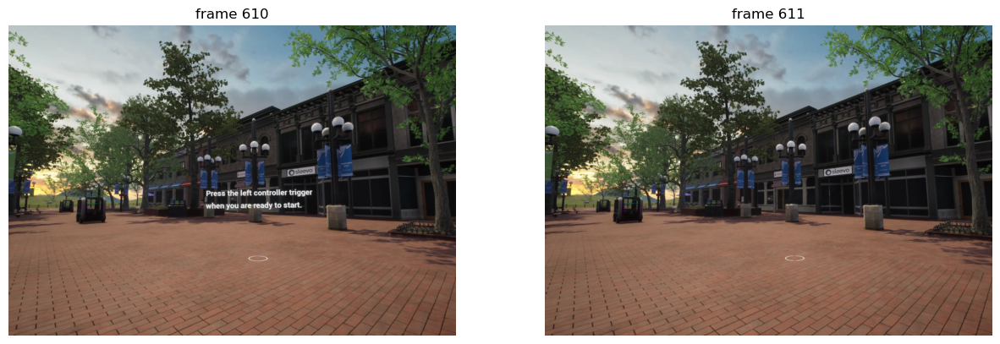

In [522]:
# find the needed frames 
print("FOR PERSON", pid, 'in VIDEO=', video_path)

frames = []
first_valid = (0*60+16)*36
# for i in range(first_valid, first_valid+36):
first_valid = 610
for i in range(first_valid, first_valid+2):
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
    ret, frame = cap.read()
    if not ret:
        continue
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    frames.append((int(i), rgb))

n_row = int(np.ceil(len(frames)/10))
if n_row > 1: 
    n_col = 10
    col_size = 1.5*n_row 
else:    
    n_col = len(frames)
    col_size = 5 

fig, axs = plt.subplots(n_row, n_col, figsize=(15, col_size))
axes = axs.flatten()

# first turn everything off
for ax in axes:
    ax.axis('off')

for ax, (i, fr) in zip(axes, frames):
    ax.imshow(fr)
    ax.set_title(f'frame {i}')
    ax.axis('off')
plt.show()

In [523]:
# check visually 
start = get_start_in_video_metadata(filename, row=frames[0][0], plus=4)
start_s1, end_s1 = get_start_end_in_first_valid_trial(pid=pid, sid=str(sid))
print(start, start_s1, end_s1)

start_time = start
end_time = start + (end_s1 - start_s1)
output_path = f"../data/videodata/testPS.mp4"

command = [
    "ffmpeg",
    "-y",
    "-i", f'../data/videodata/videoraw/{filename}.mp4',
    "-ss", str(start_time), # 
    "-to", str(end_time), # 626967, 654767, 682567
    # "-avoid_negative_ts", "1",
    output_path
]

subprocess.run(command, stdout=subprocess.DEVNULL, stderr=subprocess.STDOUT)
print(f"Clipped frames {start_time}–{end_time} saved to {output_path}")

['../data/vrdata/combined/P39_20251141112424.csv']
16.985067 21.449737 27.53664
Clipped frames 16.985067–23.07197 saved to ../data/videodata/testPS.mp4


In [525]:
# Get fps and basic info
pid = 39
filename = f'P{pid}-4_2'
sid = 11

video_path = f'../data/videodata/videoraw/{filename}.mp4'
print('VIDEO=', video_path)
cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    print('Cannot open', video_path)
else:
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duration_sec = frame_count / fps if fps > 0 else None
    print(f'FPS={fps}, frames={frame_count}, duration(s)={duration_sec:.2f}')
# cap.release()

VIDEO= ../data/videodata/videoraw/P39-4_2.mp4
FPS=36.214794856526325, frames=819, duration(s)=22.62


FOR PERSON 39 in VIDEO= ../data/videodata/videoraw/P39-4_2.mp4


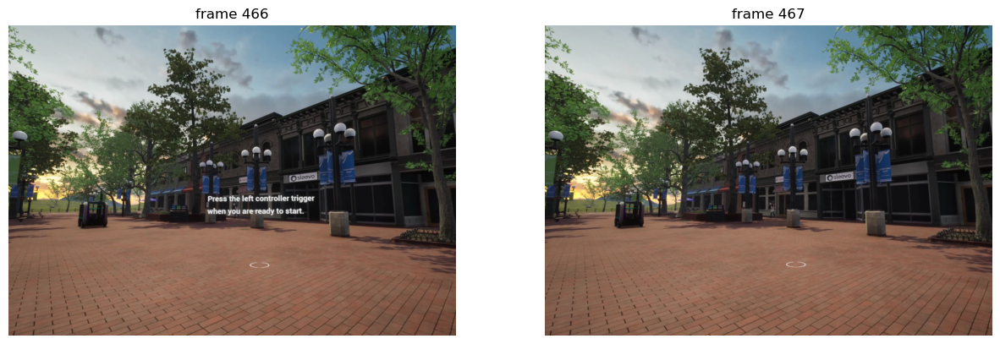

In [529]:
# find the needed frames 
print("FOR PERSON", pid, 'in VIDEO=', video_path)

frames = []
first_valid = (0*60+12)*36
# for i in range(first_valid, first_valid+36):
first_valid = 466
for i in range(first_valid, first_valid+2):
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
    ret, frame = cap.read()
    if not ret:
        continue
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    frames.append((int(i), rgb))

n_row = int(np.ceil(len(frames)/10))
if n_row > 1: 
    n_col = 10
    col_size = 1.5*n_row 
else:    
    n_col = len(frames)
    col_size = 5 

fig, axs = plt.subplots(n_row, n_col, figsize=(15, col_size))
axes = axs.flatten()

# first turn everything off
for ax in axes:
    ax.axis('off')

for ax, (i, fr) in zip(axes, frames):
    ax.imshow(fr)
    ax.set_title(f'frame {i}')
    ax.axis('off')
plt.show()

In [530]:
# check visually 
start = get_start_in_video_metadata(filename, row=frames[0][0], plus=4)
start_s1, end_s1 = get_start_end_in_first_valid_trial(pid=pid, sid=str(sid))
print(start, start_s1, end_s1)

start_time = start
end_time = start + (end_s1 - start_s1)
output_path = f"../data/videodata/testPS.mp4"

command = [
    "ffmpeg",
    "-y",
    "-i", f'../data/videodata/videoraw/{filename}.mp4',
    "-ss", str(start_time), # 
    "-to", str(end_time), # 626967, 654767, 682567
    # "-avoid_negative_ts", "1",
    output_path
]

subprocess.run(command, stdout=subprocess.DEVNULL, stderr=subprocess.STDOUT)
print(f"Clipped frames {start_time}–{end_time} saved to {output_path}")

['../data/vrdata/combined/P39_20251141112424.csv']
12.985433 16.319242 22.405147
Clipped frames 12.985433–19.071338 saved to ../data/videodata/testPS.mp4


In [623]:
def read_videos(filename):
    video_path = f'../data/videodata/videoraw/{filename}.mp4'
    print('VIDEO=', video_path)
    cap = cv2.VideoCapture(video_path)
    if not cap.isOpened():
        print('Cannot open', video_path)
    else:
        fps = cap.get(cv2.CAP_PROP_FPS)
        frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
        duration_sec = frame_count / fps if fps > 0 else None
        print(f'FPS={fps}, frames={frame_count}, duration(s)={duration_sec:.2f}')
    # cap.release()
    return cap, video_path

def find_frames(pid, video_path, cap, first_valid, plus):
    # find the needed frames 
    print("FOR PERSON", pid, 'in VIDEO=', video_path)

    frames = []
    for i in range(first_valid, first_valid+plus):
        cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
        ret, frame = cap.read()
        if not ret:
            continue
        rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        frames.append((int(i), rgb))

    n_row = int(np.ceil(len(frames)/10))
    if n_row > 1: 
        n_col = 10
        col_size = 1.5*n_row 
    else:    
        n_col = len(frames)
        col_size = 5 

    fig, axs = plt.subplots(n_row, n_col, figsize=(15, col_size))
    axes = axs.flatten()

    # first turn everything off
    for ax in axes:
        ax.axis('off')

    for ax, (i, fr) in zip(axes, frames):
        ax.imshow(fr)
        ax.set_title(f'frame {i}')
        ax.axis('off')
    plt.show()
    return frames

def check_visually_and_clip(filename, frames, pid, sid, plus=4):
    # check visually 
    start = get_start_in_video_metadata(filename, row=frames[0][0], plus=plus)
    start_s1, end_s1 = get_start_end_in_first_valid_trial(pid=pid, sid=str(sid))
    print(start, start_s1, end_s1)

    start_time = start
    end_time = start + (end_s1 - start_s1)
    output_path = f"../testPS.mp4"

    command = [
        "ffmpeg",
        "-y",
        "-i", f'../data/videodata/videoraw/{filename}.mp4',
        "-ss", str(start_time), # 
        "-to", str(end_time), # 626967, 654767, 682567
        # "-avoid_negative_ts", "1",
        output_path
    ]

    subprocess.run(command, stdout=subprocess.DEVNULL, stderr=subprocess.STDOUT)
    print(f"Clipped frames {start_time}–{end_time} saved to {output_path}")

## P40

In [554]:
# Get fps and basic info
pid = 40
filename = f'P{pid}-1'
sid = 1

cap, video_path = read_videos(filename)

VIDEO= ../data/videodata/videoraw/P40-1.mp4
FPS=35.99344134100903, frames=17546, duration(s)=487.48


FOR PERSON 40 in VIDEO= ../data/videodata/videoraw/P40-1.mp4


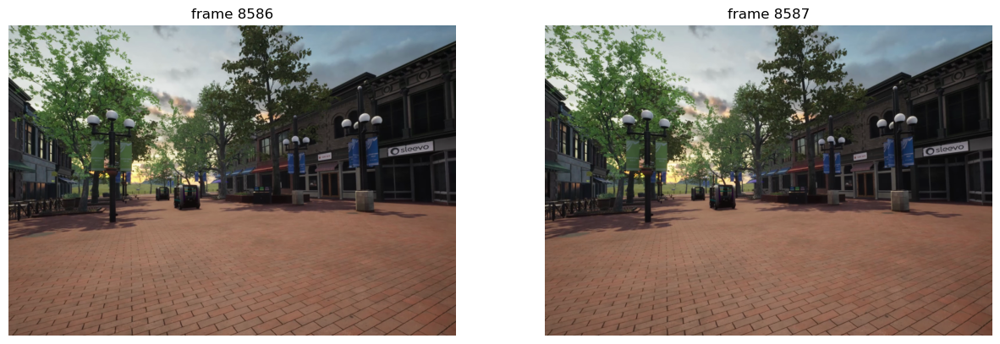

In [560]:
# frames = find_frames(pid, video_path, cap, first_valid=(4*60+20)*36, plus=36)
# frames = find_frames(pid, video_path, cap, first_valid=9383, plus=2)
frames = find_frames(pid, video_path, cap, first_valid=8586, plus=2)

In [561]:
check_visually_and_clip(filename, frames, pid, sid)

['../data/vrdata/combined/P40_2025114131911860.csv']
238.646 247.136606 257.384678
Clipped frames 238.646–248.894072 saved to ../testPS.mp4


In [559]:
260.7955 - (269.324839 - 247.136606)

238.607267

In [562]:
# Get fps and basic info
pid = 40
filename = f'P{pid}-2'
sid = 4

cap, video_path = read_videos(filename)

VIDEO= ../data/videodata/videoraw/P40-2.mp4
FPS=36.155230840192786, frames=1100, duration(s)=30.42


FOR PERSON 40 in VIDEO= ../data/videodata/videoraw/P40-2.mp4


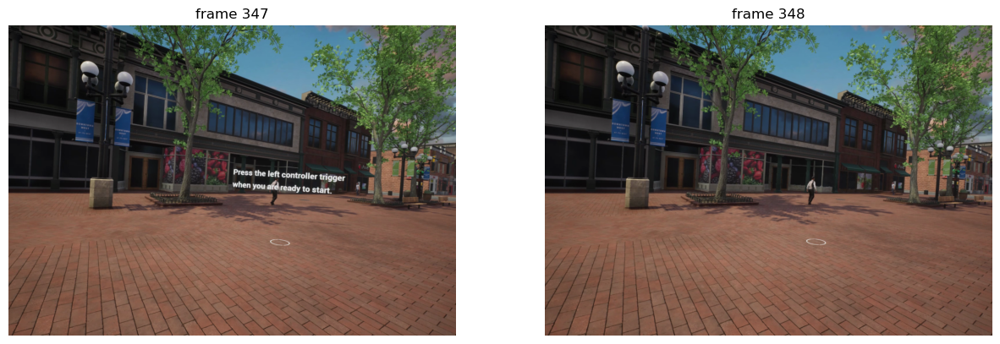

In [565]:
# frames = find_frames(pid, video_path, cap, first_valid=(0*60+9)*36, plus=36)
frames = find_frames(pid, video_path, cap, first_valid=347, plus=2)

In [566]:
check_visually_and_clip(filename, frames, pid, sid)

['../data/vrdata/combined/P40_2025114131911860.csv']
9.670833 14.420281 32.222875
Clipped frames 9.670833–27.473427 saved to ../testPS.mp4


In [594]:
# Get fps and basic info
pid = 40
filename = f'P{pid}-3'
sid = 9

cap, video_path = read_videos(filename)

VIDEO= ../data/videodata/videoraw/P40-3.mp4
FPS=36.040486911786516, frames=3273, duration(s)=90.81


FOR PERSON 40 in VIDEO= ../data/videodata/videoraw/P40-3.mp4


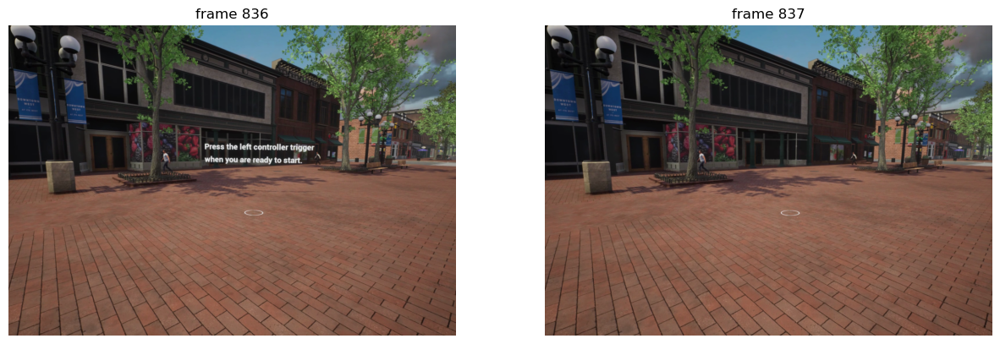

In [599]:
# frames = find_frames(pid, video_path, cap, first_valid=(0*60+23)*36, plus=36)
# frames = find_frames(pid, video_path, cap, first_valid=1368, plus=2)
frames = find_frames(pid, video_path, cap, first_valid=836, plus=2)

FOR PERSON 40 in VIDEO= ../data/videodata/videoraw/P40-3.mp4


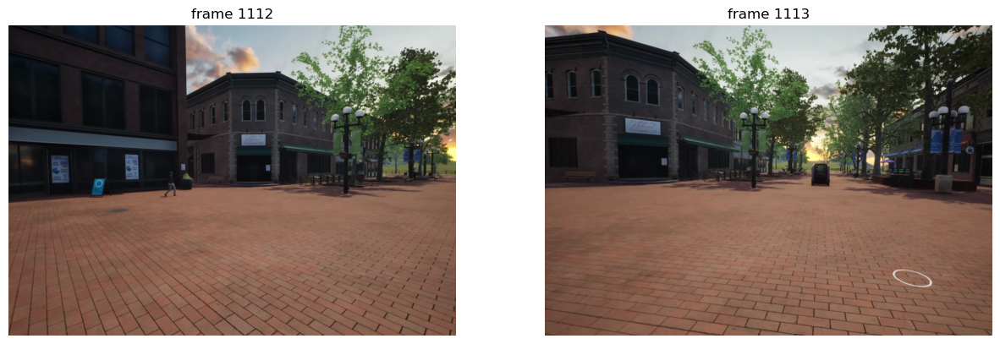

In [578]:
frames = find_frames(pid, video_path, cap, first_valid=1112, plus=2)

In [600]:
check_visually_and_clip(filename, frames, pid, sid)

['../data/vrdata/combined/P40_2025114131911860.csv']
23.264067 27.868051 34.361736
Clipped frames 23.264067–29.757752 saved to ../testPS.mp4


## P41

In [601]:
# Get fps and basic info
pid = 41
filename = f'P{pid}-1'
sid = 1

cap, video_path = read_videos(filename)

VIDEO= ../data/videodata/videoraw/P41-1.mp4
FPS=35.99295777177681, frames=18369, duration(s)=510.35


FOR PERSON 41 in VIDEO= ../data/videodata/videoraw/P41-1.mp4


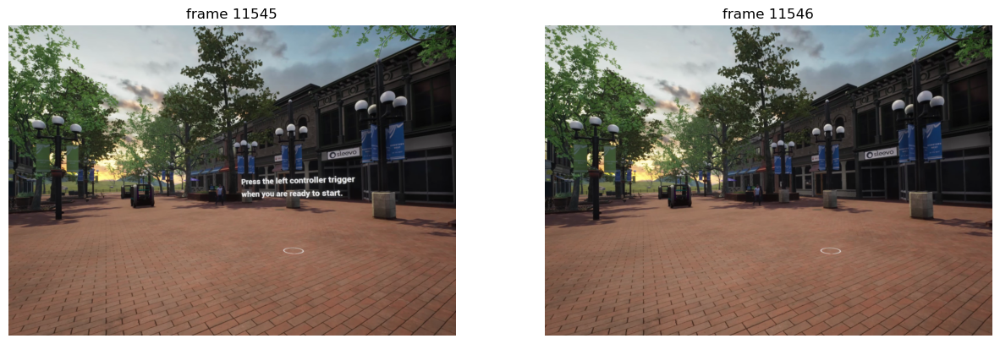

In [604]:
# frames = find_frames(pid, video_path, cap, first_valid=(5*60+20)*36, plus=36)
frames = find_frames(pid, video_path, cap, first_valid=11545, plus=2)

In [605]:
check_visually_and_clip(filename, frames, pid, sid)

['../data/vrdata/combined/P41_202511414230295.csv']
320.8803 426.727747 432.97482
Clipped frames 320.8803–327.127373 saved to ../testPS.mp4


In [607]:
# Get fps and basic info
pid = 41
filename = f'P{pid}-2'
sid = 5

cap, video_path = read_videos(filename)

VIDEO= ../data/videodata/videoraw/P41-2.mp4
FPS=36.05075635264902, frames=2780, duration(s)=77.11


FOR PERSON 41 in VIDEO= ../data/videodata/videoraw/P41-2.mp4


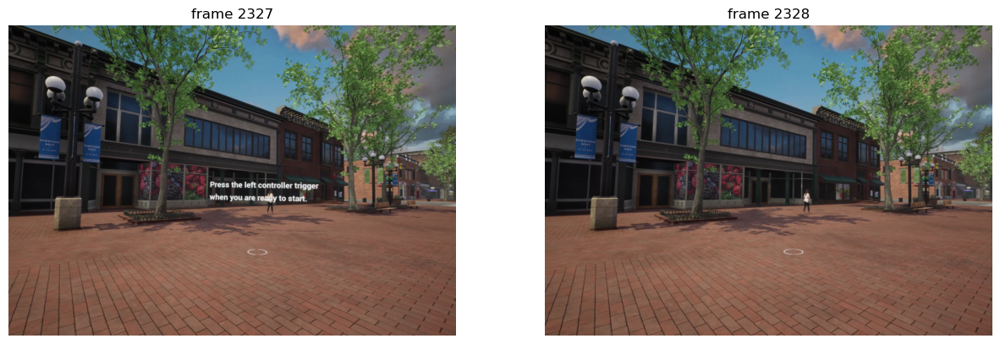

In [610]:
# frames = find_frames(pid, video_path, cap, first_valid=(1*60+4)*36, plus=36)
frames = find_frames(pid, video_path, cap, first_valid=2327, plus=2)

In [611]:
check_visually_and_clip(filename, frames, pid, sid)

['../data/vrdata/combined/P41_202511414230295.csv']
64.704733 67.848256 77.586595
Clipped frames 64.704733–74.443072 saved to ../testPS.mp4


In [613]:
# Get fps and basic info
pid = 41
filename = f'P{pid}-4'
sid = 9

cap, video_path = read_videos(filename)

VIDEO= ../data/videodata/videoraw/P41-4.mp4
FPS=36.23045968968234, frames=768, duration(s)=21.20


FOR PERSON 41 in VIDEO= ../data/videodata/videoraw/P41-4.mp4


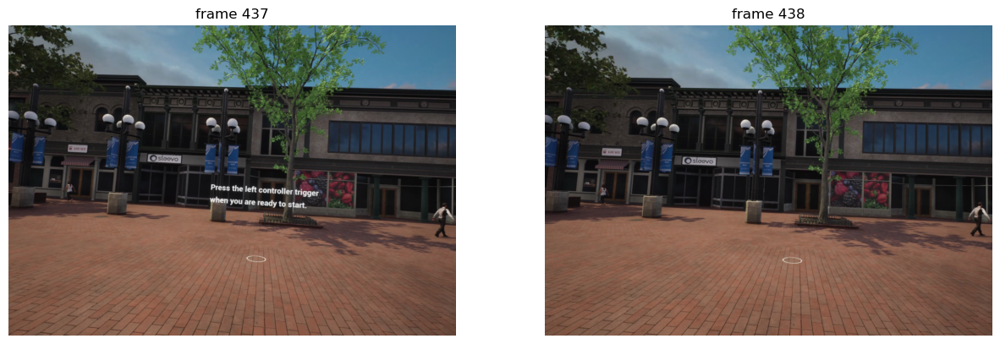

In [615]:
# frames = find_frames(pid, video_path, cap, first_valid=(0*60+12)*36, plus=36)
frames = find_frames(pid, video_path, cap, first_valid=437, plus=2)

In [616]:
check_visually_and_clip(filename, frames, pid, sid)

['../data/vrdata/combined/P41_202511414230295.csv']
12.173267 15.977384 22.128765
Clipped frames 12.173267–18.324648 saved to ../testPS.mp4


## P44

In [653]:
# Get fps and basic info
pid = 44
filename = f'P{pid}-1'
sid = 1

cap, video_path = read_videos(filename)

VIDEO= ../data/videodata/videoraw/P44-1.mp4
FPS=35.99506310251459, frames=15247, duration(s)=423.59


FOR PERSON 44 in VIDEO= ../data/videodata/videoraw/P44-1.mp4


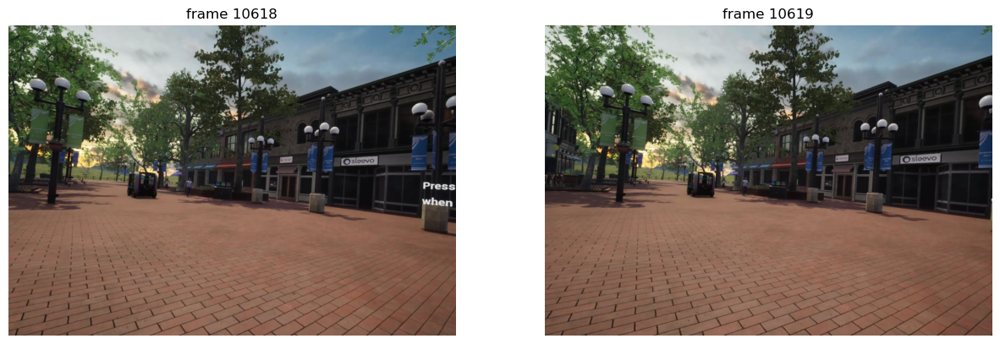

In [654]:
# frames = find_frames(pid, video_path, cap, first_valid=(4*60+54)*36, plus=36)
frames = find_frames(pid, video_path, cap, first_valid=10618, plus=2)

In [656]:
check_visually_and_clip(filename, frames, pid, sid, plus=4+7)

['../data/vrdata/combined/P44_2025114171410580.csv']
295.3165 300.693025 322.191921
Clipped frames 295.3165–316.815396 saved to ../testPS.mp4


In [ ]:
# Get fps and basic info
pid = 44
filename = f'P{pid}-2'
sid = 4

cap, video_path = read_videos(filename)

VIDEO= ../data/videodata/videoraw/P41-1.mp4
FPS=35.99295777177681, frames=18369, duration(s)=510.35


FOR PERSON 44 in VIDEO= ../data/videodata/videoraw/P44-2.mp4


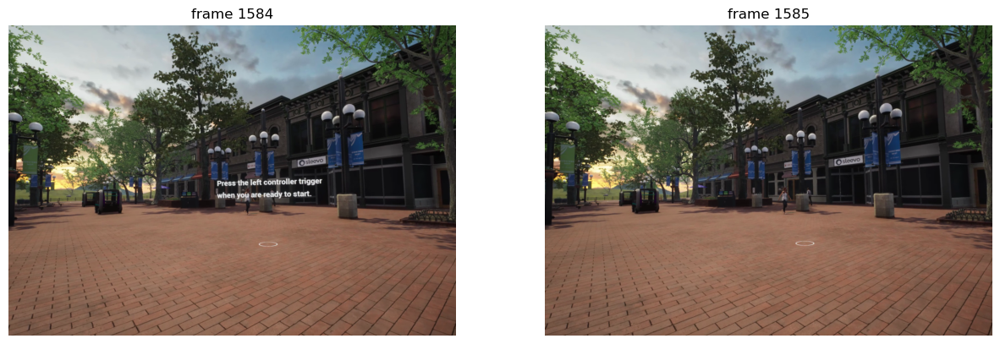

In [624]:
# frames = find_frames(pid, video_path, cap, first_valid=(0*60+44)*36, plus=36)
frames = find_frames(pid, video_path, cap, first_valid=1584, plus=2)

In [625]:
check_visually_and_clip(filename, frames, pid, sid, plus=5)

['../data/vrdata/combined/P44_2025114171410580.csv']
44.082067 48.61308 60.851735
Clipped frames 44.082067–56.320722 saved to ../testPS.mp4


## P46

In [635]:
# Get fps and basic info
pid = 46
filename = f'P{pid}-1'
sid = 2

cap, video_path = read_videos(filename)

VIDEO= ../data/videodata/videoraw/P46-1.mp4
FPS=35.99119599226802, frames=22203, duration(s)=616.90


FOR PERSON 46 in VIDEO= ../data/videodata/videoraw/P46-1.mp4


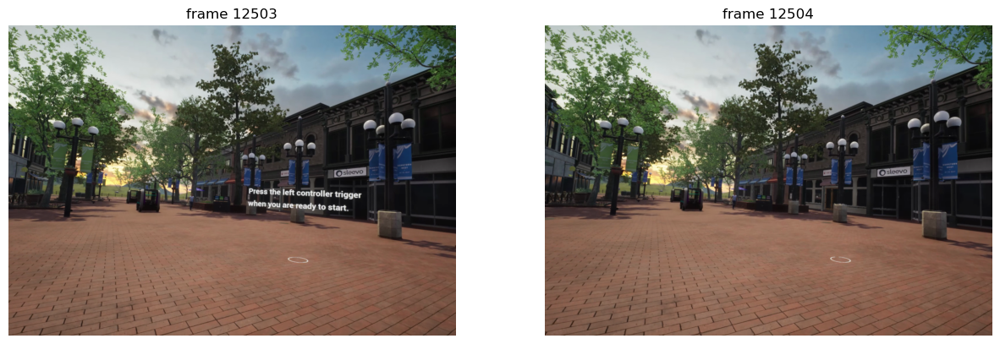

In [633]:
# frames = find_frames(pid, video_path, cap, first_valid=(5*60+47)*36, plus=36)
frames = find_frames(pid, video_path, cap, first_valid=12503, plus=2)

In [636]:
check_visually_and_clip(filename, frames, pid, sid)

['../data/vrdata/combined/P46_202511611914394.csv']
347.5002 482.832296 500.422663
Clipped frames 347.5002–365.090567 saved to ../testPS.mp4


In [641]:
# Get fps and basic info
pid = 46
filename = f'P{pid}-2'
sid = 1

cap, video_path = read_videos(filename)

VIDEO= ../data/videodata/videoraw/P46-2.mp4
FPS=36.101956827414796, frames=1591, duration(s)=44.07


FOR PERSON 46 in VIDEO= ../data/videodata/videoraw/P46-2.mp4


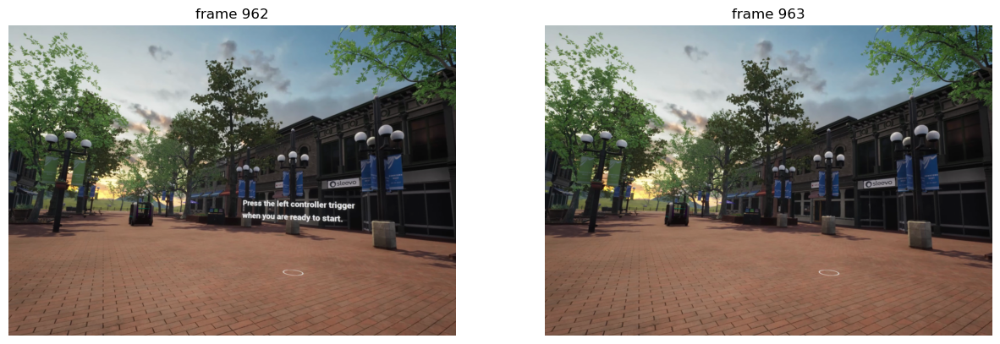

In [642]:
# frames = find_frames(pid, video_path, cap, first_valid=(0*60+26)*36, plus=36)
frames = find_frames(pid, video_path, cap, first_valid=962, plus=2)

In [643]:
check_visually_and_clip(filename, frames, pid, sid)

['../data/vrdata/combined/P46_202511611914394.csv']
26.766067 29.878674 42.981076
Clipped frames 26.766067–39.868469000000005 saved to ../testPS.mp4


In [644]:
# Get fps and basic info
pid = 46
filename = f'P{pid}-3'
sid = 5

cap, video_path = read_videos(filename)

VIDEO= ../data/videodata/videoraw/P46-3.mp4
FPS=36.141158852017504, frames=1197, duration(s)=33.12


FOR PERSON 46 in VIDEO= ../data/videodata/videoraw/P46-3.mp4


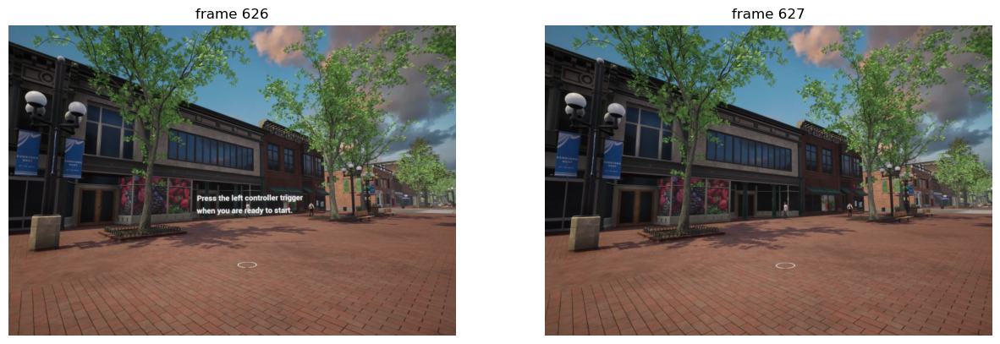

In [646]:
# frames = find_frames(pid, video_path, cap, first_valid=(0*60+17)*36, plus=36)
frames = find_frames(pid, video_path, cap, first_valid=626, plus=2)

In [647]:
check_visually_and_clip(filename, frames, pid, sid)

['../data/vrdata/combined/P46_202511611914394.csv']
17.426 22.060311 33.844379
Clipped frames 17.426–29.210068000000003 saved to ../testPS.mp4


In [648]:
# Get fps and basic info
pid = 46
filename = f'P{pid}-5'
sid = 11

cap, video_path = read_videos(filename)

VIDEO= ../data/videodata/videoraw/P46-5.mp4
FPS=36.17492848006717, frames=988, duration(s)=27.31


FOR PERSON 46 in VIDEO= ../data/videodata/videoraw/P46-5.mp4


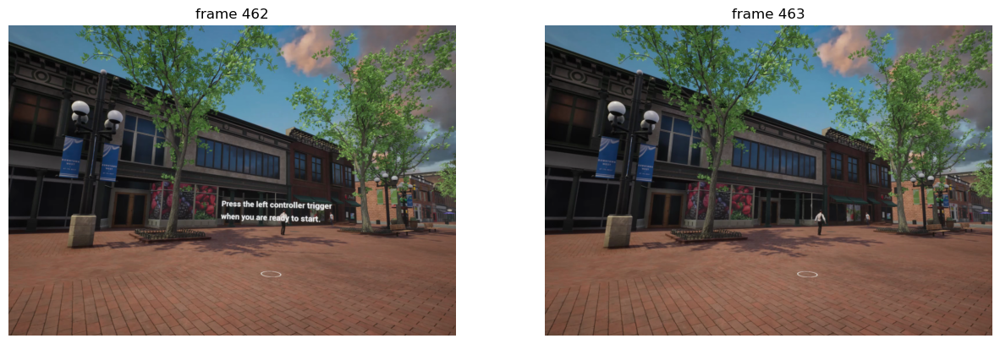

In [651]:
# frames = find_frames(pid, video_path, cap, first_valid=(0*60+12)*36, plus=36)
frames = find_frames(pid, video_path, cap, first_valid=462, plus=2)

In [652]:
check_visually_and_clip(filename, frames, pid, sid)

['../data/vrdata/combined/P46_202511611914394.csv']
12.875767 15.764665 26.373397
Clipped frames 12.875767–23.484499 saved to ../testPS.mp4


## P47 

In [681]:
# Get fps and basic info
pid = 47
filename = f'P{pid}-2'
sid = 1

cap, video_path = read_videos(filename)

VIDEO= ../data/videodata/videoraw/P47-2.mp4
FPS=36.00062752446725, frames=10533, duration(s)=292.58


FOR PERSON 47 in VIDEO= ../data/videodata/videoraw/P47-2.mp4


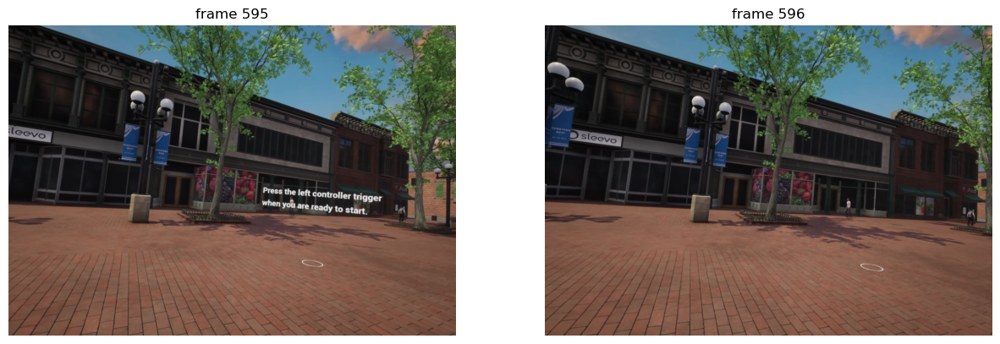

In [682]:
# frames = find_frames(pid, video_path, cap, first_valid=(0*60+16)*36, plus=36)
frames = find_frames(pid, video_path, cap, first_valid=595, plus=2)

In [683]:
check_visually_and_clip(filename, frames, pid, sid, plus=6)

['../data/vrdata/combined/P47_202511614223187.csv']
16.625967 23.687147 41.87739
Clipped frames 16.625967–34.81621 saved to ../testPS.mp4


In [678]:
# Get fps and basic info
pid = 47
filename = f'P{pid}-3_2'
sid = 12

cap, video_path = read_videos(filename)

VIDEO= ../data/videodata/videoraw/P47-3_2.mp4
FPS=36.1335648334464, frames=1257, duration(s)=34.79


FOR PERSON 47 in VIDEO= ../data/videodata/videoraw/P47-3_2.mp4


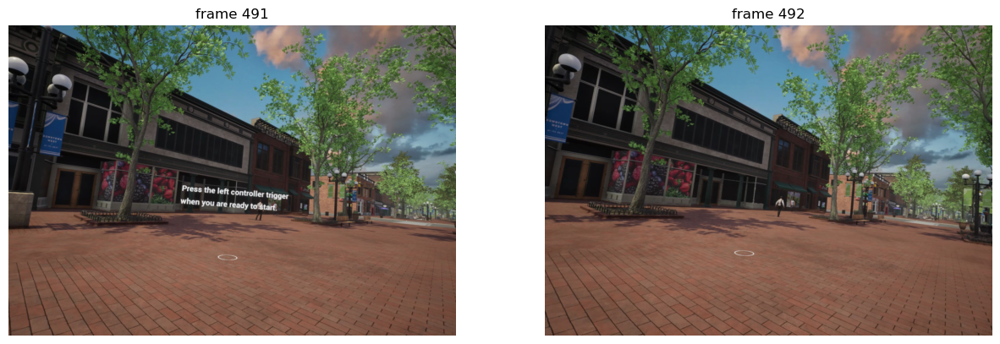

In [679]:
# frames = find_frames(pid, video_path, cap, first_valid=(0*60+13)*36, plus=36)
frames = find_frames(pid, video_path, cap, first_valid=491, plus=2)

In [ ]:
check_visually_and_clip(filename, frames, pid, sid, plus=4)

['../data/vrdata/combined/P47_202511614223187.csv']
13.7072 17.650388 33.427442
Clipped frames 13.7072–29.484254 saved to ../testPS.mp4


## P48

In [707]:
# Get fps and basic info
pid = 48
filename = f'P{pid}-2'
sid = 2

cap, video_path = read_videos(filename)

VIDEO= ../data/videodata/videoraw/P48-2.mp4
FPS=35.99950637307618, frames=11231, duration(s)=311.98


FOR PERSON 48 in VIDEO= ../data/videodata/videoraw/P48-2.mp4


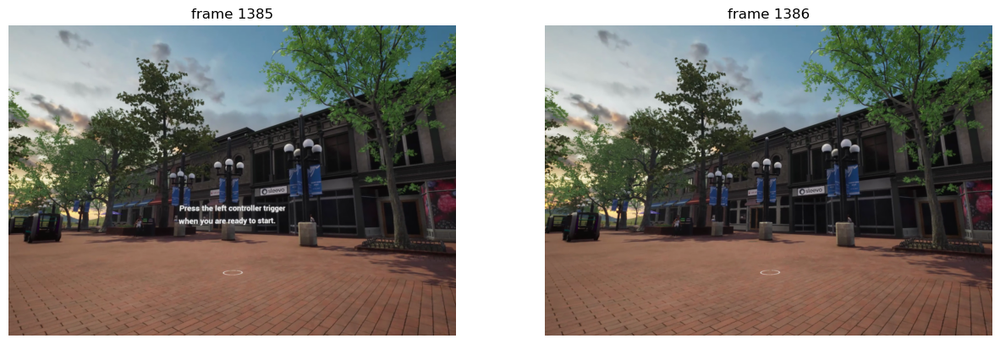

In [708]:
# frames = find_frames(pid, video_path, cap, first_valid=(0*60+38)*36, plus=36)
frames = find_frames(pid, video_path, cap, first_valid=1385, plus=2)

In [709]:
check_visually_and_clip(filename, frames, pid, sid, plus=5)

['../data/vrdata/combined/P48_2025116151043950.csv']
38.553933 54.536244 66.544701
Clipped frames 38.553933–50.56239 saved to ../testPS.mp4


In [ ]:
46.447185 - 35.606750999999996)

FOR PERSON 48 in VIDEO= ../data/videodata/videoraw/P48-2.mp4


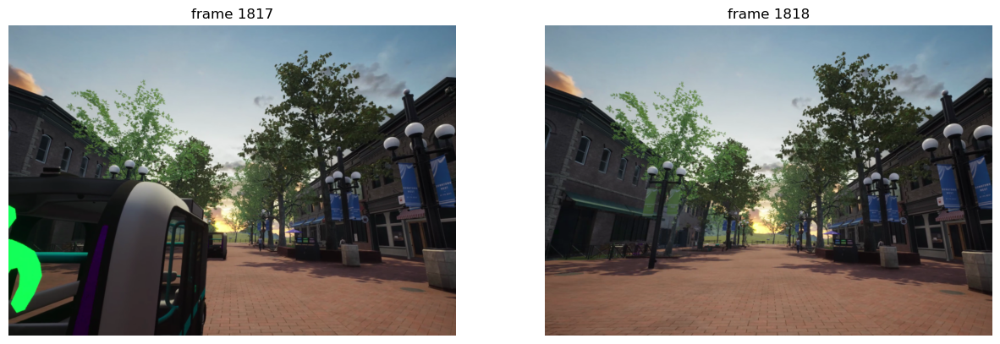

In [702]:
# frames = find_frames(pid, video_path, cap, first_valid=(0*60+50)*36, plus=36)
frames = find_frames(pid, video_path, cap, first_valid=1817, plus=2)

In [703]:
get_start_in_video_metadata(filename, row=1385), get_start_in_video_metadata(filename, row=1817)

(np.float64(38.526167), np.float64(50.531933))

In [706]:
66.544701 - (50.531933 - 38.526167)

54.538935

## P49

In [687]:
# Get fps and basic info
pid = 49
filename = f'P{pid}-2'
sid = 1

cap, video_path = read_videos(filename)

VIDEO= ../data/videodata/videoraw/P49-2.mp4
FPS=36.001921471465785, frames=9818, duration(s)=272.71


FOR PERSON 49 in VIDEO= ../data/videodata/videoraw/P49-2.mp4


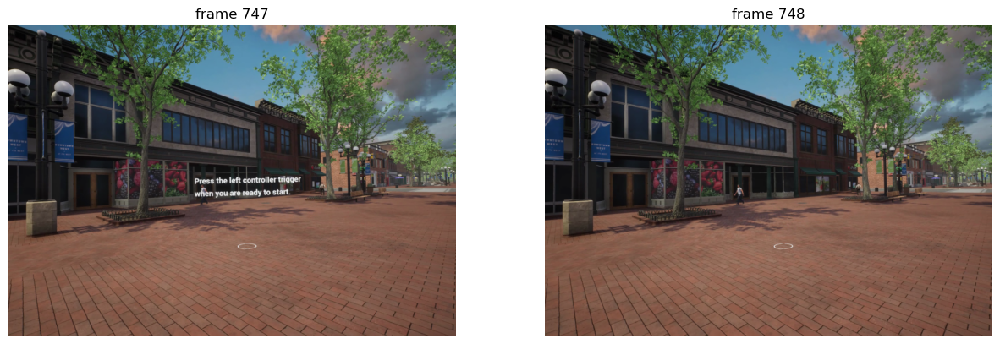

In [690]:
# frames = find_frames(pid, video_path, cap, first_valid=(0*60+20)*36, plus=36)
frames = find_frames(pid, video_path, cap, first_valid=747, plus=2)

In [692]:
check_visually_and_clip(filename, frames, pid, sid, plus=5)

['../data/vrdata/combined/P49_2025116171511625.csv']
20.8231 25.149486 31.833095
Clipped frames 20.8231–27.506709 saved to ../testPS.mp4


In [693]:
# Get fps and basic info
pid = 49
filename = f'P{pid}-3'
sid = 7

cap, video_path = read_videos(filename)

VIDEO= ../data/videodata/videoraw/P49-3.mp4
FPS=36.15167607926542, frames=1123, duration(s)=31.06


FOR PERSON 49 in VIDEO= ../data/videodata/videoraw/P49-3.mp4


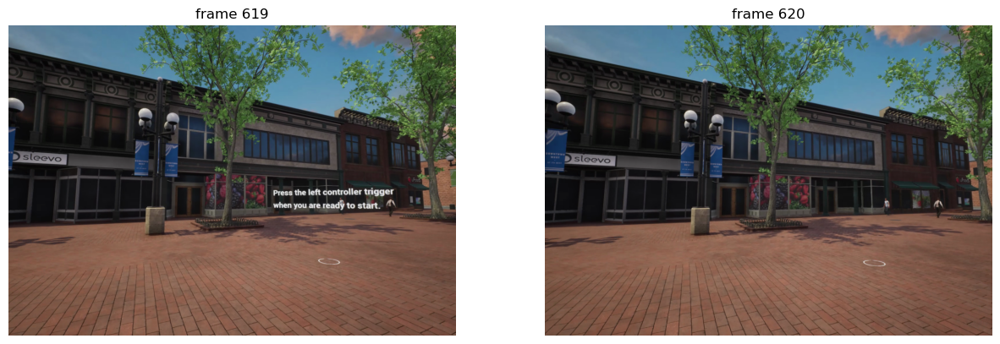

In [695]:
# frames = find_frames(pid, video_path, cap, first_valid=(0*60+17)*36, plus=36)
frames = find_frames(pid, video_path, cap, first_valid=619, plus=2)

In [696]:
check_visually_and_clip(filename, frames, pid, sid, plus=5)

['../data/vrdata/combined/P49_2025116171511625.csv']
17.259267 20.707622 31.494734
Clipped frames 17.259267–28.046379 saved to ../testPS.mp4


## P50

In [710]:
# Get fps and basic info
pid = 50
filename = f'P{pid}-1'
sid = 1

cap, video_path = read_videos(filename)

VIDEO= ../data/videodata/videoraw/P50-1.mp4
FPS=35.99381406211695, frames=16909, duration(s)=469.78


FOR PERSON 50 in VIDEO= ../data/videodata/videoraw/P50-1.mp4


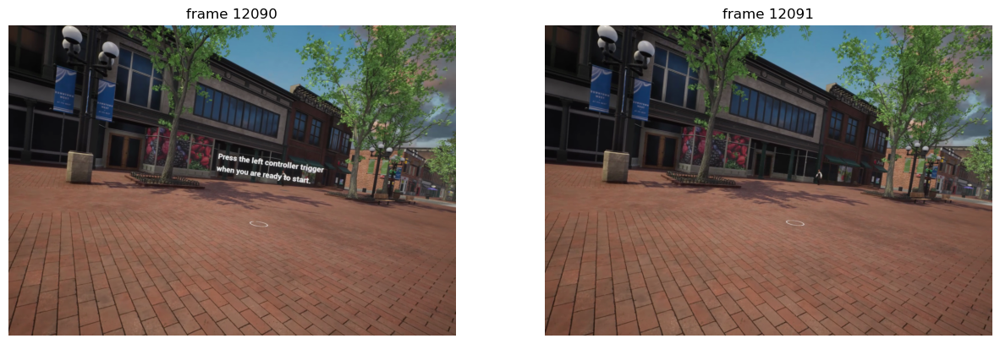

In [713]:
# frames = find_frames(pid, video_path, cap, first_valid=(5*60+35)*36, plus=36)
frames = find_frames(pid, video_path, cap, first_valid=12090, plus=2)

In [714]:
check_visually_and_clip(filename, frames, pid, sid, plus=5)

['../data/vrdata/combined/P50_202511813834529.csv']
336.050767 463.338631 472.280674
Clipped frames 336.050767–344.99280999999996 saved to ../testPS.mp4


In [719]:
# Get fps and basic info
pid = 50
filename = f'P{pid}-2'
sid = 6

cap, video_path = read_videos(filename)

VIDEO= ../data/videodata/videoraw/P50-2.mp4
FPS=36.01468408294949, frames=5903, duration(s)=163.91


FOR PERSON 50 in VIDEO= ../data/videodata/videoraw/P50-2.mp4


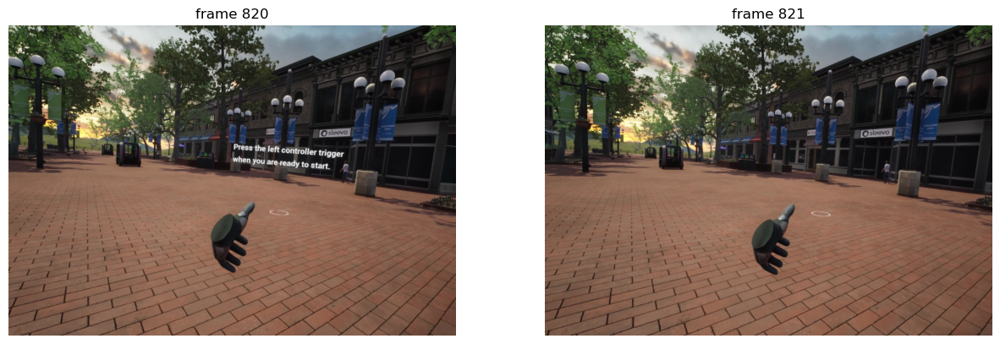

In [721]:
# frames = find_frames(pid, video_path, cap, first_valid=(0*60+22)*36, plus=36)
frames = find_frames(pid, video_path, cap, first_valid=820, plus=2)

In [722]:
check_visually_and_clip(filename, frames, pid, sid, plus=5)

['../data/vrdata/combined/P50_202511813834529.csv']
22.849 33.874753 44.611011
Clipped frames 22.849–33.585257999999996 saved to ../testPS.mp4


## P51

In [723]:
# Get fps and basic info
pid = 51
filename = f'P{pid}-1'
sid = 1

cap, video_path = read_videos(filename)

VIDEO= ../data/videodata/videoraw/P51-1.mp4
FPS=35.9898972057535, frames=24777, duration(s)=688.44


FOR PERSON 51 in VIDEO= ../data/videodata/videoraw/P51-1.mp4


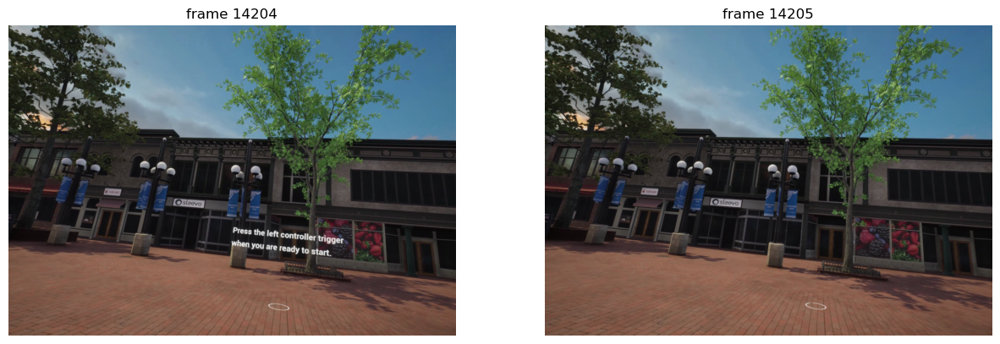

In [726]:
# frames = find_frames(pid, video_path, cap, first_valid=(6*60+34)*36, plus=36)
frames = find_frames(pid, video_path, cap, first_valid=14204, plus=2)

In [727]:
check_visually_and_clip(filename, frames, pid, sid, plus=5)

['../data/vrdata/combined/P51_2025118141418658.csv']
394.807333 551.085612 566.778872
Clipped frames 394.807333–410.50059300000004 saved to ../testPS.mp4


In [728]:
# Get fps and basic info
pid = 51
filename = f'P{pid}-2'
sid = 3

cap, video_path = read_videos(filename)

VIDEO= ../data/videodata/videoraw/P51-2.mp4
FPS=36.16175905351713, frames=1060, duration(s)=29.31


FOR PERSON 51 in VIDEO= ../data/videodata/videoraw/P51-2.mp4


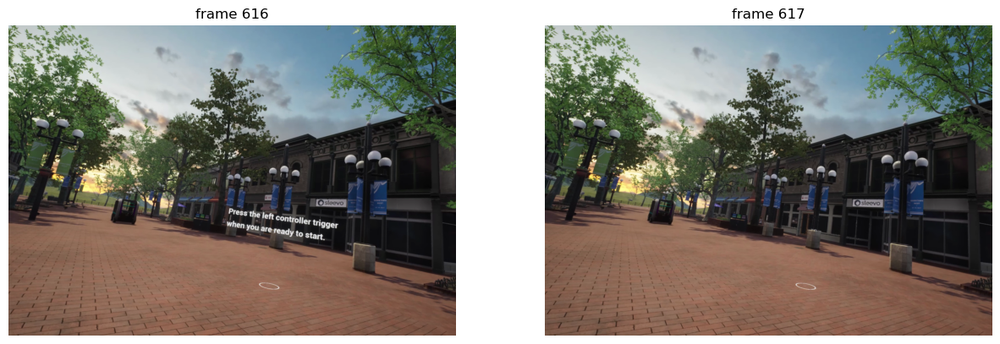

In [730]:
# frames = find_frames(pid, video_path, cap, first_valid=(0*60+17)*36, plus=36)
frames = find_frames(pid, video_path, cap, first_valid=616, plus=2)

In [731]:
check_visually_and_clip(filename, frames, pid, sid, plus=5)

['../data/vrdata/combined/P51_2025118141418658.csv']
17.180067 32.404306 40.199407
Clipped frames 17.180067–24.975168000000004 saved to ../testPS.mp4


In [732]:
# Get fps and basic info
pid = 51
filename = f'P{pid}-3'
sid = 10

cap, video_path = read_videos(filename)

VIDEO= ../data/videodata/videoraw/P51-3.mp4
FPS=36.1786756140543, frames=969, duration(s)=26.78


FOR PERSON 51 in VIDEO= ../data/videodata/videoraw/P51-3.mp4


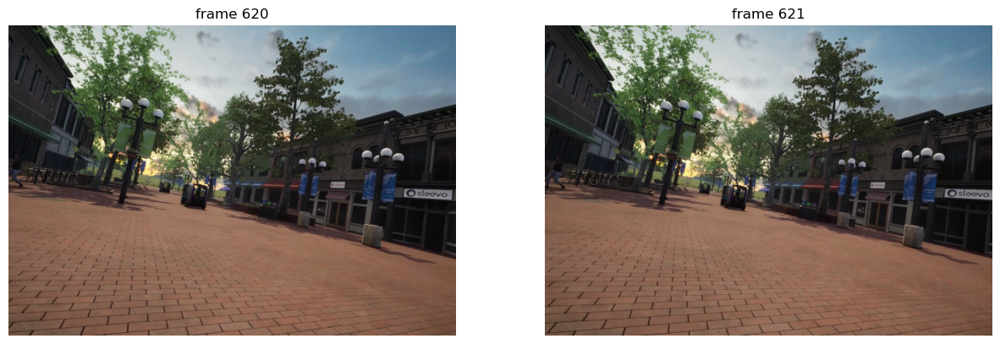

In [734]:
# frames = find_frames(pid, video_path, cap, first_valid=(0*60+17)*36, plus=36)
frames = find_frames(pid, video_path, cap, first_valid=620, plus=2)

In [735]:
check_visually_and_clip(filename, frames, pid, sid, plus=5)

['../data/vrdata/combined/P51_2025118141418658.csv']
17.294267 24.689933 29.884804
Clipped frames 17.294267–22.489138 saved to ../testPS.mp4


In [736]:
# Get fps and basic info
pid = 51
filename = f'P{pid}-4'
sid = 1

cap, video_path = read_videos(filename)

VIDEO= ../data/videodata/videoraw/P51-4.mp4
FPS=36.12938346083327, frames=1292, duration(s)=35.76


FOR PERSON 51 in VIDEO= ../data/videodata/videoraw/P51-4.mp4


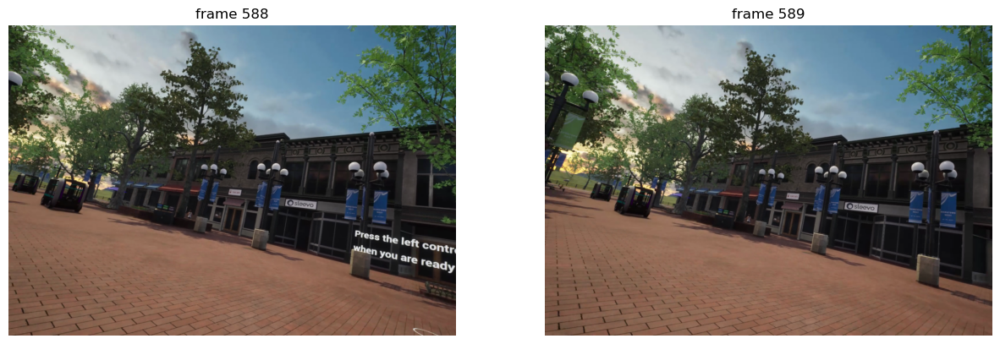

In [738]:
# frames = find_frames(pid, video_path, cap, first_valid=(0*60+16)*36, plus=36)
frames = find_frames(pid, video_path, cap, first_valid=588, plus=2)

In [739]:
check_visually_and_clip(filename, frames, pid, sid, plus=5)

['../data/vrdata/combined/P51_2025118141418658.csv']
16.403 551.085612 566.778872
Clipped frames 16.403–32.09626000000001 saved to ../testPS.mp4


## Check eye gaze overlay

In [276]:
# Get fps and basic info

video_path = f'../data/videoclips/P1/P1S1.mp4'
print('VIDEO=', video_path)
cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    print('Cannot open', video_path)
else:
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duration_sec = frame_count / fps if fps > 0 else None
    width  = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    print(f'FPS={fps}, frames={frame_count}, duration(s)={duration_sec:.2f}, width={width}, height={height}')
# cap.release()

VIDEO= ../data/videoclips/P1/P1S1.mp4
FPS=29.97002997002997, frames=164, duration(s)=5.47, width=1536, height=1068


FOR PERSON 1 in VIDEO= ../data/videoclips/P1/P1S1.mp4
Read frame 6, shape=(1068, 1536, 3)
Read frame 7, shape=(1068, 1536, 3)


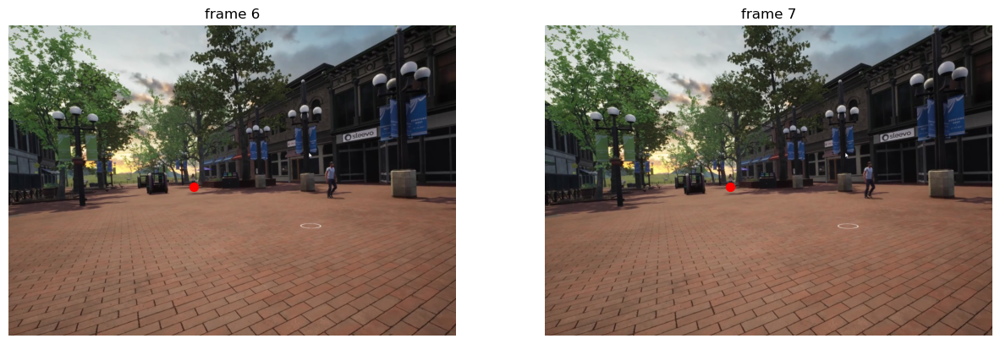

In [300]:
video_path = f'../data/videoclips/P1/P1S1.mp4'
print("FOR PERSON", pid, 'in VIDEO=', video_path)

frames = []
for i in [6, 7]:
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
    ret, frame = cap.read()
    if not ret:
        continue
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    frames.append((int(i), rgb))
    print(f"Read frame {i}, shape={frame.shape}")

fig, axs = plt.subplots(1, len(frames), figsize=(15, 5))
for ax, (i, fr) in zip(axs, frames):
    ax.imshow(fr)
    ax.set_title(f'frame {i}')
    ax.scatter([1536 - 900.0551605072492], [1068 - 511.6608936482349], c='red', s=50)
    ax.axis('off')
plt.show()

In [279]:
(314.068482 - 313.513266)/0.03

18.507200000001

FOR PERSON 1 in VIDEO= ../data/videoclips/P1/P1S1.mp4
Read frame 17, shape=(1068, 1536, 3)
Read frame 18, shape=(1068, 1536, 3)
Read frame 19, shape=(1068, 1536, 3)
Read frame 20, shape=(1068, 1536, 3)


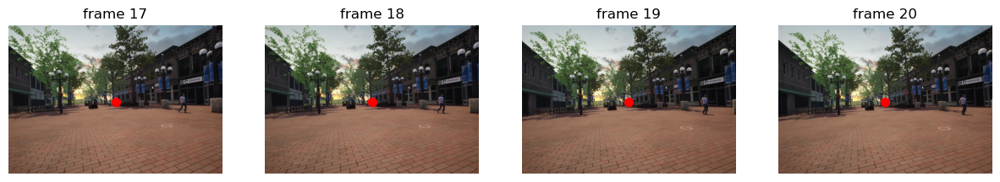

In [306]:
video_path = f'../data/videoclips/P1/P1S1.mp4'
print("FOR PERSON", pid, 'in VIDEO=', video_path)

frames = []
for i in [17, 18, 19, 20]:
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
    ret, frame = cap.read()
    if not ret:
        continue
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    frames.append((int(i), rgb))
    print(f"Read frame {i}, shape={frame.shape}")

fig, axs = plt.subplots(1, len(frames), figsize=(15, 5))
for ax, (i, fr) in zip(axs, frames):
    ax.imshow(fr)
    ax.set_title(f'frame {i}') 
    ax.scatter([1536 - 766.5507995103078], [1068 - 515.1682437267552], c='red', s=50) # 左右是对的，上下是颠倒的
    ax.axis('off')
plt.show()

In [301]:
(316.650175 - 313.513266)/0.03

104.56363333333343

FOR PERSON 1 in VIDEO= ../data/videoclips/P1/P1S1.mp4
Read frame 101, shape=(1068, 1536, 3)
Read frame 102, shape=(1068, 1536, 3)
Read frame 103, shape=(1068, 1536, 3)
Read frame 104, shape=(1068, 1536, 3)
Read frame 105, shape=(1068, 1536, 3)
Read frame 106, shape=(1068, 1536, 3)
Read frame 107, shape=(1068, 1536, 3)


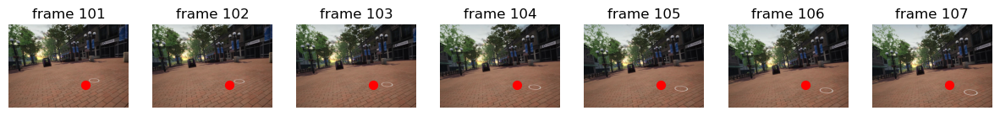

In [305]:
video_path = f'../data/videoclips/P1/P1S1.mp4'
print("FOR PERSON", pid, 'in VIDEO=', video_path)

frames = []
for i in [101, 102, 103, 104, 105, 106, 107]:
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
    ret, frame = cap.read()
    if not ret:
        continue
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    frames.append((int(i), rgb))
    print(f"Read frame {i}, shape={frame.shape}")

fig, axs = plt.subplots(1, len(frames), figsize=(15, 5))
for ax, (i, fr) in zip(axs, frames):
    ax.imshow(fr)
    ax.set_title(f'frame {i}') 
    ax.scatter([1536 - 551.5353156638216], [1068 - 297.05048877614206], c='red', s=50) # 左右是对的，上下是颠倒的
    ax.axis('off')
plt.show()

In [315]:
fr

array([[[166, 178, 180],
        [166, 178, 180],
        [166, 178, 180],
        ...,
        [ 54,  54,  54],
        [ 48,  46,  47],
        [ 44,  41,  42]],

       [[166, 178, 180],
        [166, 178, 180],
        [166, 178, 180],
        ...,
        [ 53,  53,  53],
        [ 47,  45,  46],
        [ 41,  39,  40]],

       [[166, 178, 180],
        [166, 178, 180],
        [166, 178, 180],
        ...,
        [ 54,  56,  58],
        [ 47,  47,  47],
        [ 41,  41,  41]],

       ...,

       [[112,  81,  63],
        [112,  81,  63],
        [111,  80,  62],
        ...,
        [111,  77,  61],
        [111,  77,  61],
        [111,  77,  61]],

       [[111,  80,  62],
        [111,  80,  62],
        [109,  77,  60],
        ...,
        [112,  79,  62],
        [112,  79,  62],
        [111,  77,  61]],

       [[110,  79,  61],
        [109,  77,  60],
        [108,  76,  59],
        ...,
        [112,  79,  62],
        [112,  79,  62],
        [112,  79,  62]]

In [307]:
import pandas as pd

# Example data
# A has timestamps where you want to copy data into
A = pd.DataFrame({
    'timestamp': pd.to_datetime([
        '2024-01-01 12:00:00',
        '2024-01-01 12:00:05',
        '2024-01-01 12:00:10'
    ]),
    'some_value': [1, 2, 3]
})

# B has timestamps and additional features you want to merge into A
B = pd.DataFrame({
    'timestamp': pd.to_datetime([
        '2024-01-01 12:00:02',
        '2024-01-01 12:00:08'
    ]),
    'feature1': [10, 20],
    'feature2': [0.5, 0.8]
})

# Make sure both are sorted by timestamp
A = A.sort_values('timestamp')
B = B.sort_values('timestamp')

# Perform an asof merge to find the nearest timestamp in B for each row in A
merged = pd.merge_asof(
    A,
    B,
    on='timestamp',
    direction='nearest'  # can also use 'backward' or 'forward'
)

print(merged)

            timestamp  some_value  feature1  feature2
0 2024-01-01 12:00:00           1        10       0.5
1 2024-01-01 12:00:05           2        10       0.5
2 2024-01-01 12:00:10           3        20       0.8


In [308]:
A

,timestamp,some_value
0,2024-01-01 12:00:00,1
1,2024-01-01 12:00:05,2
2,2024-01-01 12:00:10,3


In [309]:
B

,timestamp,feature1,feature2
0,2024-01-01 12:00:02,10,0.5
1,2024-01-01 12:00:08,20,0.8


In [336]:
img.shape

(1068, 1536, 3)

In [348]:
width_px, height_px = 1536, 1068
dpi = 100
figsize = (width_px / dpi, height_px / dpi)

img = np.zeros((height_px, width_px, 3), dtype=np.uint8)

fig, ax = plt.subplots(figsize=figsize, dpi=dpi)
ax = plt.Axes(fig, [0., 0., 1., 1.])  # occupy full figure (no margins)
ax.set_axis_off()
fig.add_axes(ax)
ax.imshow(img, origin='upper', extent=(0, width_px, height_px, 0))  # fix orientation
# ax.scatter([width_px/2], [height_px/2], c='white', s=50)
ax.scatter([1536 - 551.5353156638216], [1068 - 297.05048877614206], c='white', s=50) # 左右是对的，上下是颠倒的
ax.axis('off')

plt.savefig('test.png', dpi=dpi, bbox_inches=None, pad_inches=0)
plt.close(fig)

frame = cv2.imread('test.png')
print(frame.shape)  # should print (1068, 1536, 3)

(1068, 1536, 3)


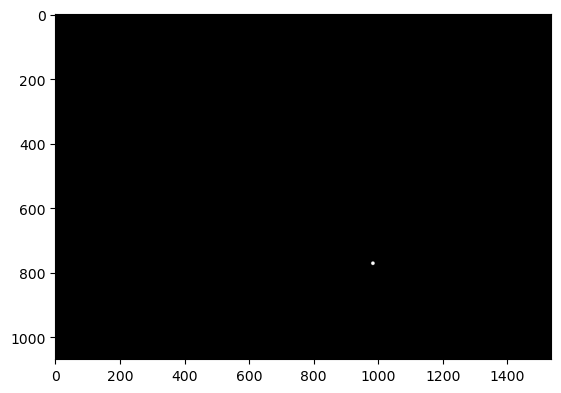

In [349]:
plt.imshow(frame)

In [171]:
import numpy as np
import cv2

def sequential_gaze_salience_map(image_shape, gaze_points, r=30, sigma=10):
    """
    Generate a sequential gaze salience map.
    
    Parameters:
    - image_shape: tuple (H, W)
    - gaze_points: list of (x, y) tuples (oldest → newest)
    - r: radius of influence
    - sigma: std for Gaussian falloff
    
    Returns:
    - salience_map: np.ndarray (H, W) normalized to [0, 255]
    """
    H, W = image_shape[:2]
    S = np.zeros((H, W), dtype=np.float32)
    
    # Time-decaying weights (newer points have higher weights)
    n = len(gaze_points)
    weights = np.linspace(0.2, 1.0, n)
    
    for i, (x, y) in enumerate(gaze_points):
        if x is not None: 
            w = weights[i]
            x, y = int(x), int(y)
            
            # Create a small grid patch around (x, y)
            for dx in range(-r, r+1, 10):
                for dy in range(-r, r+1, 10):
                    if dx**2 + dy**2 <= r**2:
                        xx, yy = x + dx, y + dy
                        if 0 <= xx < W and 0 <= yy < H:
                            S[yy, xx] += w * np.exp(-(dx**2 + dy**2) / (2 * sigma**2))
            
            # Add the fixation center weight directly
            if 0 <= x < W and 0 <= y < H:
                S[y, x] += w
    
    # Apply Gaussian blur
    ksize = int(6 * sigma + 1)
    S = cv2.GaussianBlur(S, (ksize, ksize), sigma)
    
    # Normalize to [0, 255]
    S = cv2.normalize(S, None, 0, 255, cv2.NORM_MINMAX)
    S = S.astype(np.uint8)
    
    return S


def sequential_gaze_salience_map_max(image_shape, gaze_points, r=30, sigma=10):
    H, W = image_shape[:2]
    S = np.zeros((H, W), dtype=np.float32)
    n = len(gaze_points)
    
    # More recent gazes → higher weights
    weights = np.linspace(0.2, 1.0, n)
    
    for i, (x, y) in enumerate(gaze_points):
        if x is not None: 
            w = weights[i]
            x, y = int(x), int(y)
            
            # Generate local Gaussian patch
            yy, xx = np.mgrid[-r:r+1, -r:r+1]
            mask = np.exp(-(xx**2 + yy**2) / (2 * sigma**2))
            mask = mask * w
            
            # Coordinates in image
            x1, x2 = x - r, x + r + 1
            y1, y2 = y - r, y + r + 1
            
            if x1 < 0 or y1 < 0 or x2 > W or y2 > H:
                continue
            
            # Update using MAX instead of ADD
            S_patch = S[y1:y2, x1:x2]
            S[y1:y2, x1:x2] = np.maximum(S_patch, mask)
    
    # Optional smoothing
    ksize = int(2 * sigma + 1)
    S = cv2.GaussianBlur(S, (ksize, ksize), sigma)
    
    # Normalize to [0, 255]
    S = cv2.normalize(S, None, 0, 255, cv2.NORM_MINMAX)
    return S.astype(np.uint8)


In [31]:
def plot_salience_map(S, filepath):
    width_px, height_px = 1536, 1068
    dpi = 100
    figsize = (width_px / dpi, height_px / dpi)

    img = np.zeros((height_px, width_px, 3), dtype=np.uint8)

    fig, ax = plt.subplots(figsize=figsize, dpi=dpi)
    ax = plt.Axes(fig, [0., 0., 1., 1.])  # occupy full figure (no margins)
    ax.set_axis_off()
    fig.add_axes(ax)
    plt.imshow(S, cmap='gray', origin='upper', extent=(0, width_px, height_px, 0))
    plt.axis('off')
    plt.savefig(filepath, dpi=100, bbox_inches=None, pad_inches=0)
    plt.show()


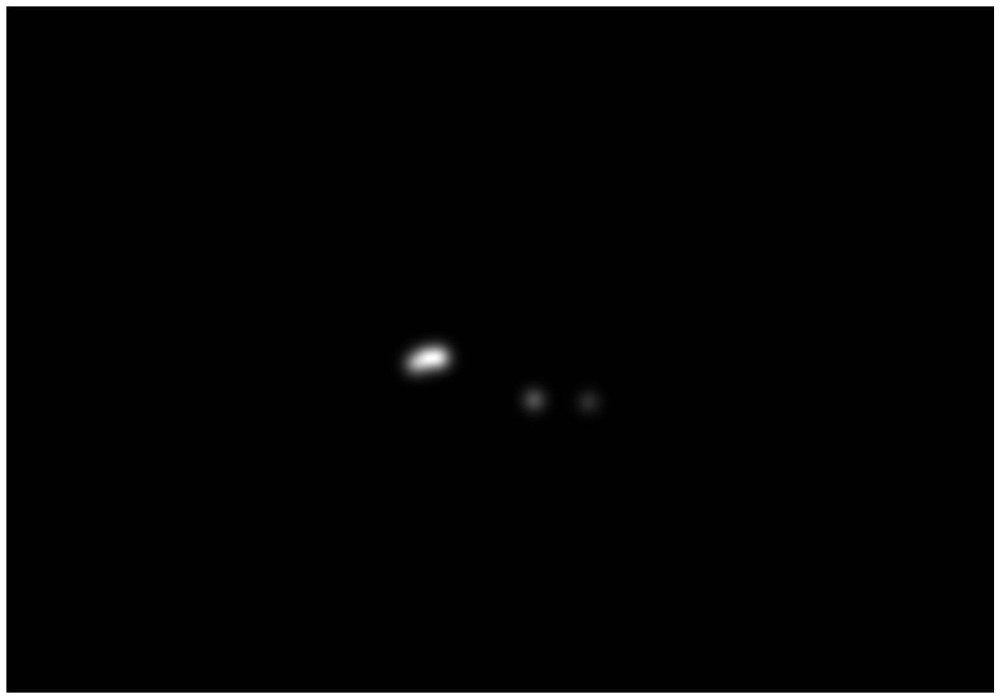

In [ ]:
import matplotlib.pyplot as plt

# Example image size and random gaze sequence
# img_shape = (480, 640)
# gaze_points = [(100, 200), (150, 220), (180, 250), (210, 260), (230, 270)]
img_shape = (1068, 1536)
gaze_points = [
    (905.3993213141488,615.9445557752209), 
    (820.6087465744018,612.1293178909609), 
    (635.9448394927508,556.3391063517652), 
    (652.4321791942018,547.2383656281689), 
    (672.1424444870669,546.7835021248204),
    (None, None)
]

S = sequential_gaze_salience_map(img_shape, gaze_points, r=50)

width_px, height_px = 1536, 1068
dpi = 100
figsize = (width_px / dpi, height_px / dpi)

img = np.zeros((height_px, width_px, 3), dtype=np.uint8)

fig, ax = plt.subplots(figsize=figsize, dpi=dpi)
ax = plt.Axes(fig, [0., 0., 1., 1.])  # occupy full figure (no margins)
ax.set_axis_off()
fig.add_axes(ax)
plt.imshow(S, cmap='gray', origin='upper', extent=(0, width_px, height_px, 0))
plt.axis('off')
plt.savefig('salience_map.png', dpi=100, bbox_inches=None, pad_inches=0)
plt.show()


In [362]:
print(cv2.imread('salience_map.png').shape)  # should print (1068, 1536, 3)

(1068, 1536, 3)


In [4]:
import pandas as pd

In [11]:
meta = pd.read_csv('../data/P1S3_merged.csv')
meta

,timestamp,px_x,px_y,px_u,px_v
0,0.000000,1473.842442,708.768536,749.950697,594.897002
1,0.033367,1473.842442,708.768536,749.950697,594.897002
2,0.066733,1452.120787,687.978364,761.535580,608.774442
3,0.100100,1446.852878,688.129566,764.345132,608.673515
4,0.133467,1434.133173,688.481676,771.128975,608.438481
...,...,...,...,...,...
222,7.407400,1449.693813,574.879088,762.829966,684.268209
223,7.440767,NaN,NaN,NaN,NaN
224,7.474133,NaN,NaN,NaN,NaN
225,7.507500,NaN,NaN,NaN,NaN


FOR PERSON 1 in VIDEO= ../data/videoclips/P1/P1S3.mp4
VIDEO= ../data/videoclips/P1/P1S3.mp4
FPS=29.97002997002997, frames=227, duration(s)=7.57, width=1536, height=1068
Read frame 105, shape=(1068, 1536, 3)
Read frame 114, shape=(1068, 1536, 3)
Read frame 123, shape=(1068, 1536, 3)
Read frame 132, shape=(1068, 1536, 3)
Read frame 141, shape=(1068, 1536, 3)
Read frame 150, shape=(1068, 1536, 3)
Read frame 159, shape=(1068, 1536, 3)
Read frame 168, shape=(1068, 1536, 3)
Read frame 177, shape=(1068, 1536, 3)


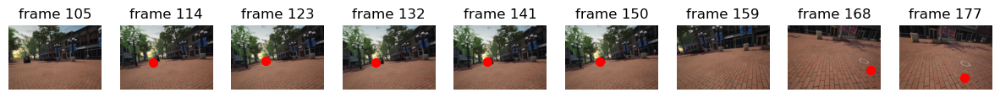

In [16]:
video_path = f'../data/videoclips/P1/P1S3.mp4'
pid=1
print("FOR PERSON", pid, 'in VIDEO=', video_path)

# Get fps and basic info
print('VIDEO=', video_path)
cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
    print('Cannot open', video_path)
else:
    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    duration_sec = frame_count / fps if fps > 0 else None
    width  = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    print(f'FPS={fps}, frames={frame_count}, duration(s)={duration_sec:.2f}, width={width}, height={height}')
# cap.release()

frames = []
for i in [105, 105+9, 105+18, 105+27, 105+36, 105+45, 105+54, 105+63, 105+72]:
    cap.set(cv2.CAP_PROP_POS_FRAMES, int(i))
    ret, frame = cap.read()
    if not ret:
        continue
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    frames.append((int(i), rgb))
    print(f"Read frame {i}, shape={frame.shape}")

fig, axs = plt.subplots(1, len(frames), figsize=(15, 5))
for ax, (i, fr) in zip(axs, frames):
    ax.imshow(fr)
    ax.set_title(f'frame {i}') 
    ax.scatter(
        [meta.iloc[i].loc[['px_v']].values[0]], 
        [meta.iloc[i].loc[['px_u']].values[0]], c='red', s=50) # 左右是对的，上下是颠倒的
    ax.axis('off')
plt.show()

In [19]:
meta.iloc[105:105+73:9]

,timestamp,px_x,px_y,px_u,px_v
105,3.5035,NaN,NaN,NaN,NaN
114,3.8038,1720.722030,763.763500,618.281584,558.187864
123,4.1041,1768.121231,748.772948,593.002010,568.194057
132,4.4044,1724.481552,783.295119,616.276506,545.150508
141,4.7047,1737.259412,773.001592,609.461647,552.021437
150,5.0050,1739.267159,736.877872,608.390848,576.134020
159,5.3053,NaN,NaN,NaN,NaN
168,5.6056,1490.097272,-456.544323,741.281455,1372.743336
177,5.9059,1246.836738,-16.428240,871.020407,1078.965850


[(None, None), (558.187864051609, 618.2815841984373), (568.1940572479375, 593.0020102673708), (545.1505081375373, 616.2765057029862), (552.0214372402374, 609.4616471214576), (576.1340202640849, 608.3908483498848), (None, None), (1372.743335848059, 741.2814547151421), (1078.96585045676, 871.0204065024566)]


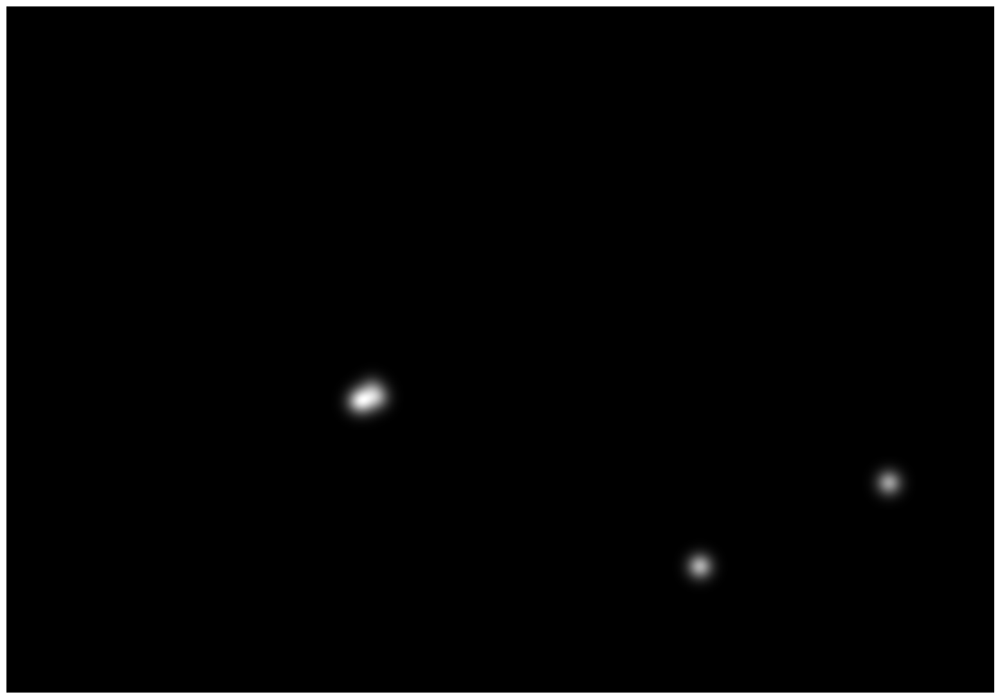

In [36]:
img_shape = (1068, 1536)
frame = 105

gaze_points = list(meta.iloc[105:105+73:9][['px_v', 'px_u']].replace({np.nan: None}).itertuples(index=False, name=None))
print(gaze_points)

S = sequential_gaze_salience_map(img_shape, gaze_points, r=50)

plot_salience_map(S, f'../data/P1S3_{frame}to{frame+72}every{9}.png')

[(None, None), (562.8127244021903, 404.6037533789015), (None, None), (None, None), (556.1381748660675, 585.851712545238), (551.5546947759082, 639.1706214911432), (None, None), (551.6283621195722, 595.2452299370897), (558.7507631561609, 600.3559747564951), (568.1940572479375, 593.0020102673708), (564.175902379213, 613.3992852071385), (547.4800548592214, 600.9727210127661), (539.2735228556487, 604.9997794120305), (545.1505081375373, 616.2765057029862), (546.1355937443643, 628.8678793978414), (549.4404331972322, 622.5062483594683), (545.9130250327947, 616.0271647479286), (547.748595145485, 607.8002545611492), (552.0214372402374, 609.4616471214576), (581.7192733983336, 607.6743436029094), (548.9216606009875, 590.8384629991684), (554.0287504410372, 602.5684353599391), (571.9868808088086, 614.5950962119398), (582.2245297487632, 605.4991354674369), (599.963013416366, 633.1512043423533), (770.1270193572093, 943.3090168249586), (None, None), (None, None), (None, None), (1183.4415507848416, 1033

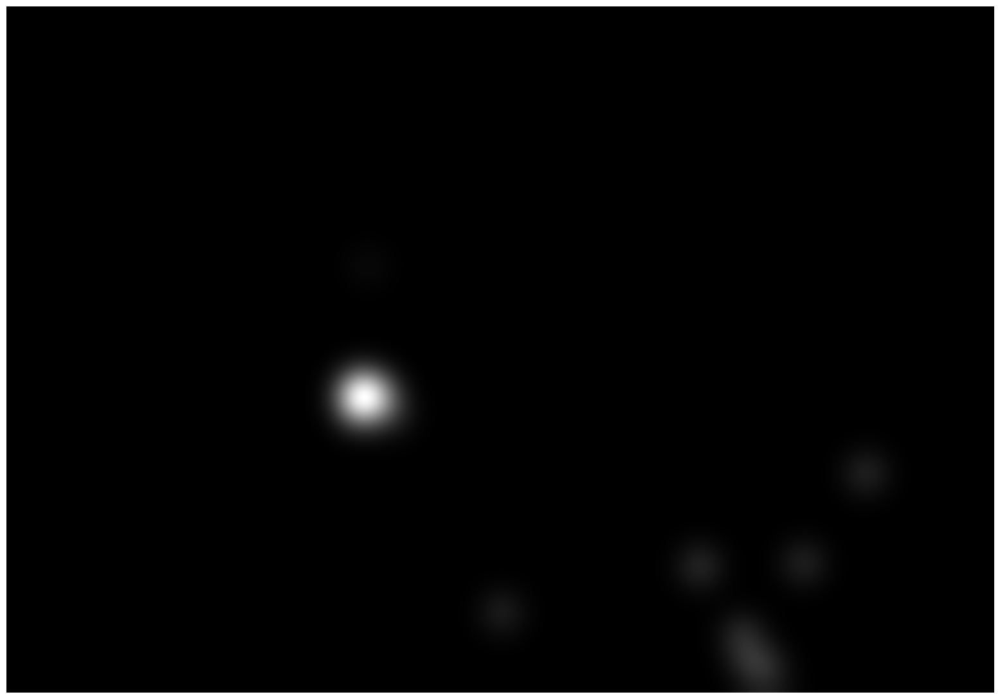

In [172]:
img_shape = (1068, 1536)
frame = 105
every_n = 2

gaze_points = list(meta.iloc[105:105+73:every_n][['px_v', 'px_u']].replace({np.nan: None}).itertuples(index=False, name=None))
print(gaze_points)

S = sequential_gaze_salience_map(img_shape, gaze_points, r=50, sigma=20)

plot_salience_map(S, f'../data/P1S3_{frame}to{frame+72}every{every_n}.png')

[(None, None), (558.187864051609, 618.2815841984373), (568.1940572479375, 593.0020102673708), (545.1505081375373, 616.2765057029862), (552.0214372402374, 609.4616471214576), (576.1340202640849, 608.3908483498848), (None, None), (1372.743335848059, 741.2814547151421), (1078.96585045676, 871.0204065024566)]


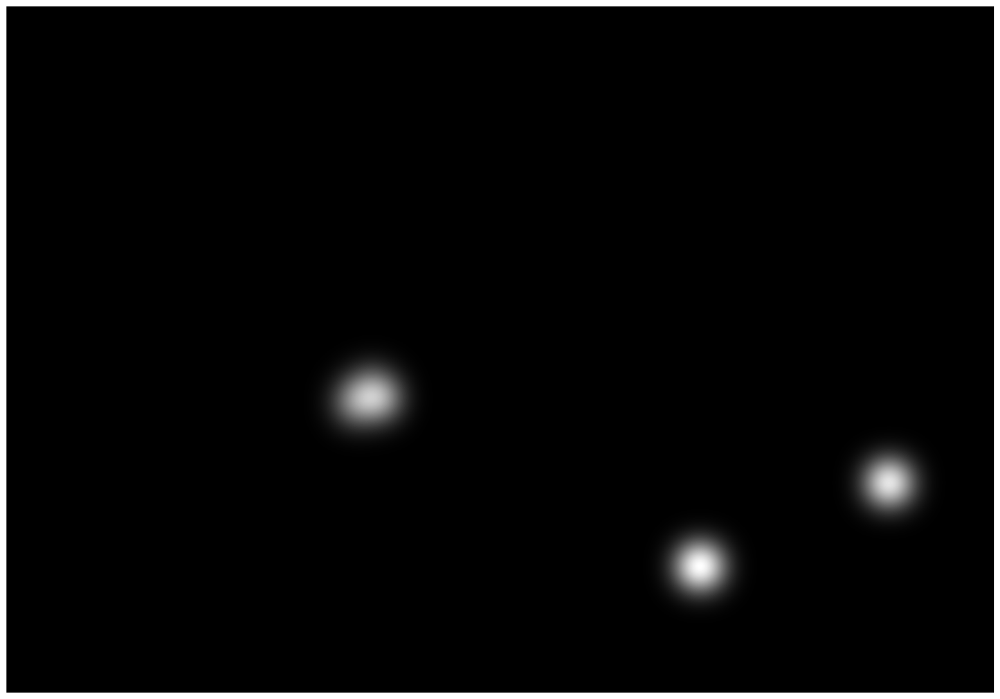

In [45]:
img_shape = (1068, 1536)
frame = 105
every_n = 9

gaze_points = list(meta.iloc[105:105+73:every_n][['px_v', 'px_u']].replace({np.nan: None}).itertuples(index=False, name=None))
print(gaze_points)

S = sequential_gaze_salience_map_max(img_shape, gaze_points, r=50, sigma=20)

plot_salience_map(S, f'../data/P1S3_{frame}to{frame+72}every{every_n}_.png')

In [164]:
import numpy as np
import cv2


def gaze_temporal_map(image_shape, gaze_points, r=30, sigma=10):
    """
    Temporal salience map: encodes old→new gaze progression.
    """
    H, W = image_shape[:2]
    S = np.zeros((H, W), dtype=np.float32)
    n = len(gaze_points)

    # Weight linearly increases with time (newer = brighter)
    weights = np.linspace(0.1, 1.0, n)

    for i, (x, y) in enumerate(gaze_points):
        if x is not None:
            w = weights[i]
            x, y = int(x), int(y)

            yy, xx = np.mgrid[-r:r+1, -r:r+1]
            mask = w * np.exp(-(xx**2 + yy**2) / (2 * sigma**2))

            x1, x2, y1, y2 = x - r, x + r + 1, y - r, y + r + 1
            if x1 < 0 or y1 < 0 or x2 > W or y2 > H:
                continue
            
            # Later fixations overwrite earlier ones
            S_patch = S[y1:y2, x1:x2]

            S[y1:y2, x1:x2] = np.maximum(S_patch, mask)

    # Smooth transitions
    ksize = int(2 * sigma + 1) # more constrast
    S = cv2.GaussianBlur(S, (ksize, ksize), sigma)
    S = cv2.normalize(S, None, 0, 255, cv2.NORM_MINMAX)
    return S.astype(np.uint8)


def gaze_intensity_map(image_shape, gaze_points, r=30, sigma=10):
    """
    Frequency-based salience map: encodes how often gaze falls on each area.
    """
    H, W = image_shape[:2]
    S = np.zeros((H, W), dtype=np.float32)

    for (x, y) in gaze_points:
        if x is not None:
            x, y = int(x), int(y)
            yy, xx = np.mgrid[-r:r+1, -r:r+1]
            mask = np.exp(-(xx**2 + yy**2) / (2 * sigma**2))

            x1, x2, y1, y2 = x - r, x + r + 1, y - r, y + r + 1
            if x1 < 0 or y1 < 0 or x2 > W or y2 > H:
                continue

            S[y1:y2, x1:x2] += mask  # Additive accumulation
            
    ksize = int(6 * sigma + 1)
    S = cv2.GaussianBlur(S, (ksize, ksize), sigma)
    S = cv2.normalize(S, None, 0, 255, cv2.NORM_MINMAX)
    return S.astype(np.uint8)


[(None, None), (562.8127244021903, 404.6037533789015), (None, None), (None, None), (556.1381748660675, 585.851712545238), (551.5546947759082, 639.1706214911432), (None, None), (551.6283621195722, 595.2452299370897), (558.7507631561609, 600.3559747564951), (568.1940572479375, 593.0020102673708), (564.175902379213, 613.3992852071385), (547.4800548592214, 600.9727210127661), (539.2735228556487, 604.9997794120305), (545.1505081375373, 616.2765057029862), (546.1355937443643, 628.8678793978414), (549.4404331972322, 622.5062483594683), (545.9130250327947, 616.0271647479286), (547.748595145485, 607.8002545611492), (552.0214372402374, 609.4616471214576), (581.7192733983336, 607.6743436029094), (548.9216606009875, 590.8384629991684), (554.0287504410372, 602.5684353599391), (571.9868808088086, 614.5950962119398), (582.2245297487632, 605.4991354674369), (599.963013416366, 633.1512043423533), (770.1270193572093, 943.3090168249586), (None, None), (None, None), (None, None), (1183.4415507848416, 1033

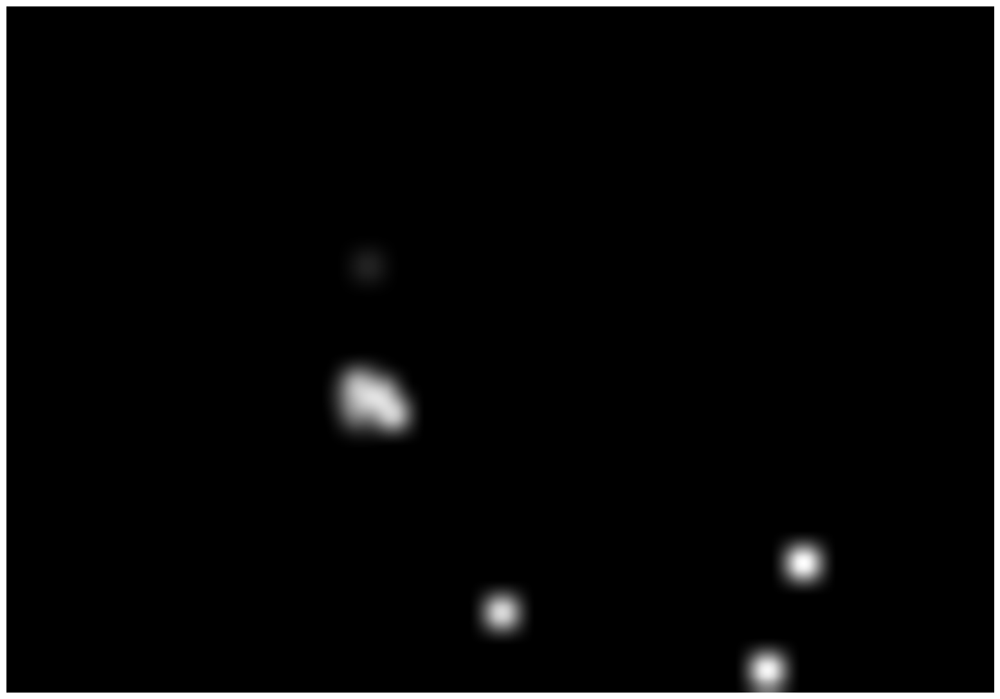

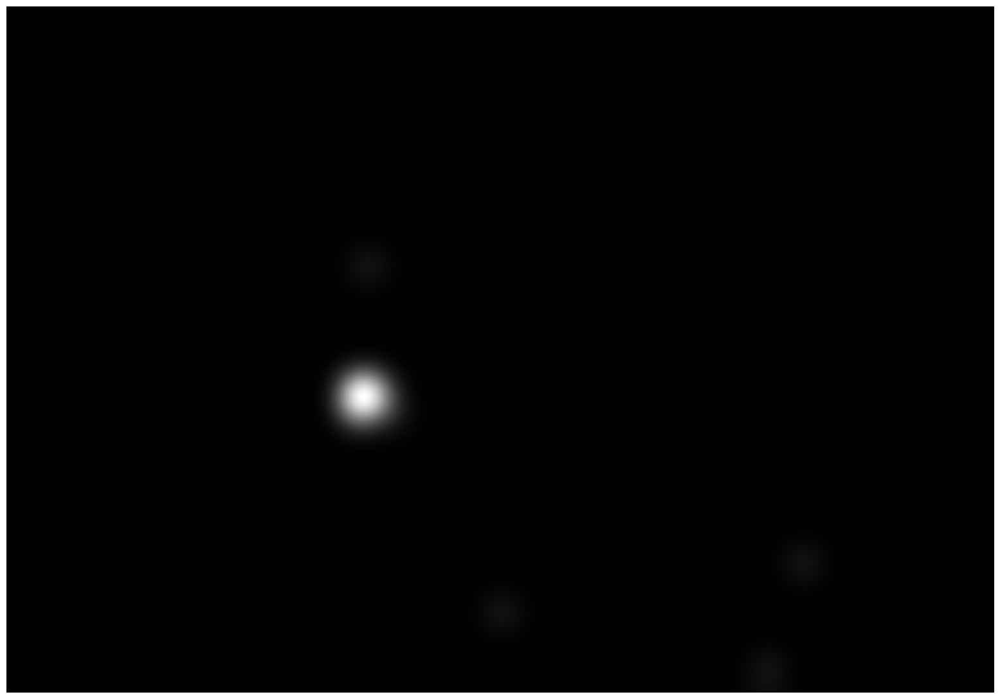

In [197]:
# Example gaze path (from left to right)
img_shape = (1068, 1536)
frame_start = 105
frame_end = 165
every_n = 2

gaze_points = list(meta.iloc[frame_start:frame_end+1:every_n][['px_v', 'px_u']].replace({np.nan: None}).itertuples(index=False, name=None))
print(gaze_points)

S_time = gaze_temporal_map(img_shape, gaze_points, r=30, sigma=20)
S_intensity = gaze_intensity_map(img_shape, gaze_points, r=30, sigma=20)

# fig, axs = plt.subplots(1, 2, figsize=(10, 4))
# axs[0].imshow(S_time, cmap='gray')
# axs[0].set_title("Temporal Sequence Map (Old → New)")
# axs[1].imshow(S_intensity, cmap='gray')
# axs[1].set_title("Frequency Map (Fixation Duration)")
# for ax in axs: ax.axis('off')
# plt.show()

plot_salience_map(S_time, f'../data/P1S3_{frame_start}to{frame_end}every{every_n}_time.png')
plot_salience_map(S_intensity, f'../data/P1S3_{frame_start}to{frame_end}every{every_n}_intensity.png')

0.0 1.0 0.002897528


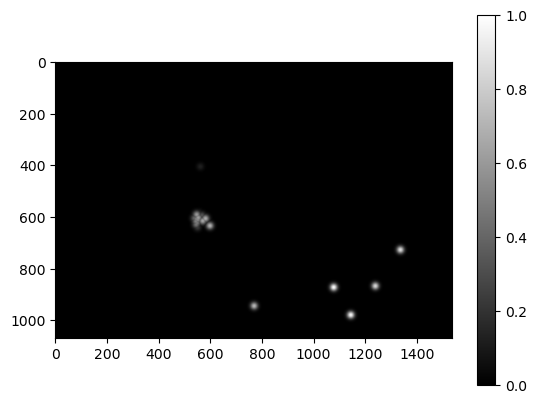

In [151]:
H, W = (1068, 1536)
S = np.zeros((H, W), dtype=np.float32)
n = len(gaze_points)
r = 80

# Weight linearly increases with time (newer = brighter)
weights = np.linspace(0.1, 1.0, n)

for i, (x, y) in enumerate(gaze_points):
    if x is not None:
        w = weights[i]
        x, y = int(x), int(y)

        yy, xx = np.mgrid[-r:r+1, -r:r+1]
        mask = w * np.exp(-(xx**2 + yy**2) / (2 * sigma**2))

        x1, x2, y1, y2 = x - r, x + r + 1, y - r, y + r + 1
        if x1 < 0 or y1 < 0 or x2 > W or y2 > H:
            continue
        
        # Later fixations overwrite earlier ones
        S_patch = S[y1:y2, x1:x2]

        S[y1:y2, x1:x2] = np.maximum(S_patch, mask)
plt.imshow(S, cmap='gray')
plt.colorbar()
plt.clim(0, 1)
print(S.min(), S.max(), S.mean())
# TODO: so weird, why each eye gaze points have sharp boundaries INSTEAD OF gradual gradient?

Before blur: 0.0 1.0 0.002897528
After blur: 0.0 0.74567664 0.0028975285


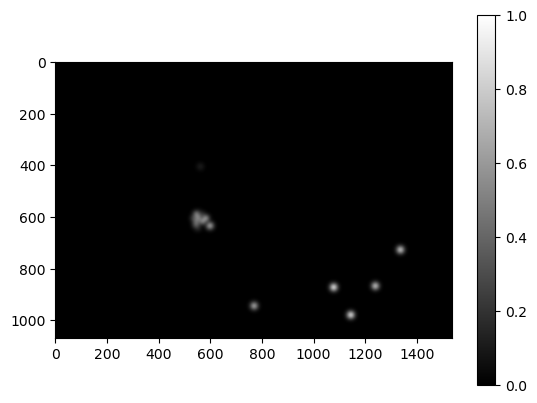

In [152]:
sigma = 10
ksize = int(2 * sigma + 1)
print("Before blur:", S.min(), S.max(), S.mean())
S = cv2.GaussianBlur(S, (ksize, ksize), sigma)
print("After blur:", S.min(), S.max(), S.mean())
plt.imshow(S, cmap='gray')
plt.colorbar()
plt.clim(0, 1)

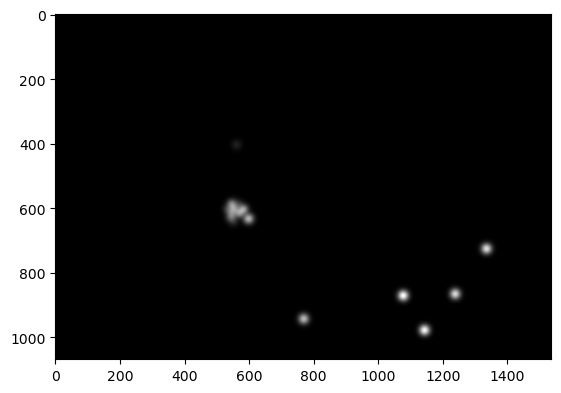

In [153]:
# Smooth transitions
S = cv2.normalize(S, None, 0, 255, cv2.NORM_MINMAX)
plt.imshow(S, cmap='gray')

In [173]:
import pandas as pd

# Example DataFrames
A = pd.DataFrame({
    'timestamp': pd.to_datetime([
        '2024-01-01 12:00:00',
        '2024-01-01 12:00:03',
        '2024-01-01 12:00:07',
        '2024-01-01 12:00:10'
    ]),
    'some_value': [1, 2, 3, 4]
})

B = pd.DataFrame({
    'timestamp': pd.to_datetime([
        '2024-01-01 12:00:00',
        '2024-01-01 12:00:05',
        '2024-01-01 12:00:10'
    ]),
    'feature1': [0.0, 10.0, 20.0],
    'feature2': [1.0, 2.0, 3.0]
})

# Ensure both are sorted by timestamp
A = A.sort_values('timestamp')
B = B.sort_values('timestamp')

# Reindex B’s features to A’s timestamps using interpolation
# 1. Set timestamp as index
B_interp = B.set_index('timestamp')

# 2. Reindex to A’s timestamps
B_interp = B_interp.reindex(A['timestamp']).interpolate(method='time')

# 3. Reset index to merge back
B_interp = B_interp.reset_index(drop=True)

# Combine interpolated features into A
A_interp = pd.concat([A, B_interp], axis=1)

print(A_interp)


            timestamp  some_value  feature1  feature2
0 2024-01-01 12:00:00           1       0.0       1.0
1 2024-01-01 12:00:03           2       6.0       1.6
2 2024-01-01 12:00:07           3      14.0       2.4
3 2024-01-01 12:00:10           4      20.0       3.0


In [174]:
A

,timestamp,some_value
0,2024-01-01 12:00:00,1
1,2024-01-01 12:00:03,2
2,2024-01-01 12:00:07,3
3,2024-01-01 12:00:10,4


In [176]:
B_interp

,feature1,feature2
0,0.0,1.0
1,6.0,1.6
2,14.0,2.4
3,20.0,3.0


In [192]:
import pandas as pd

# Example DataFrames
A = pd.DataFrame({
    'time': [0, 3, 7, 10],
    'some_value': [1, 2, 3, 4]
})

B = pd.DataFrame({
    'time': [0, 5, 10],
    'feature1': [0.0, 30.0, 20.0],
    'feature2': [1.0, 2.5, 3.0]
})

# Ensure sorted by time
A = A.sort_values('time')
B = B.sort_values('time')

# Set B’s time as index
B_interp = B.set_index('time')
B_interp

,feature1,feature2
time,,
0,0.0,1.0
5,30.0,2.5
10,20.0,3.0


In [193]:
B_interp = pd.concat([B_interp, pd.DataFrame(index=A['time'])])
B_interp = B_interp[~B_interp.index.duplicated(keep='first')]
B_interp.sort_index(inplace=True)
B_interp = B_interp.interpolate(method='index')
B_interp

,feature1,feature2
time,,
0,0.0,1.0
3,18.0,1.9
5,30.0,2.5
7,26.0,2.7
10,20.0,3.0


In [194]:
pd.merge(A, B_interp.reset_index(), on='time')

,time,some_value,feature1,feature2
0,0,1,0.0,1.0
1,3,2,18.0,1.9
2,7,3,26.0,2.7
3,10,4,20.0,3.0


### Clip videos

In [ ]:
# check visually 
start = 390.974267
start_s1 = 524.046241
end_s1 = 535.340384

start_time = start
end_time = start + (end_s1 - start_s1)
output_path = f"../data/videoclips/testP{pid}S.mp4"

command = [
    "ffmpeg",
    "-y",
    "-i", f'../data/rawvideos/videos/{filename}.mp4',
    "-ss", str(start_time), # 
    "-to", str(end_time), # 626967, 654767, 682567
    # "-avoid_negative_ts", "1",
    output_path
]

subprocess.run(command, stdout=subprocess.DEVNULL, stderr=subprocess.STDOUT)
print(f"Clipped frames {start_time}–{end_time} saved to {output_path}")

In [ ]:

ffmpeg -i ./data/videoclips/P1/P1S3.mp4 \
  -vf "select='between(n,105,173)',setpts=N/FRAME_RATE/TB" \
  -af "aselect='between(n,105,173)',asetpts=N/SR/TB" \
  clipped.mp4
